**Auteur :** Nizar

# Sommaire

**Préparation**

0. Google Drive et jeu de données
1. Environnement
2. Paramètres
3. Constitution du jeu de données
4. Découpage entraînement (70 %), validation (15 %), test (15 %)
5. Chargement des images
6. Du facile au difficile : la sonde sans réseau
7. Fonctions d'entraînement communes

**Partie I : classification binaire (photo ou autre image)**

* Les trois modèles en un coup d'œil
8. Modèle A : un CNN compact (point de départ)
* Du modèle A au modèle B : ce qui change
9. Modèle B : le même CNN, régularisé, hyperparamètres réglés à la main
10. Modèle C : le même CNN, hyperparamètres cherchés
11. Biais et variance : comparaison des trois modèles
12. Choix du modèle et du seuil
13. Évaluation finale sur le test
14. Robustesse aux dégradations
15. Sauvegarde du modèle binaire et démonstration
* Analyses finales de la première partie et analyse comparative

**Partie II : classification multiclasse (cinq catégories)**

16. Les cinq catégories et leurs poids
17. Modèle E
18. Modèle D
19. Biais, variance et choix du modèle multiclasse
20. Évaluation finale multiclasse sur le test
21. Le classifieur multiclasse comme filtre photo
22. Sauvegarde du modèle multiclasse
23. Tableau récapitulatif
* Tableau comparatif général des cinq modèles
24. Export des résultats pour le rapport

Chaque section se termine par un encadré « Pourquoi ce choix et pas un autre » avec un tableau comparatif des options envisagées.

# Livrable 1 · Entraînement complet des cinq modèles (A, B, C, D, E) et évaluation finale

Ce notebook Colab réunit en un seul endroit **le code de l'équipe** qui a produit les cinq modèles, avec pour chacun **la configuration réellement exécutée** (celle qui a donné les résultats enregistrés, et non celle décrite dans certains textes quand les deux diffèrent). Il exécute ensuite les sections d'évaluation qui n'avaient jamais tourné : comparaison biais-variance en mode prédiction, choix du modèle et du seuil sur la validation, **mesure unique sur le test avec matrices de confusion**, robustesse, sauvegarde et démonstration ; puis la comparaison des modèles multiclasses D et E.

| Partie | Code repris de | Configuration |
|---|---|---|
| Jeu de données, sonde, sections 12 à 17 et 18.3 à 19 | `Livrable_1_Classification_binaire_et_multiclasse_1.ipynb` | inchangée |
| Modèle A | même carnet (cellules 28-30) | CNN sans régularisation, 25 époques, Adam à pas constant 5e-4 (valeur documentée) |
| Modèle B | même carnet (cellule 33) | GroupNormalization, lr 5e-4, dropout 0,5, L2 1e-3, lots de 64, ≤ 50 époques, patience 0 dès l'époque 6 |
| Recherche et modèle C | `..._models_BandC.ipynb` (cellules 37-43) | 24 essais en grille + 12 aléatoires de 12 époques ; C : ≤ 60 époques, patience 2 |
| Modèle E | `Modele_E_classification_multiclasse_colab.ipynb` | lr 7e-4, dropout 0,6, L2 1,5e-3, 128 neurones, lots de 32, ≤ 60 époques, patience 10 dès l'époque 9 |
| Modèle D | `Livrable1_ModeleD.ipynb` (version v3) | BatchNormalization 0,95, lr 2e-4 avec divisions automatiques, ≤ 40 époques |

**Ce qui n'est pas modifié** : images, règles de qualité, découpage, prétraitement, architectures, hyperparamètres, procédures d'entraînement. Aucun transfert d'apprentissage, aucun fine tuning, aucune augmentation de données.

**Ce qui est ajouté, sans changer aucune expérience** : un cache des modèles sur Drive dont le nom dépend de la configuration (une relance reprend là où elle s'est arrêtée, et une configuration modifiée n'est jamais remplacée par un ancien modèle) ; les matrices de confusion de test des trois modèles binaires et des deux modèles multiclasses (le carnet d'origine ne montrait que celle du modèle retenu) ; un export final de tous les résultats pour le rapport.

**Pour exécuter** : Exécution › Modifier le type d'exécution › **GPU T4**, puis Exécution › **Tout exécuter**. Compter environ 1 h 30 à 2 h la première fois (dont un peu plus d'une heure pour les 36 essais de la recherche du modèle C). Si Colab se déconnecte, relancer « Tout exécuter » : les modèles et essais déjà terminés sont relus depuis Drive.

**Reproductibilité** : les graines sont les mêmes que dans les carnets d'origine, mais l'entraînement sur GPU n'est pas parfaitement déterministe ; les chiffres obtenus seront proches des résultats enregistrés, pas identiques au dernier chiffre.

## 0. Google Drive et jeu de données

### Pourquoi ce choix et pas un autre : Google Drive comme stockage

Colab efface tout à chaque déconnexion. On a donc mis les archives, le cache des images et les modèles sur Drive pour ne jamais tout recommencer.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Google Drive monté dans Colab</td><td>persistant, gratuit, déjà lié au compte</td><td>lecture lente la première fois</td><td>oui</td></tr><tr><td>Disque local de Colab</td><td>très rapide</td><td>tout est perdu à la déconnexion</td><td>non</td></tr><tr><td>Téléchargement à chaque session</td><td>rien à stocker</td><td>long et fragile</td><td>non, sauf en secours</td></tr>
</table>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# ==============================================================================
# Jeu de données : montage de Drive, puis localisation ou téléchargement des
# cinq archives brutes (Photo, Painting, Schematics, Sketch, Text) depuis le
# dossier Google Drive partagé par l'utilisateur. Les images nettoyées
# (« selection », qualite.csv) et les modèles entraînés restent sur Drive, dans
# RACINE, pour survivre à une déconnexion du runtime ; les archives brutes,
# elles, sont téléchargées localement (plus rapide) et ne sont nécessaires
# qu'une seule fois, pour construire la sélection.
# ==============================================================================
import subprocess
import sys
from pathlib import Path

try:
    import gdown
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
    import gdown

LIEN_DATASET = "https://drive.google.com/drive/folders/1xiX1baAfoBUKwwRlP-Lknf3i2wpmHkcb?usp=sharing"
ID_DATASET = "1xiX1baAfoBUKwwRlP-Lknf3i2wpmHkcb"

CATEGORIESBRUTES = ["photo", "paint", "schem", "sketch", "text"]
RACINE = Path("/content/drive/MyDrive/Project1_Livrable1")
DOSSIERBRUTLOCAL = Path("/content/donnees_brutes")   # archives téléchargées localement (éphémère, pas gardé sur Drive)


def contientLesCinqCategories(dossier):
    """Vrai si dossier contient directement les cinq catégories (sous-dossiers ou zip)."""
    dossier = Path(dossier)
    if not dossier.is_dir():
        return False
    noms = [s.name.lower() for s in dossier.iterdir() if s.is_dir() or s.suffix.lower() == ".zip"]
    return all(any(c in n for n in noms) for c in CATEGORIESBRUTES)


def trouverDossierCategories(racine, profondeurMax=2):
    """Cherche, depuis racine et jusqu'à profondeurMax sous-niveaux, un dossier contenant les cinq catégories."""
    racine = Path(racine)
    if not racine.is_dir():
        return None
    niveau = [racine]
    for _ in range(profondeurMax + 1):
        for dossier in niveau:
            if contientLesCinqCategories(dossier):
                return dossier
        niveau = [s for dossier in niveau for s in dossier.iterdir() if s.is_dir()]
        if not niveau:
            break
    return None


# 1. Les archives brutes sont-elles déjà accessibles (téléchargées cette session, sur Drive, ou via un raccourci) ?
DOSSIERSOURCE = (trouverDossierCategories(DOSSIERBRUTLOCAL)
                 or trouverDossierCategories(RACINE / "donnees")
                 or trouverDossierCategories(Path("/content/drive/.shortcut-targets-by-id") / ID_DATASET))

# 2. Sinon, la sélection déjà nettoyée est peut-être déjà sur Drive, d'une exécution précédente : pas besoin des
#    archives brutes dans ce cas (la cellule « Constitution du jeu de données » relira qualite.csv directement).
if DOSSIERSOURCE is not None:
    print(f"Images brutes trouvées dans « {DOSSIERSOURCE.resolve()} ».")
elif (RACINE / "donnees" / "selection" / "qualite.csv").exists():
    DOSSIERSOURCE = RACINE / "donnees"
    print("Images brutes absentes, mais la sélection nettoyée existe déjà sur Drive : elle sera utilisée.")
else:
    print("Images brutes introuvables localement : téléchargement depuis le dossier Drive partagé ...")
    DOSSIERBRUTLOCAL.mkdir(parents=True, exist_ok=True)
    try:
        gdown.download_folder(id=ID_DATASET, output=str(DOSSIERBRUTLOCAL), quiet=False,
                              use_cookies=False, resume=True)
    except Exception as erreur:
        raise RuntimeError(
            "Échec du téléchargement du dossier Drive partagé (quota Drive dépassé sur un gros fichier, ou "
            "dossier non accessible). Solution : ouvrir le lien, cliquer sur « Ajouter un raccourci à mon Drive », "
            "le placer dans son propre Drive, puis réexécuter cette cellule (le raccourci sera alors trouvé "
            "directement, sans nouveau téléchargement)."
        ) from erreur
    DOSSIERSOURCE = trouverDossierCategories(DOSSIERBRUTLOCAL)
    if DOSSIERSOURCE is None:
        raise FileNotFoundError(
            f"Le dossier Drive partagé a été téléchargé dans « {DOSSIERBRUTLOCAL.resolve()} », mais aucun "
            f"sous-dossier n'y contient les cinq catégories attendues ({', '.join(CATEGORIESBRUTES)}). Vérifier "
            "le contenu du lien partagé."
        )
    print(f"Images brutes téléchargées dans « {DOSSIERSOURCE.resolve()} ».")

Mounted at /content/drive
Images brutes trouvées dans « /content/drive/MyDrive/Project1_Livrable1/donnees ».


## 1. Environnement

### Pourquoi ce choix et pas un autre : TensorFlow et Keras

Toute l'équipe connaissait déjà Keras, et les rappels (arrêt anticipé, suivi du test) s'écrivent en quelques lignes. PyTorch aurait aussi marché, mais il aurait fallu réécrire la boucle d'entraînement à la main.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>TensorFlow / Keras</td><td>API simple, rappels intégrés, sauvegarde .keras</td><td>moins flexible pour la recherche</td><td>oui</td></tr><tr><td>PyTorch</td><td>très flexible, populaire en recherche</td><td>boucle d'entraînement à écrire soi même</td><td>non</td></tr><tr><td>scikit learn seul</td><td>rapide, simple</td><td>pas de réseaux convolutifs</td><td>seulement pour la sonde et le boosting</td></tr>
</table>

In [2]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # moins de messages techniques de TensorFlow

import gc
import hashlib
import io
import json
import math
import shutil
import threading
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path, PurePosixPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageFilter
from sklearn import metrics
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy import stats

import tensorflow as tf
import keras
from keras import layers, regularizers

tf.get_logger().setLevel("ERROR")
GPU = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")


def precisionMixte():
    """Précision mixte sur GPU, comme dans les carnets d'origine. Remarque : keras.backend.clear_session() remet la
    politique par défaut (float32) ; c'est ce qui s'est produit dans les carnets d'origine après le premier essai de
    la recherche (modèle C) et après la première reprise du modèle D, et ce notebook reproduit ce comportement."""
    if GPU:
        keras.mixed_precision.set_global_policy("mixed_float16")


if GPU:
    precisionMixte()
    print(f"{len(GPU)} GPU détecté(s), précision mixte activée.")
else:
    print(f"Pas de GPU : calcul sur le processeur ({os.cpu_count()} cœurs). Choisir un GPU T4 dans Colab.")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
# entraînement en bleu, validation en rouge, test en vert (convention du rapport)
BLEU, ORANGE, VERT, GRIS, ENCRE = "#2a78d6", "#d62728", "#138a60", "#8a94a3", "#18202c"

TensorFlow 2.21.0 | Keras 3.13.2
1 GPU détecté(s), précision mixte activée.


## 2. Paramètres

Les valeurs ci-dessous sont celles des exécutions qui ont produit les résultats enregistrés. Quand le texte d'un carnet décrivait une autre valeur, le commentaire le signale.

### Pourquoi ce choix et pas un autre : des paramètres regroupés et une graine fixe

Tous les réglages sont dans une seule cellule pour qu'on puisse relire d'un coup d'œil la configuration exécutée. La graine 42 fixe les tirages, même si le GPU garde une petite part de hasard.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Une cellule unique de paramètres</td><td>lisible, facile à comparer entre modèles</td><td>cellule longue</td><td>oui</td></tr><tr><td>Valeurs écrites dans chaque section</td><td>proche du code</td><td>oublis et incohérences faciles</td><td>non</td></tr><tr><td>Fichier de configuration externe</td><td>propre en production</td><td>un fichier de plus à gérer sur Colab</td><td>non</td></tr>
</table>

In [20]:
GRAINE = 42                    # même tirage et mêmes initialisations à chaque exécution

# Jeu de données
NPHOTOS = 3000                 # photos retenues
NPARAUTRE = 750                # images retenues par autre catégorie (peinture, schéma, dessin, texte)
CANDIDATSPHOTO = None          # photos examinées (None : toutes)
CANDIDATSAUTRES = 2500         # images examinées par autre catégorie, tirées au hasard
COTEEXPORT = 512               # côté maximal des images nettoyées enregistrées dans donnees/selection

# Images données aux réseaux
TAILLE = 224                   # tests de robustesse seulement (réduites ensuite à TAILLECNN)
TAILLECNN = 128                # tous les modèles
LOT = 64                       # images par pas pour les prédictions

# Découpage
PARTVALIDATION = 0.15
PARTTEST = 0.15

# Modèle A : témoin sans régularisation (carnet principal). Le texte et le carnet « fullrun » donnent 5e-4 ;
# la cellule de paramètres sauvegardée du carnet principal indiquait 5e-5. La valeur documentée est utilisée.
# Modèle A : CNN compact, sans couche dense (point de départ). Même protocole d'entraînement que B et C
# (GroupNormalization, moyenne mobile des poids, arrêt anticipé) ; seule la capacité du réseau diffère.
EPOQUESA, PATIENCEA, DEBUTARRETA = 50, 10, 5
HPA = {"lr": 5e-4, "dropout": 0.3, "l2": 1e-4, "neurones": 0, "filtres": 16, "lot": 64,
       "multiples": (1, 2, 4, 8)}   # 16, 32, 64 et 128 filtres ; neurones = 0 : pas de couche dense

# Modèle B : configuration exécutée (journal de la cellule 33 du carnet principal)
HPB = {"lr": 5e-4, "dropout": 0.5, "l2": 1e-3, "neurones": 128, "filtres": 32, "lot": 64}
EPOQUESB, PATIENCEB, DEBUTARRETB = 50, 0, 5

# Modèle C : recherche puis entraînement final (carnet B et C)
EPOQUESESSAI = 12              # durée réelle de chaque essai (le texte disait 8)
EPOQUESRECHERCHE = 8           # sert, comme dans le code d'origine, au calcul de l'« époque retenue » des essais
GRILLE = {"lr": [5e-4, 2e-3], "dropout": [0.3, 0.5, 0.6, 0.7], "neurones": [128, 256, 512]}
GRILLEFIXE = {"l2": 5e-4, "filtres": 32, "lot": 32}
ESSAISALEATOIRES = 12          # min(12, 24) dans le carnet B et C
EPOQUESC, PATIENCEC, DEBUTARRETC = 60, 2, 5

# Modèle E : configuration du carnet du modèle E (valeurs par défaut de ce carnet, utilisées lors de son exécution)
HPE = {"lr": 7e-4, "dropout": 0.6, "l2": 1.5e-3, "neurones": 128, "filtres": 32, "lot": 32}
EPOQUESE, PATIENCEE, DEBUTARRETE = 60, 10, 8

# Modèle D : configuration du carnet du modèle D (version v3)
HPD = {"lr": 2e-4, "dropout": 0.45, "l2": 3e-4, "neurones": 128, "filtres": 32, "convs": 1, "lot": 64,
       "taille": TAILLECNN}
INERTIEBND = 0.95              # inertie de la BatchNormalization
EPOQUESD, PATIENCED, DEBUTARRETD = 40, 10, 5
SEUILZIGZAG = 3                # remontées brusques tolérées avant de diviser le pas par deux
REESSAISZIGZAG = 2             # reprises au plus
ECHAUFFEMENTD = 5              # époques de montée du pas
PLANCHERPAS = 1e-6             # pas minimal en fin de cosinus
CLIPNORMD = 0.5

# Reprise : les modèles et essais terminés sont relus depuis Drive (nom de fichier lié à la configuration)
REUTILISER = True

# Dossiers sur Drive (RACINE et DOSSIERSOURCE viennent de la cellule 0)
DOSSIERSELECTION = RACINE / "donnees" / "selection"
DOSSIERTRAVAIL = RACINE / "resultats_reproduction"   # dossier neuf : aucun ancien modèle n'y est relu par erreur
DOSSIERSELECTION.mkdir(parents=True, exist_ok=True)
DOSSIERTRAVAIL.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(GRAINE)
print("Résultats enregistrés dans", DOSSIERTRAVAIL)

Résultats enregistrés dans /content/drive/MyDrive/Project1_Livrable1/resultats_reproduction


## 3. Constitution du jeu de données

Mesure de chaque image candidate, règles de qualité par catégorie, tirage de 3 000 photos et de 750 images de chaque autre catégorie, puis réenregistrement en JPEG sur fond blanc (code inchangé du carnet principal). Si `qualite.csv` existe déjà sur Drive, les mesures sont relues.

### Pourquoi ce choix et pas un autre : le jeu de données (3 000 photos, 750 par autre catégorie)

On voulait autant de photos que d'autres images pour que la tâche binaire soit équilibrée (3 000 contre 4 × 750). Des règles de qualité par catégorie enlèvent les images floues, trop sombres ou presque vides, qui auraient appris du bruit au réseau.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Équilibre 3 000 / 3 000 avec filtrage qualité</td><td>classes équilibrées, images propres</td><td>moins d'images au total</td><td>oui</td></tr><tr><td>Toutes les images disponibles</td><td>plus de données</td><td>classes très déséquilibrées, images de mauvaise qualité</td><td>non</td></tr><tr><td>Rééquilibrage par poids seulement</td><td>garde tout</td><td>le bruit reste dans les données</td><td>non pour le binaire, oui en complément pour le multiclasse</td></tr>
</table>

In [4]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
CATEGORIESARCHIVES = [("photo", "Photo"), ("paint", "Peinture"), ("schem", "Schéma"), ("sketch", "Dessin"), ("text", "Texte")]
DOSSIERSSELECTION = {"Photo": "photo", "Peinture": "peinture", "Schéma": "schema", "Dessin": "dessin", "Texte": "texte"}


def categorieArchive(nom):
    """Catégorie française d'une archive d'après son nom (Dataset Livrable 1 Photo.zip devient Photo)."""
    for motCle, categorie in CATEGORIESARCHIVES:
        if motCle in nom.lower():
            return categorie
    raise ValueError(f"Catégorie inconnue pour l'archive {nom}")


def sourcesImages(dossier):
    """Archives zip ou dossiers d'images dont le nom désigne une catégorie connue."""
    return sorted(s for s in Path(dossier).iterdir()
                  if (s.is_dir() or s.suffix.lower() == ".zip")
                  and any(motCle in s.name.lower() for motCle, _ in CATEGORIESARCHIVES))


def listerCandidats(dossierDonnees, maxPhotos, maxAutres, graine):
    """Images candidates de chaque archive. On tire au hasard au plus maxPhotos photos et maxAutres images
    de chaque autre catégorie (None pour tout garder)."""
    lignes = []
    for archive in sourcesImages(dossierDonnees):
        categorie = categorieArchive(archive.name)
        if archive.is_dir():
            membres = sorted(f.relative_to(archive).as_posix() for f in archive.rglob("*")
                             if f.suffix.lower() in EXTENSIONS and not f.name.startswith("."))
        else:
            with zipfile.ZipFile(archive) as contenu:
                membres = sorted(m for m in contenu.namelist()
                                 if PurePosixPath(m).suffix.lower() in EXTENSIONS and "MACOSX" not in m
                                 and not PurePosixPath(m).name.startswith("."))
        limite = maxPhotos if categorie == "Photo" else maxAutres
        if limite and len(membres) > limite:
            hasard = np.random.default_rng(graine)
            membres = sorted(hasard.choice(membres, limite, replace=False).tolist())
        lignes += [{"archive": archive.name, "membre": m, "categorie": categorie} for m in membres]
    return pd.DataFrame(lignes)


ARCHIVESOUVERTES = threading.local()


def lireMembre(dossierDonnees, archive, membre):
    """Octets d'une image dans une archive. Chaque fil garde ses archives ouvertes."""
    chemin = Path(dossierDonnees) / archive
    if chemin.is_dir():
        return (chemin / membre).read_bytes()
    ouvertes = ARCHIVESOUVERTES.__dict__.setdefault("archives", {})
    if archive not in ouvertes:
        ouvertes[archive] = zipfile.ZipFile(Path(dossierDonnees) / archive)
    return ouvertes[archive].read(membre)


def enRGBFondBlanc(image):
    """Convertit en RGB ; les zones transparentes deviennent blanches au lieu de noires."""
    if image.mode in ("RGBA", "LA") or (image.mode == "P" and "transparency" in image.info):
        fond = Image.new("RGBA", image.size, (255, 255, 255, 255))
        return Image.alpha_composite(fond, image.convert("RGBA")).convert("RGB")
    return image.convert("RGB")


def empreinteVisuelle(gris):
    """Empreinte de 64 bits (dHash) : deux images presque identiques ont presque la même empreinte."""
    petit = np.asarray(Image.fromarray(gris.astype(np.uint8)).resize((9, 8), Image.BILINEAR), dtype=np.int16)
    bits = (petit[:, 1:] > petit[:, :-1]).ravel()
    return format(int("".join("1" if b else "0" for b in bits), 2), "016x")


def mesurerImage(octets):
    """Mesures de qualité d'une image, calculées sur un aperçu de 256 pixels de côté au plus."""
    with Image.open(io.BytesIO(octets)) as image:
        largeur, hauteur = image.size
        formatFichier = image.format
        image.draft("RGB", (512, 512))
        apercu = enRGBFondBlanc(image)
    apercu.thumbnail((256, 256), Image.BILINEAR)
    rgb = np.asarray(apercu, dtype=np.int16)
    gris = np.asarray(apercu.convert("L"), dtype=np.float32)
    laplacien = 4 * gris[1:-1, 1:-1] - gris[:-2, 1:-1] - gris[2:, 1:-1] - gris[1:-1, :-2] - gris[1:-1, 2:]
    return {
        "largeur": largeur, "hauteur": hauteur, "format": formatFichier,
        "luminosite": float(gris.mean()),
        "contraste": float(gris.std()),
        "nettete": float(laplacien.var()),
        "saturation": float((rgb.max(axis=2) - rgb.min(axis=2)).mean() / 255),
        "zonesUniformes": float(((gris > 245) | (gris < 10)).mean()),
        "encre": float((gris < 128).mean()),
        "empreinte": empreinteVisuelle(gris),
        "md5": hashlib.md5(octets).hexdigest(),
    }


def mesurerCandidats(candidats, dossierDonnees, fils=4):
    """Mesure toutes les candidates en parallèle. Une image illisible reçoit lisible = False."""
    def mesurer(ligne):
        try:
            return {"lisible": True, **mesurerImage(lireMembre(dossierDonnees, ligne.archive, ligne.membre))}
        except Exception:
            return {"lisible": False}
    with ThreadPoolExecutor(fils) as executeur:
        mesures = list(executeur.map(mesurer, candidats.itertuples(index=False), chunksize=64))
    return pd.concat([candidats.reset_index(drop=True), pd.DataFrame(mesures)], axis=1)

In [5]:
# Règles de qualité par catégorie : (colonne, minimum, maximum). None = pas de limite.
REGLES = {
    "Photo":    {"minCote": (300, None), "ratio": (None, 2.0), "luminosite": (55, 200), "contraste": (30, None),
                 "nettete": (250, None), "zonesUniformes": (None, 0.25)},
    "Peinture": {"minCote": (300, None), "ratio": (None, 2.5), "luminosite": (40, 215), "contraste": (25, None),
                 "saturation": (0.05, None), "zonesUniformes": (None, 0.30)},
    "Schéma":   {"minCote": (200, None), "ratio": (None, 3.0), "contraste": (15, None), "zonesUniformes": (0.30, None)},
    "Dessin":   {"minCote": (300, None), "contraste": (15, None)},
    "Texte":    {"minCote": (300, None), "contraste": (15, None)},
}
NOMSREGLES = {"minCote": "trop petite", "ratio": "trop allongée", "luminosite": "trop sombre ou trop claire",
              "contraste": "contraste trop faible", "nettete": "floue", "saturation": "presque sans couleur",
              "zonesUniformes": "zones uniformes (cadre, fond, nuit)"}
EMPREINTEFIABLE = {"Photo", "Peinture", "Schéma"}


def appliquerFiltres(mesures):
    """Ajoute la colonne rejet : vide si l'image est gardée, sinon la première raison du rejet."""
    m = mesures.copy()
    m["minCote"] = m[["largeur", "hauteur"]].min(axis=1)
    m["ratio"] = m[["largeur", "hauteur"]].max(axis=1) / m["minCote"].clip(lower=1)
    m["rejet"] = np.where(m["lisible"], "", "illisible")
    for categorie, regles in REGLES.items():
        for colonne, (bas, haut) in regles.items():
            hors = (m["categorie"] == categorie) & (m["rejet"] == "") & (
                m[colonne].isna() | ((m[colonne] < bas) if bas is not None else False)
                | ((m[colonne] > haut) if haut is not None else False))
            m.loc[hors, "rejet"] = NOMSREGLES[colonne]
    garde = m["rejet"] == ""
    m.loc[garde & m.duplicated("md5"), "rejet"] = "doublon exact"
    garde = m["rejet"] == ""
    fiable = m["categorie"].isin(EMPREINTEFIABLE)
    doublons = m[garde & fiable].duplicated("empreinte").reindex(m.index, fill_value=False)
    m.loc[doublons, "rejet"] = "quasi doublon"
    return m


def tirerSelection(filtrees, nPhotos, nParAutre, graine):
    """Tire au hasard nPhotos photos et nParAutre images de chaque autre catégorie parmi les images gardées."""
    morceaux = []
    for categorie, lot in filtrees[filtrees["rejet"] == ""].groupby("categorie"):
        n = nPhotos if categorie == "Photo" else nParAutre
        if len(lot) < n:
            raise ValueError(f"{categorie} : seulement {len(lot)} images de bonne qualité pour {n} demandées.")
        morceaux.append(lot.sample(n, random_state=graine))
    selection = pd.concat(morceaux).sort_values(["categorie", "membre"]).reset_index(drop=True)
    selection["fichier"] = [f"{DOSSIERSSELECTION[c]}/{PurePosixPath(m).stem}.jpg"
                            for c, m in zip(selection["categorie"], selection["membre"])]
    if selection["fichier"].duplicated().any():
        raise ValueError("Deux images sélectionnées auraient le même nom de fichier.")
    selection["classe"] = (selection["categorie"] == "Photo").astype(int)
    return selection


def exporterSelection(selection, dossierDonnees, dossierSelection, cote=512, fils=4):
    """Écrit chaque image retenue, nettoyée : RGB sur fond blanc, cote pixels au plus, JPEG de qualité 92.
    Toutes les catégories ont ainsi le même format de fichier. Les images déjà écrites sont sautées."""
    def exporter(ligne):
        cible = Path(dossierSelection) / ligne.fichier
        if cible.exists():
            return
        cible.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(io.BytesIO(lireMembre(dossierDonnees, ligne.archive, ligne.membre))) as image:
            image.draft("RGB", (2 * cote, 2 * cote))
            propre = enRGBFondBlanc(image)
        propre.thumbnail((cote, cote), Image.LANCZOS)
        temporaire = cible.with_suffix(".tmp")
        propre.save(temporaire, "JPEG", quality=92)
        temporaire.replace(cible)
    with ThreadPoolExecutor(fils) as executeur:
        list(executeur.map(exporter, selection.itertuples(index=False)))

In [6]:
debut = time.time()
fichierQualite = DOSSIERSELECTION / "qualite.csv"
if fichierQualite.exists():
    mesures = pd.read_csv(fichierQualite, dtype={"md5": str, "empreinte": str})
    print(f"Mesures de qualité relues depuis {fichierQualite}.")
else:
    if not sourcesImages(DOSSIERSOURCE):
        raise FileNotFoundError(f"Aucun dossier d'images dans « {DOSSIERSOURCE.resolve()} ».")
    candidats = listerCandidats(DOSSIERSOURCE, CANDIDATSPHOTO, CANDIDATSAUTRES, GRAINE)
    mesures = mesurerCandidats(candidats, DOSSIERSOURCE)
    DOSSIERSELECTION.mkdir(parents=True, exist_ok=True)
    mesures.to_csv(fichierQualite, index=False)
    print(f"{len(mesures)} images mesurées en {time.time() - debut:.0f} s.")

filtrees = appliquerFiltres(mesures)
selection = tirerSelection(filtrees, NPHOTOS, NPARAUTRE, GRAINE)
manquantes = selection[[not (DOSSIERSELECTION / f).exists() for f in selection["fichier"]]]
if len(manquantes):
    print(f"Écriture de {len(manquantes)} images nettoyées dans {DOSSIERSELECTION} ...")
    exporterSelection(manquantes, DOSSIERSOURCE, DOSSIERSELECTION, COTEEXPORT)
selection.to_csv(DOSSIERSELECTION / "selection.csv", index=False)

bilan = pd.crosstab(filtrees["rejet"].replace("", "gardée"), filtrees["categorie"], margins=True, margins_name="total")
bilan = bilan.loc[["gardée"] + sorted(i for i in bilan.index if i not in ("gardée", "total")) + ["total"]]
print("Images candidates examinées, gardées ou écartées (avec la raison) :")
display(bilan)
print("Jeu retenu :")
display(selection.groupby(["categorie", "classe"]).size().rename("images").reset_index())

Mesures de qualité relues depuis /content/drive/MyDrive/Project1_Livrable1/donnees/selection/qualite.csv.
Images candidates examinées, gardées ou écartées (avec la raison) :


categorie,Dessin,Peinture,Photo,Schéma,Texte,total
rejet,,,,,,
gardée,1397,2085,8564,1353,2401,15800
contraste trop faible,9,90,239,71,99,508
doublon exact,0,0,0,13,0,13
floue,0,0,401,0,0,401
presque sans couleur,0,189,0,0,0,189
quasi doublon,0,0,1,14,0,15
trop allongée,0,14,17,153,0,184
trop petite,0,10,136,441,0,587
trop sombre ou trop claire,0,90,354,0,0,444


Jeu retenu :


,categorie,classe,images
0,Dessin,0,750
1,Peinture,0,750
2,Photo,1,3000
3,Schéma,0,750
4,Texte,0,750


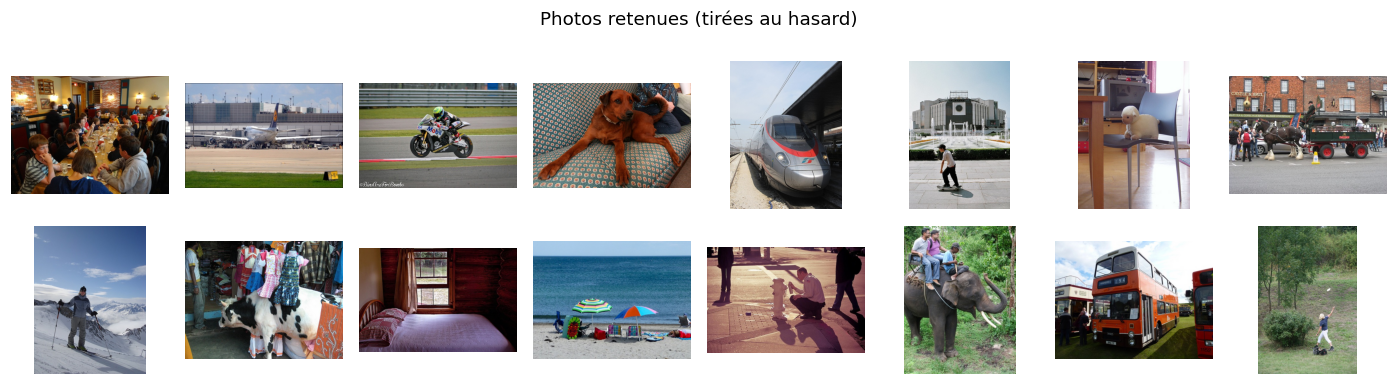

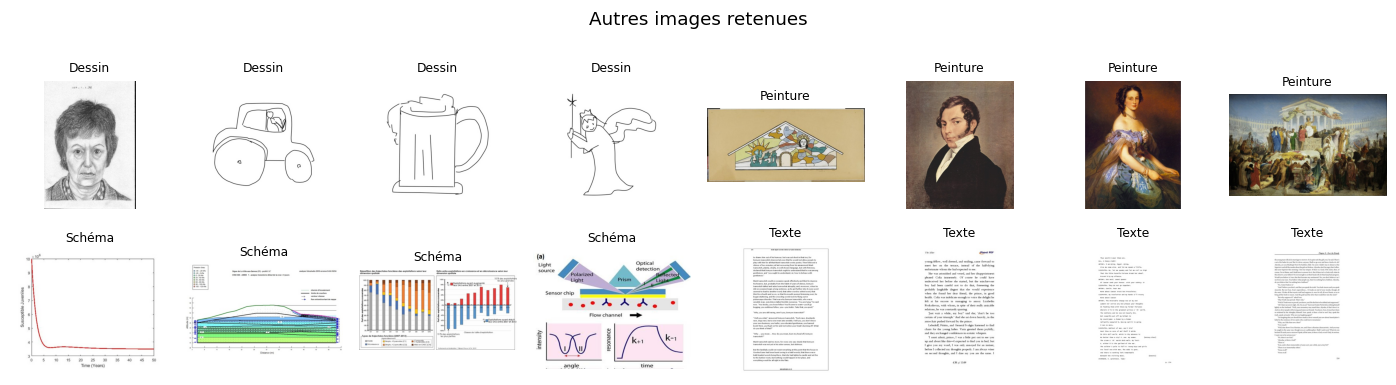

,images,largeurMediane,hauteurMediane,partGrises,saturationMoyenne,luminositeMoyenne,netteteMediane
categorie,,,,,,,
Dessin,750,1111.0,1111.0,0.968,0.002,234.249,1357.582
Peinture,750,811.0,803.5,0.000,0.187,118.058,714.228
Photo,3000,640.0,480.0,0.035,0.144,114.737,980.794
Schéma,750,816.5,568.0,0.533,0.057,210.188,2133.873
Texte,750,595.0,842.0,1.000,0.000,243.680,1691.144


Photos en noir et blanc gardées : 3.5% des photos.


In [7]:
def planche(fichiers, titres=None, colonnes=8, cote=1.6, titre=None):
    """Affiche une grille d'images du dossier de sélection."""
    rangees = int(np.ceil(len(fichiers) / colonnes))
    fig, axes = plt.subplots(rangees, colonnes, figsize=(colonnes * cote, rangees * cote * 1.08), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for k, (ax, f) in enumerate(zip(axes.ravel(), fichiers)):
        with Image.open(DOSSIERSELECTION / f) as image:
            ax.imshow(image.convert("RGB"))
        if titres is not None:
            ax.set_title(titres[k], fontsize=8)
    if titre:
        fig.suptitle(titre, y=1.0)
    plt.tight_layout()
    plt.show()


exemplesPhotos = selection[selection["classe"] == 1].sample(16, random_state=GRAINE)
planche(exemplesPhotos["fichier"].tolist(), titre="Photos retenues (tirées au hasard)")
exemplesAutres = selection[selection["classe"] == 0].groupby("categorie").sample(4, random_state=GRAINE)
planche(exemplesAutres["fichier"].tolist(), exemplesAutres["categorie"].tolist(), titre="Autres images retenues")

profil = selection.assign(grise=selection["saturation"] < 0.02).groupby("categorie").agg(
    images=("fichier", "size"), largeurMediane=("largeur", "median"), hauteurMediane=("hauteur", "median"),
    partGrises=("grise", "mean"), saturationMoyenne=("saturation", "mean"), luminositeMoyenne=("luminosite", "mean"),
    netteteMediane=("nettete", "median")).round(3)
display(profil)
print(f"Photos en noir et blanc gardées : {profil.loc['Photo', 'partGrises']:.1%} des photos.")

## 4. Découpage entraînement (70 %), validation (15 %), test (15 %)

Stratifié par catégorie. La validation sert à toutes les décisions ; le test est mesuré à chaque époque uniquement pour tracer ses courbes, et utilisé une seule fois pour l'évaluation finale.

### Pourquoi ce choix et pas un autre : le découpage 70 / 15 / 15 stratifié

Le découpage stratifié garde la même proportion de chaque catégorie dans les trois jeux. La validation sert à toutes les décisions et le test n'est utilisé qu'une fois à la fin, sinon il ne mesurerait plus rien d'honnête.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>70 / 15 / 15 stratifié</td><td>test vraiment indépendant, proportions identiques</td><td>moins d'images pour entraîner</td><td>oui</td></tr><tr><td>80 / 20 sans validation</td><td>plus de données d'entraînement</td><td>on choisirait le modèle sur le test</td><td>non</td></tr><tr><td>Validation croisée à 5 plis</td><td>estimation plus stable</td><td>5 fois plus de calcul pour des CNN</td><td>non</td></tr>
</table>

In [8]:
indices = np.arange(len(selection))
idxEntr, idxReste = train_test_split(indices, test_size=PARTVALIDATION + PARTTEST,
                                     stratify=selection["categorie"], random_state=GRAINE)
idxVal, idxTest = train_test_split(idxReste, test_size=PARTTEST / (PARTVALIDATION + PARTTEST),
                                   stratify=selection["categorie"].iloc[idxReste], random_state=GRAINE)
selection["jeu"] = ""
selection.loc[idxEntr, "jeu"] = "entraînement"
selection.loc[idxVal, "jeu"] = "validation"
selection.loc[idxTest, "jeu"] = "test"
selection.to_csv(DOSSIERTRAVAIL / "decoupage.csv", index=False)
display(pd.crosstab(selection["categorie"], selection["jeu"], margins=True, margins_name="total")
        [["entraînement", "validation", "test", "total"]])

jeu,entraînement,validation,test,total
categorie,,,,
Dessin,525,112,113,750
Peinture,525,113,112,750
Photo,2100,450,450,3000
Schéma,525,112,113,750
Texte,525,113,112,750
total,4200,900,900,6000


## 5. Chargement des images

Chaque image est convertie en RGB sur fond blanc et redimensionnée en 128 × 128 (tous les modèles) et en 224 × 224 (tests de robustesse). Les tableaux sont mis en cache sur Drive (comme dans le carnet B et C) : la première lecture depuis Drive est lente, les suivantes prennent quelques secondes.

### Pourquoi ce choix et pas un autre : des images de 128 × 128 pixels

128 pixels suffisent pour voir la texture et les couleurs qui distinguent une photo d'une peinture, tout en gardant un entraînement de quelques minutes. Le 224 × 224 n'est gardé que pour les tests de robustesse.

<table>
<tr><th>Taille</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>64 × 64</td><td>très rapide</td><td>perd les détails de texture</td><td>non</td></tr><tr><td>128 × 128</td><td>bon compromis détail / temps</td><td>certains détails fins perdus</td><td>oui</td></tr><tr><td>224 × 224</td><td>plus de détails</td><td>environ 3 fois plus de calcul et de mémoire</td><td>seulement pour la robustesse</td></tr>
</table>

In [9]:
def preparerImage(chemin, taille):
    """Prétraitement de référence, le même en production : RGB sur fond blanc, carré de taille pixels."""
    with Image.open(chemin) as image:
        image = enRGBFondBlanc(image)
        return np.asarray(image.resize((taille, taille), Image.BILINEAR), dtype=np.uint8)


def chargerDeuxTailles(fichier):
    chemin = DOSSIERSELECTION / fichier
    return preparerImage(chemin, TAILLE), preparerImage(chemin, TAILLECNN)


cle = hashlib.md5((",".join(selection["fichier"]) + f"|{TAILLE}|{TAILLECNN}").encode()).hexdigest()[:10]
fichier224, fichier128 = DOSSIERTRAVAIL / f"X224_{cle}.npy", DOSSIERTRAVAIL / f"X128_{cle}.npy"
debut = time.time()
if fichier224.exists() and fichier128.exists():
    X224, X128 = np.load(fichier224), np.load(fichier128)
    print(f"{len(X128)} images relues depuis le cache en {time.time() - debut:.0f} s.")
else:
    with ThreadPoolExecutor(8) as executeur:
        paires = list(executeur.map(chargerDeuxTailles, selection["fichier"]))
    X224 = np.stack([p[0] for p in paires])
    X128 = np.stack([p[1] for p in paires])
    del paires
    np.save(fichier224, X224)
    np.save(fichier128, X128)
    print(f"{len(X128)} images chargées en {time.time() - debut:.0f} s et mises en cache.")
print(f"{(X224.nbytes + X128.nbytes) / 1e9:.2f} Go en mémoire.")

y = selection["classe"].to_numpy().astype("float32")
categories = selection["categorie"].to_numpy()
yEntr, yVal, yTest = y[idxEntr], y[idxVal], y[idxTest]
IMAGES = {TAILLECNN: tf.constant(X128)}


def jeuTF(taille, indices, etiquettes, lot=LOT, melanger=False, poids=None):
    """Lots (images, étiquettes[, poids]) pour Keras. Les images sont prises par leur numéro dans IMAGES[taille]
    et converties en réels au vol."""
    images = IMAGES[taille]
    morceaux = (np.asarray(indices), np.asarray(etiquettes))
    if poids is not None:
        morceaux += (np.asarray(poids, dtype="float32"),)
    donnees = tf.data.Dataset.from_tensor_slices(morceaux)
    if melanger:
        donnees = donnees.shuffle(len(indices), seed=GRAINE, reshuffle_each_iteration=True)

    def charger(numeros, *reste):
        return (tf.cast(tf.gather(images, numeros), tf.float32),) + reste

    return donnees.batch(lot).map(charger, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


jeuVal128 = jeuTF(TAILLECNN, idxVal, yVal)
jeuTest128 = jeuTF(TAILLECNN, idxTest, yTest)

6000 images chargées en 612 s et mises en cache.
1.20 Go en mémoire.


## 6. Du facile au difficile : la sonde sans réseau

Dix-neuf mesures de couleur, de lumière et de texture par image, puis une régression logistique (code inchangé). Ces mesures servent aussi aux courbes de validation et d'apprentissage de la section 12.

### Pourquoi ce choix et pas un autre : commencer par une sonde sans réseau

Avant de lancer un CNN, on voulait savoir si de simples mesures de couleur et de texture suffisaient déjà. Cette sonde donne un point de repère : si un réseau ne fait pas mieux, il ne sert à rien.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Régression logistique sur 19 mesures</td><td>rapide, interprétable, sert de repère</td><td>ne voit pas les formes</td><td>oui, comme référence</td></tr><tr><td>Passer directement au CNN</td><td>gain de temps</td><td>aucun repère pour juger le CNN</td><td>non</td></tr><tr><td>SVM sur pixels bruts</td><td>classique</td><td>lent et peu efficace sur des images</td><td>non</td></tr>
</table>

In [10]:
def caracteristiquesManuelles(images, morceau=500):
    """Une vingtaine de mesures de couleur, de lumière et de texture par image (tableau uint8, n × h × l × 3)."""
    resultats = []
    for depart in range(0, len(images), morceau):
        x = images[depart:depart + morceau].astype(np.float32) / 255
        r, v, b = x[..., 0], x[..., 1], x[..., 2]
        gris = 0.299 * r + 0.587 * v + 0.114 * b
        maxi, mini = x.max(axis=3), x.min(axis=3)
        saturation = (maxi - mini) / np.maximum(maxi, 1e-6)
        rv, jb = r - v, 0.5 * (r + v) - b
        gx = gris[:, :-1, 1:] - gris[:, :-1, :-1]
        gy = gris[:, 1:, :-1] - gris[:, :-1, :-1]
        contours = np.sqrt(gx ** 2 + gy ** 2)
        laplacien = (4 * gris[:, 1:-1, 1:-1] - gris[:, :-2, 1:-1] - gris[:, 2:, 1:-1]
                     - gris[:, 1:-1, :-2] - gris[:, 1:-1, 2:])
        spectre = np.abs(np.fft.fftshift(np.fft.fft2(gris - gris.mean(axis=(1, 2), keepdims=True)), axes=(1, 2))) ** 2
        cote = gris.shape[1]
        lig, col = np.mgrid[:cote, :cote] - cote // 2
        rayon = np.sqrt(lig ** 2 + col ** 2)
        hautesFrequences = spectre[:, rayon > cote / 4].sum(axis=1) / np.maximum(spectre.sum(axis=(1, 2)), 1e-12)
        niveaux = np.clip((gris * 32).astype(int), 0, 31)
        quantifiee = (x * 15.999).astype(int)
        codes = quantifiee[..., 0] * 256 + quantifiee[..., 1] * 16 + quantifiee[..., 2]
        for k in range(len(x)):
            histogramme = np.bincount(niveaux[k].ravel(), minlength=32) / niveaux[k].size
            resultats.append({
                "rouge moyen": r[k].mean(), "vert moyen": v[k].mean(), "bleu moyen": b[k].mean(),
                "écart type rouge": r[k].std(), "écart type vert": v[k].std(), "écart type bleu": b[k].std(),
                "saturation moyenne": saturation[k].mean(), "dispersion saturation": saturation[k].std(),
                "colorimétrie": np.sqrt(rv[k].std() ** 2 + jb[k].std() ** 2)
                                + 0.3 * np.sqrt(rv[k].mean() ** 2 + jb[k].mean() ** 2),
                "couleurs distinctes": len(np.unique(codes[k])) / 4096,
                "luminosité": gris[k].mean(), "contraste": gris[k].std(),
                "presque blanc": (gris[k] > 0.95).mean(), "presque noir": (gris[k] < 0.05).mean(),
                "entropie": -(histogramme[histogramme > 0] * np.log2(histogramme[histogramme > 0])).sum(),
                "contours moyens": contours[k].mean(), "dispersion contours": contours[k].std(),
                "variance laplacien": laplacien[k].var(), "hautes fréquences": hautesFrequences[k],
            })
    return pd.DataFrame(resultats).astype("float32")


debut = time.time()
manuelles = caracteristiquesManuelles(X128)
print(f"{manuelles.shape[1]} mesures par image calculées en {time.time() - debut:.0f} s.")
normaliseur = StandardScaler().fit(manuelles.iloc[idxEntr])
Mentr, Mval = normaliseur.transform(manuelles.iloc[idxEntr]), normaliseur.transform(manuelles.iloc[idxVal])


def erreurEquilibree(vrai, pred):
    """Moyenne des taux d'erreur des classes : insensible au déséquilibre entre classes."""
    return 100 * (1 - metrics.balanced_accuracy_score(vrai, pred))


scenarios = [["Texte"], ["Texte", "Schéma"], ["Texte", "Schéma", "Dessin"], ["Texte", "Schéma", "Dessin", "Peinture"]]
lignes = []
for autres in scenarios:
    garde = np.isin(categories, ["Photo"] + autres)
    entr, val = garde[idxEntr], garde[idxVal]
    sonde = LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced").fit(Mentr[entr], yEntr[entr])
    lignes.append({"scénario": "photo contre " + ", ".join(a.lower() for a in autres),
                   "erreur équilibrée en validation (%)": round(erreurEquilibree(yVal[val], sonde.predict(Mval[val])), 2)})
difficulte = pd.DataFrame(lignes)
display(difficulte)
sonde = LogisticRegression(C=1.0, max_iter=5000).fit(Mentr, yEntr)
erreursSonde = pd.Series(sonde.predict(Mval) != yVal).groupby(categories[idxVal]).mean().mul(100).round(2)
display(erreursSonde.sort_values(ascending=False).rename("taux d'erreur de la sonde en validation (%)").to_frame())

19 mesures par image calculées en 34 s.


,scénario,erreur équilibrée en validation (%)
0,photo contre texte,0.00
1,"photo contre texte, schéma",0.22
2,"photo contre texte, schéma, dessin",0.89
3,"photo contre texte, schéma, dessin, peinture",11.11


,taux d'erreur de la sonde en validation (%)
Peinture,58.41
Photo,6.44
Schéma,2.68
Dessin,1.79
Texte,0.00


## 7. Fonctions d'entraînement communes

Rappels et fonctions du carnet principal (`SuiviTest`, `MeilleursPoids`, historique, époque retenue, courbes), et le CNN régularisé des modèles B, C et E tel qu'exécuté : GroupNormalization, GlobalAveragePooling, dropout, L2, Adam avec `clipnorm = 1`, pas en montée puis cosinus (`PlanLR`) et moyenne mobile des poids pour l'évaluation (`MoyenneMobile`).

Seul changement d'écriture : la patience et l'époque de début de surveillance sont passées en arguments, au lieu de variables globales qui changeaient d'un carnet à l'autre ; les valeurs utilisées sont exactement celles de chaque carnet.

### Pourquoi ce choix et pas un autre : les choix d'entraînement communs

GroupNormalization marche bien avec de petits lots, contrairement à BatchNormalization. Le pooling global remplace un gros Flatten et réduit beaucoup le nombre de paramètres. Adam avec clipnorm évite les pas trop grands au début.

<table>
<tr><th>Élément</th><th>Choix retenu</th><th>Alternative écartée</th><th>Raison</th></tr>
<tr><td>Normalisation</td><td>GroupNormalization</td><td>BatchNormalization</td><td>stable avec des lots de 32 ou 64 (D teste quand même BatchNormalization)</td></tr><tr><td>Sortie des convolutions</td><td>GlobalAveragePooling</td><td>Flatten</td><td>beaucoup moins de paramètres, moins de surapprentissage</td></tr><tr><td>Optimiseur</td><td>Adam, clipnorm 1</td><td>SGD avec momentum</td><td>converge plus vite sans réglage fin</td></tr><tr><td>Pas d'apprentissage</td><td>montée puis cosinus</td><td>pas constant</td><td>démarrage stable puis fin d'entraînement plus douce</td></tr><tr><td>Arrêt</td><td>arrêt anticipé + meilleurs poids</td><td>nombre d'époques fixe</td><td>évite de garder un modèle surappris</td></tr>
</table>

In [11]:
class SuiviTest(keras.callbacks.Callback):
    """Mesure le jeu de test à la fin de chaque époque, uniquement pour tracer les courbes."""

    def __init__(self, donnees):
        super().__init__()
        self.donnees = donnees
        self.perte, self.accuracy = [], []

    def on_train_begin(self, logs=None):
        self.perte, self.accuracy = [], []

    def on_epoch_end(self, epoque, logs=None):
        resultat = self.model.evaluate(self.donnees, verbose=0, return_dict=True)
        self.perte.append(resultat["loss"])
        self.accuracy.append(resultat["accuracy"])


class SuiviModePrediction(keras.callbacks.Callback):
    """Accuracy pondérée d'un sous ensemble fixe d'images d'entraînement, mesurée en mode prédiction à chaque époque."""

    def __init__(self, donnees):
        super().__init__()
        self.donnees = donnees
        self.accuracy = []

    def on_train_begin(self, logs=None):
        self.accuracy = []

    def on_epoch_end(self, epoque, logs=None):
        self.accuracy.append(self.model.evaluate(self.donnees, verbose=0, return_dict=True)["accuracy"])


class MeilleursPoids(keras.callbacks.Callback):
    """Garde les poids de l'époque où la perte de validation est la plus basse (à partir de l'époque debut)
    et les remet en place à la fin de l'entraînement."""

    def __init__(self, debut=0):
        super().__init__()
        self.debut = debut
        self.meilleurePerte, self.poids = np.inf, None

    def on_epoch_end(self, epoque, logs=None):
        if epoque >= self.debut and logs["val_loss"] < self.meilleurePerte:
            self.meilleurePerte = logs["val_loss"]
            self.poids = self.model.get_weights()

    def on_train_end(self, logs=None):
        if self.poids is not None:
            self.model.set_weights(self.poids)


def historiqueDe(historique, suivi=None):
    """Historique Keras en tableau, une ligne par époque, avec des noms de colonnes lisibles."""
    noms = {"loss": "perte", "accuracy": "accuracy", "auc": "auc", "learning_rate": "pas"}
    tableau = pd.DataFrame({(noms.get(c[4:], c[4:]) + "Validation" if c.startswith("val_") else noms.get(c, c)): v
                            for c, v in historique.history.items()})
    if suivi is not None:
        tableau["perteTest"], tableau["accuracyTest"] = suivi.perte, suivi.accuracy
    tableau.index = pd.RangeIndex(1, len(tableau) + 1, name="epoque")
    return tableau


def debutSurveillance(epoques, debutArret):
    """Première époque surveillée : debutArret pour un entraînement complet, la moitié pour un essai court."""
    return debutArret if epoques > 2 * debutArret else epoques // 2


def meilleureEpoque(historique, debut=0):
    """Numéro (à partir de 1) de l'époque retenue : perte de validation minimale à partir de l'époque debut."""
    return int(np.argmin(historique["perteValidation"].to_numpy()[debut:])) + debut + 1


def cleConfiguration(configuration):
    return hashlib.md5(json.dumps(configuration, sort_keys=True, default=str).encode()).hexdigest()[:8]


def entrainerOuRecharger(nom, configuration, construireEtEntrainer):
    """Entraîne un modèle et l'enregistre avec son historique, ou le recharge s'il a déjà été entraîné avec
    exactement la même configuration (le nom des fichiers contient une empreinte de la configuration)."""
    cle = cleConfiguration(configuration)
    fichierModele = DOSSIERTRAVAIL / f"modele{nom}_{cle}.keras"
    fichierHistorique = DOSSIERTRAVAIL / f"historiqueModele{nom}_{cle}.csv"
    if REUTILISER and fichierModele.exists() and fichierHistorique.exists():
        modele = keras.models.load_model(fichierModele, compile=False)
        historique = pd.read_csv(fichierHistorique, index_col="epoque")
        print(f"Modèle {nom} rechargé depuis {fichierModele.name} ({historique['duree'].iloc[0]:.1f} minutes "
              "d'entraînement à l'origine).")
        return modele, historique
    debut = time.time()
    modele, historique = construireEtEntrainer()
    historique["duree"] = (time.time() - debut) / 60
    modele.save(fichierModele)
    historique.to_csv(fichierHistorique)
    print(f"Modèle {nom} entraîné en {historique['duree'].iloc[0]:.1f} minutes, enregistré dans {fichierModele.name}.")
    return modele, historique


def tracerCourbes(nom, historique, epoqueRetenue=None):
    """Perte et accuracy en entraînement (bleu) et validation (rouge) ; le test seul (vert) sur une autre figure."""
    epoques = historique.index.to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, cle, titre in [(axes[0], "perte", "Perte"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(epoques, historique[cle], color=BLEU, marker="o", markersize=3, label="entraînement")
        ax.plot(epoques, historique[cle + "Validation"], color=ORANGE, marker="s", markersize=3, label="validation")
        if epoqueRetenue:
            ax.axvline(epoqueRetenue, color=GRIS, linestyle="dotted", label=f"époque retenue ({epoqueRetenue})")
        ax.set_title(f"{titre}, {nom} : entraînement et validation")
        ax.set_xlabel("époque")
        ax.legend()
    plt.tight_layout()
    plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    for ax, cle, titre in [(axes[0], "perteTest", "Perte"), (axes[1], "accuracyTest", "Accuracy")]:
        ax.plot(epoques, historique[cle], color=VERT, marker="o", markersize=3, label="test")
        ax.set_title(f"{titre} sur le test, {nom} (affichage seulement)")
        ax.set_xlabel("époque")
        ax.legend()
    plt.tight_layout()
    plt.show()


def resumerEntrainement(nom, historique, epoqueRetenue):
    """Accuracy à l'époque retenue et lecture rapide des courbes."""
    k = epoqueRetenue
    entr, val = 100 * historique.loc[k, "accuracy"], 100 * historique.loc[k, "accuracyValidation"]
    test = 100 * historique.loc[k, "accuracyTest"]
    remontee = historique["perteValidation"].iloc[-1] / historique.loc[k, "perteValidation"]
    print(f"{nom}, époque retenue {k} sur {len(historique)} :")
    print(f"  accuracy entraînement {entr:.2f} %, validation {val:.2f} % (test, pour information : {test:.2f} %)")
    print(f"  perte de validation en fin d'entraînement : {remontee:.2f} fois sa valeur à l'époque retenue")


def predire(modele, indices):
    """Probabilités du modèle pour les images désignées par leurs numéros (128 × 128)."""
    return modele.predict(jeuTF(TAILLECNN, indices, np.zeros(len(indices), "float32")), verbose=0)

In [23]:
def blocsConvolution(x, regularise, filtresBase=32, l2=1e-4, multiples=(1, 2, 4, 8, 8)):
    for numero, multiple in enumerate(multiples, start=1):
        filtres = int(filtresBase * multiple)
        if regularise:
            x = layers.Conv2D(filtres, 3, padding="same", use_bias=False,
                              kernel_regularizer=regularizers.l2(l2), name=f"conv{numero}")(x)
            x = layers.GroupNormalization(groups=8, name=f"gn{numero}")(x)   # était BatchNormalization
            x = layers.Activation("relu", name=f"relu{numero}")(x)
        else:
            x = layers.Conv2D(filtres, 3, padding="same", activation="relu", name=f"conv{numero}")(x)
        x = layers.MaxPooling2D(name=f"pool{numero}")(x)
    return x


def construireCNN(hp, nSorties=1, nom="ModeleB", pondere=False):
    """CNN régularisé à cinq blocs (modèles B, C, E) : GroupNormalization, L2, écrêtage du gradient."""
    entree = keras.Input((TAILLECNN, TAILLECNN, 3), name="image")
    x = layers.Rescaling(1 / 255, name="normalisation")(entree)
    x = blocsConvolution(x, regularise=True, filtresBase=hp["filtres"], l2=hp["l2"],
                         multiples=hp.get("multiples", (1, 2, 4, 8, 8)))
    x = layers.GlobalAveragePooling2D(name="moyenneGlobale")(x)
    if int(hp["neurones"]) > 0:                  # B, C, E : couche dense ; le modèle A n'en a pas
        x = layers.Dropout(hp["dropout"] * 0.5, name="dropout1")(x)
        x = layers.Dense(int(hp["neurones"]), use_bias=False, kernel_regularizer=regularizers.l2(hp["l2"]),
                         name="dense")(x)
        x = layers.GroupNormalization(groups=8, name="gn_dense")(x)
        x = layers.Activation("relu", name="relu_dense")(x)
    x = layers.Dropout(hp["dropout"], name="dropout2")(x)
    if nSorties == 1:
        sortie = layers.Dense(1, activation="sigmoid", dtype="float32", name="probaPhoto")(x)
        perte, indicateurs = "binary_crossentropy", ["accuracy", keras.metrics.AUC(name="auc")]
    else:
        sortie = layers.Dense(nSorties, activation="softmax", dtype="float32", name="probaCategories")(x)
        perte, indicateurs = "sparse_categorical_crossentropy", ["accuracy"]
    modele = keras.Model(entree, sortie, name=nom)
    optimiseur = keras.optimizers.Adam(learning_rate=hp["lr"], clipnorm=1.0)
    if pondere:
        modele.compile(optimizer=optimiseur, loss=perte, weighted_metrics=indicateurs)
    else:
        modele.compile(optimizer=optimiseur, loss=perte, metrics=indicateurs)
    return modele


class PlanLR(keras.callbacks.Callback):
    """Pas d'apprentissage : montée linéaire pendant l'échauffement, puis descente en cosinus jusqu'à lr_min."""

    def __init__(self, lr_max, epoques_total, echauffement=3, lr_min=1e-5, lr_depart=1e-5):
        super().__init__()
        self.lr_max, self.total = lr_max, epoques_total
        self.n, self.lr_min, self.depart = echauffement, lr_min, lr_depart

    def on_epoch_begin(self, epoque, logs=None):
        if epoque < self.n:
            lr = self.depart + (self.lr_max - self.depart) * epoque / self.n
        else:
            p = (epoque - self.n) / max(1, self.total - self.n)
            lr = self.lr_min + (self.lr_max - self.lr_min) * 0.5 * (1 + math.cos(math.pi * p))
        self.model.optimizer.learning_rate.assign(lr)


class MoyenneMobile(keras.callbacks.Callback):
    """Évalue (validation, test, meilleurs poids) avec la moyenne mobile exponentielle des poids."""

    def __init__(self, decay=0.99):
        super().__init__()
        self.d, self.ema, self.brut, self.n = decay, None, None, 0

    def on_train_begin(self, logs=None):
        self.ema = [tf.Variable(w.numpy(), trainable=False) for w in self.model.weights]
        self.brut, self.n = None, 0

    def on_train_batch_end(self, batch, logs=None):
        self.n += 1
        d = min(self.d, (1 + self.n) / (10 + self.n))      # montée progressive au début
        for e, w in zip(self.ema, self.model.weights):
            e.assign(d * e + (1 - d) * tf.convert_to_tensor(w))

    def on_test_begin(self, logs=None):                     # début de la validation : poids moyens
        if self.brut is None and self.ema is not None:
            self.brut = [w.numpy() for w in self.model.weights]
            for w, e in zip(self.model.weights, self.ema):
                w.assign(e)

    def on_epoch_begin(self, epoch, logs=None):             # on remet les poids bruts pour continuer l'entraînement
        if self.brut is not None:
            for w, b in zip(self.model.weights, self.brut):
                w.assign(b)
            self.brut = None


def entrainerCNN(hp, graine, epoques, patience, debutArret, nSorties=1, nom="ModeleB", suivis=(), complet=True,
                 verbose=0):
    """Entraîne le CNN régularisé (PlanLR + moyenne mobile des poids), arrêt anticipé restaurant les meilleurs poids."""
    keras.utils.set_random_seed(graine)
    pondere = nSorties > 1
    modele = construireCNN(hp, nSorties, nom, pondere)
    if pondere:
        jeuEntr = jeuTF(TAILLECNN, idxEntr, yMultiEntr, lot=int(hp["lot"]), melanger=True, poids=poidsDe(yMultiEntr))
        jeuVal = jeuTF(TAILLECNN, idxVal, yMultiVal, poids=poidsDe(yMultiVal))
    else:
        jeuEntr = jeuTF(TAILLECNN, idxEntr, yEntr, lot=int(hp["lot"]), melanger=True)
        jeuVal = jeuVal128
    debut = debutSurveillance(epoques, debutArret)
    echauf = 3 if epoques > 12 else 1          # essais courts de la recherche : échauffement d'1 époque
    rappels = [PlanLR(hp["lr"], epoques, echauffement=echauf), MoyenneMobile(0.99), MeilleursPoids(debut=debut)]
    if complet:
        rappels += [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, start_from_epoch=debut,
                                                  restore_best_weights=True, verbose=1)]
    rappels += list(suivis)
    historique = modele.fit(jeuEntr, validation_data=jeuVal, epochs=epoques, callbacks=rappels, shuffle=False,
                            verbose=verbose)
    tableau = historiqueDe(historique, next((s for s in suivis if isinstance(s, SuiviTest)), None))
    return modele, tableau

# PARTIE I — CLASSIFICATION BINAIRE (photo ou autre image)

## Les trois modèles en un coup d'œil

| Modèle | Ce qui le distingue |
|---|---|
| **A : CNN compact** | Petit réseau d'environ 98 000 paramètres : 4 blocs convolutifs (16 à 128 filtres), pooling global et sortie sigmoïde directe, sans couche dense. Régularisation légère (dropout 0,3, L2 1e-4). C'est le point de départ : simple, rapide à entraîner (environ 2 minutes) et déjà performant. |
| **B : CNN régularisé, réglé à la main** | Réseau d'environ 1 million de paramètres : 5 blocs convolutifs (32 à 256 filtres) et une couche dense de 128 neurones. Régularisation plus forte (dropout 0,5, L2 1e-3). Il augmente la capacité du modèle A et la compense par des hyperparamètres choisis manuellement. |
| **C : CNN régularisé, hyperparamètres optimisés** | Même architecture que B ; seuls les hyperparamètres (taux d'apprentissage, dropout, L2, taille de la couche dense, taille des lots) sont choisis par une recherche systématique (grille et tirages aléatoires) et non à la main. |

Les trois modèles sont entraînés avec le même protocole (même jeu de données, entropie croisée binaire, optimiseur
Adam, GroupNormalization, moyenne mobile des poids, arrêt anticipé) : les écarts de résultats viennent donc de la
taille du réseau et de ses hyperparamètres, et non de la façon de l'entraîner.



## 8. Modèle A : un CNN compact (point de départ)

**Idée.** Le modèle A est volontairement simple : un petit réseau convolutif avec peu de paramètres, sans couche
dense cachée. Il sert de référence : que peut-on obtenir avec très peu de capacité, et qu'apportent ensuite
les modèles plus riches (B et C) ?

**Architecture** (images 128 × 128 × 3, pixels ramenés dans [0, 1]) :

| Étape | Détail |
|---|---|
| 4 blocs convolutifs | Conv 3×3 (16, 32, 64 puis 128 filtres) → GroupNormalization → ReLU → MaxPooling 2×2 |
| Agrégation | GlobalAveragePooling2D : la carte 8 × 8 × 128 est résumée en 128 valeurs |
| Régularisation | Dropout (0,3) |
| Sortie | 1 neurone sigmoïde : probabilité que l'image soit une photo |

Le réseau compte environ 98 000 paramètres [à confirmer avec `summary()`], contre environ 1 million pour le modèle B.

**Choix d'entraînement.**
- Fonction de perte : entropie croisée binaire.
- Optimiseur : Adam (taux d'apprentissage 5e-4, écrêtage du gradient à 1,0), lots de 64 images.
- Régularisation L2 légère (1e-4) sur les noyaux de convolution.
- Taux d'apprentissage : échauffement linéaire sur 3 époques puis décroissance en cosinus.
- Moyenne mobile exponentielle des poids (EMA) pour évaluer le réseau, ce qui lisse les courbes.
- Arrêt anticipé sur la perte de validation, avec restauration des meilleurs poids.

Ces choix d'entraînement sont **les mêmes pour A, B et C** : les différences de résultats viennent donc de la
taille du modèle et de ses hyperparamètres, pas de la façon de l'entraîner.

### Pourquoi ce choix et pas un autre : le modèle A comme point de départ

On a commencé petit volontairement : avec environ 98 000 paramètres, le modèle A montre ce qu'on obtient avec très peu de capacité. Tous les autres modèles se comparent à lui.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Petit CNN sans couche dense (A)</td><td>rapide, peu de surapprentissage, bonne référence</td><td>biais un peu plus élevé</td><td>oui, comme base</td></tr><tr><td>Transfert d'apprentissage (MobileNet, ResNet)</td><td>très bonnes performances</td><td>interdit par la consigne du livrable</td><td>non</td></tr><tr><td>Perceptron multicouche sur pixels</td><td>simple</td><td>ignore la structure spatiale de l'image</td><td>non</td></tr>
</table>

Epoch 1/50
66/66 - 54s - 816ms/step - accuracy: 0.5593 - auc: 0.5750 - loss: 0.7681 - val_accuracy: 0.8344 - val_auc: 0.8587 - val_loss: 0.6179
Epoch 2/50
66/66 - 3s - 39ms/step - accuracy: 0.8043 - auc: 0.8566 - loss: 0.4590 - val_accuracy: 0.8444 - val_auc: 0.9017 - val_loss: 0.3741
Epoch 3/50
66/66 - 2s - 31ms/step - accuracy: 0.8407 - auc: 0.9032 - loss: 0.3740 - val_accuracy: 0.8589 - val_auc: 0.9280 - val_loss: 0.3309
Epoch 4/50
66/66 - 2s - 37ms/step - accuracy: 0.8610 - auc: 0.9240 - loss: 0.3310 - val_accuracy: 0.8756 - val_auc: 0.9400 - val_loss: 0.3001
Epoch 5/50
66/66 - 2s - 31ms/step - accuracy: 0.8655 - auc: 0.9297 - loss: 0.3245 - val_accuracy: 0.8822 - val_auc: 0.9520 - val_loss: 0.2732
Epoch 6/50
66/66 - 2s - 31ms/step - accuracy: 0.8798 - auc: 0.9342 - loss: 0.3110 - val_accuracy: 0.8967 - val_auc: 0.9575 - val_loss: 0.2629
Epoch 7/50
66/66 - 3s - 40ms/step - accuracy: 0.8902 - auc: 0.9473 - loss: 0.2810 - val_accuracy: 0.9078 - val_auc: 0.9644 - val_loss: 0.2440
Epoc

Model: "ModeleA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn1 (GroupNormalization)        │ (None, 128, 128, 16)   │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn2 (GroupNormalization)        │ (None, 64, 64, 32)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn3 (GroupNormalization)        │ (None, 32, 32, 64)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn4 (GroupNormalization)        │ (None, 16, 16, 128)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moyenneGlobale                  │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probaPhoto (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293,433 (1.12 MB)

 Trainable params: 97,809 (382.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 195,624 (764.17 KB)

Modèle A entraîné en 2.3 minutes, enregistré dans modeleA_f0946419.keras.


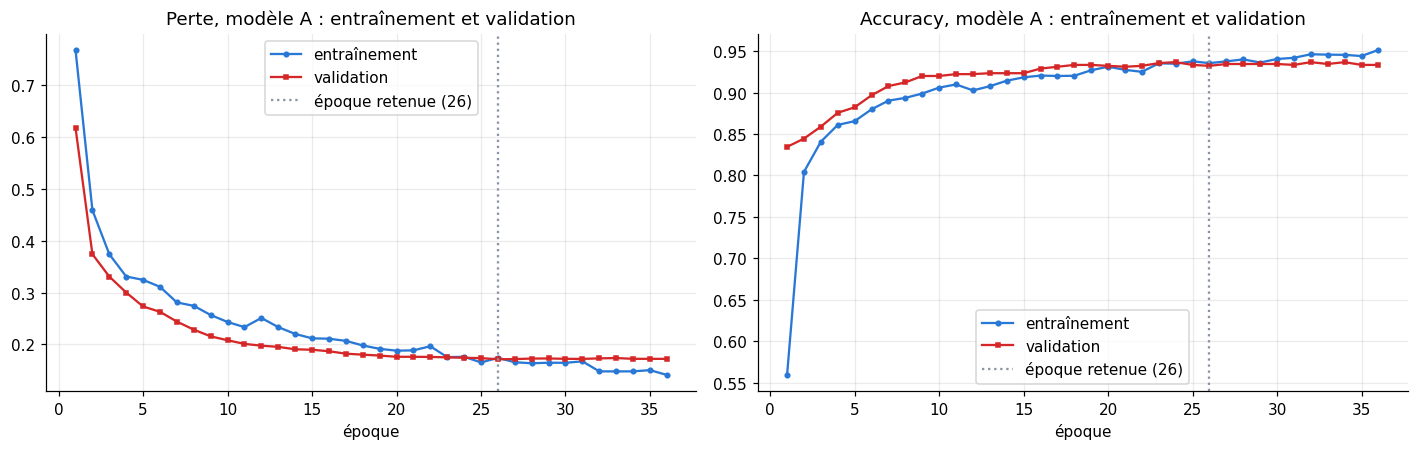

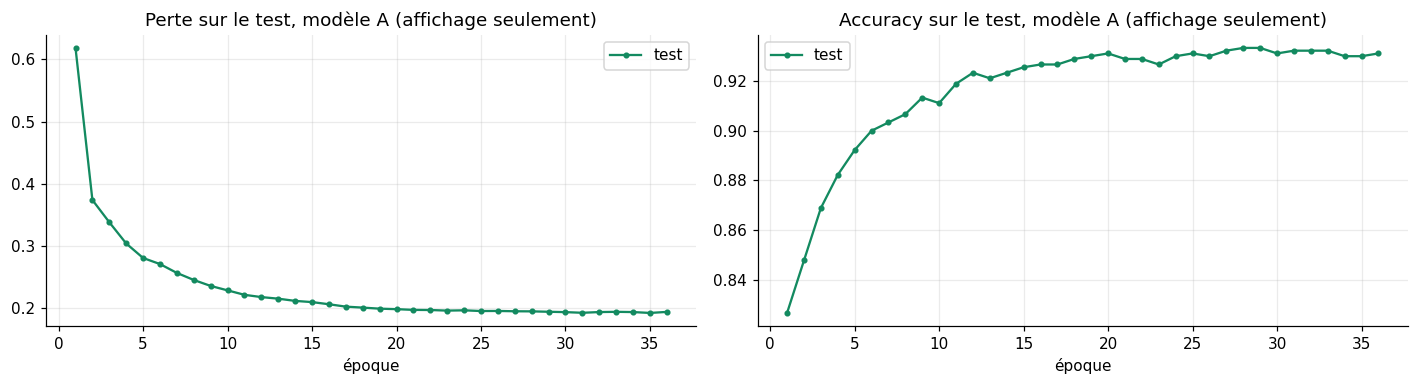

Modèle A, époque retenue 26 sur 36 :
  accuracy entraînement 93.55 %, validation 93.22 % (test, pour information : 93.00 %)
  perte de validation en fin d'entraînement : 1.00 fois sa valeur à l'époque retenue


In [25]:
def entrainerA():
    modele, historique = entrainerCNN(HPA, GRAINE, EPOQUESA, PATIENCEA, DEBUTARRETA, nom="ModeleA",
                                      suivis=[SuiviTest(jeuTest128)], verbose=2)
    modele.summary()
    return modele, historique


modeleA, historiqueA = entrainerOuRecharger("A", {"HPA": HPA, "epoques": EPOQUESA, "patience": PATIENCEA,
                                                  "debut": DEBUTARRETA}, entrainerA)
epoqueA = meilleureEpoque(historiqueA, debutSurveillance(EPOQUESA, DEBUTARRETA))
tracerCourbes("modèle A", historiqueA, epoqueA)
resumerEntrainement("Modèle A", historiqueA, epoqueA)

## Du modèle A au modèle B : ce qui change

Le modèle A est un réseau compact : il atteint déjà 93,0 % d'accuracy sur le test (93,2 % en validation) et
s'entraîne en 2,3 minutes. Ses courbes montrent un **biais modéré** et une **variance quasi nulle** :
entraînement et validation restent presque confondus (93,6 % contre 93,2 % à l'époque retenue, perte de
validation à 1,00 fois sa valeur minimale en fin d'entraînement). Il n'y a pas de surapprentissage à corriger ; le
modèle est limité par sa capacité. Le modèle B répond à cette limite en agrandissant le réseau, puis en
compensant ce gain de capacité par une régularisation plus forte et un arrêt anticipé strict.

### Ce qui change

| | Modèle A | Modèle B |
|---|---|---|
| Blocs convolutifs | 4 blocs : 16, 32, 64, 128 filtres | 5 blocs : 32, 64, 128, 256, 256 filtres |
| Couche dense | aucune : la sortie sigmoïde suit directement le pooling global (128 valeurs) | une couche dense de 128 neurones, avec GroupNormalization et ReLU (sur 256 valeurs) |
| Dropout | 0,3 (avant la sortie) | 0,25 avant la couche dense et 0,5 après |
| Régularisation L2 | 1e-4 | 1e-3 (10 fois plus forte) |
| Paramètres | environ 98 000 | environ 1 million |
| Arrêt anticipé | patience 10 : le modèle tolère 10 époques sans amélioration de la perte de validation avant de s'arrêter | patience 0 : arrêt dès la première époque sans amélioration de la perte de validation |

Dans les deux cas, la surveillance de la perte de validation commence à l'époque 5 et les meilleurs poids sont
restaurés à la fin de l'entraînement.

### Pourquoi ces changements

1. **Plus de capacité (réduire le biais).** Le cinquième bloc et le doublement des filtres donnent au réseau
   plus de motifs à détecter, et la couche dense combine ces motifs de façon non linéaire avant la décision.
   C'est ce qui devrait aider sur les cas difficiles, comme les peintures très réalistes.
2. **Plus de régularisation (contenir la variance).** Un réseau dix fois plus gros peut mémoriser le jeu
   d'entraînement. Un dropout plus élevé (0,5) et un L2 dix fois plus fort limitent ce risque.
3. **Un arrêt anticipé strict.** Un réseau plus riche surapprend plus vite : avec une patience de 0, le
   modèle B s'arrête dès que la perte de validation cesse de s'améliorer, et on restaure les poids de la meilleure
   époque. Cela empêche le modèle de continuer à s'ajuster au jeu d'entraînement une fois le meilleur point
   passé. Le modèle A, plus petit et peu sujet au surapprentissage, peut se permettre une patience de 10.

**Limite de ce choix.** Une patience de 0 est une règle stricte : si la perte de validation remonte
ponctuellement avant d'avoir atteint son minimum, l'entraînement s'arrête et le modèle peut être légèrement
sous-entraîné. Une patience de quelques époques (5 à 10) serait un compromis plus prudent, au prix de quelques
époques supplémentaires de calcul.

### Ce qui ne change pas

Le protocole d'entraînement est identique pour A et B, à l'exception de la patience de l'arrêt anticipé : même
jeu de données et mêmes découpages, même fonction de perte (entropie croisée binaire), même optimiseur (Adam,
pas de départ 5e-4, écrêtage du gradient à 1,0), lots de 64 images, échauffement puis décroissance en cosinus
du taux d'apprentissage, GroupNormalization, moyenne mobile des poids et restauration des meilleurs poids.
Les écarts de résultats viennent donc de la taille du réseau, de sa régularisation et de la règle d'arrêt.

## 9. Modèle B : le même CNN, régularisé, hyperparamètres réglés à la main

GroupNormalization, GlobalAveragePooling, dropout avant et après la couche dense, L2 sur toutes les couches, pas en montée puis cosinus, moyenne mobile des poids, arrêt anticipé. Configuration exécutée : lr 5e-4, dropout 0,5, L2 1e-3, 128 neurones, lots de 64, au plus 50 époques, **patience 0** surveillée dès l'époque 6.

### Pourquoi ce choix et pas un autre : le modèle B réglé à la main

A montrait surtout du biais, donc on a agrandi le réseau. Pour éviter que ce réseau dix fois plus gros apprenne par cœur, on a renforcé le dropout et le L2 et mis une patience de 0.

<table>
<tr><th></th><th>Modèle A</th><th>Modèle B</th></tr>
<tr><td>Paramètres</td><td>environ 98 000</td><td>environ 1 million</td></tr><tr><td>Dropout</td><td>0,3</td><td>0,25 puis 0,5</td></tr><tr><td>L2</td><td>0,0001</td><td>0,001</td></tr><tr><td>Patience</td><td>10</td><td>0</td></tr><tr><td>Accuracy test (seuil 0,5)</td><td>90,67 %</td><td>92,78 %</td></tr><tr><td>AUC test</td><td>0,966</td><td>0,979</td></tr>
</table>

Epoch 1/50
66/66 - 42s - 637ms/step - accuracy: 0.6586 - auc: 0.7183 - loss: 1.3595 - val_accuracy: 0.8322 - val_auc: 0.8638 - val_loss: 1.1517
Epoch 2/50
66/66 - 3s - 48ms/step - accuracy: 0.8071 - auc: 0.8595 - loss: 1.1373 - val_accuracy: 0.8533 - val_auc: 0.9137 - val_loss: 1.0100
Epoch 3/50
66/66 - 3s - 50ms/step - accuracy: 0.8388 - auc: 0.8817 - loss: 1.0068 - val_accuracy: 0.8689 - val_auc: 0.9255 - val_loss: 0.9205
Epoch 4/50
66/66 - 3s - 51ms/step - accuracy: 0.8419 - auc: 0.8877 - loss: 0.9205 - val_accuracy: 0.8622 - val_auc: 0.9294 - val_loss: 0.8446
Epoch 5/50
66/66 - 4s - 55ms/step - accuracy: 0.8579 - auc: 0.9022 - loss: 0.8106 - val_accuracy: 0.8678 - val_auc: 0.9320 - val_loss: 0.7774
Epoch 6/50
66/66 - 3s - 50ms/step - accuracy: 0.8557 - auc: 0.9033 - loss: 0.7583 - val_accuracy: 0.8700 - val_auc: 0.9369 - val_loss: 0.7169
Epoch 7/50
66/66 - 5s - 75ms/step - accuracy: 0.8624 - auc: 0.9118 - loss: 0.6954 - val_accuracy: 0.8722 - val_auc: 0.9392 - val_loss: 0.6709
Epoc

Model: "ModeleB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn1 (GroupNormalization)        │ (None, 128, 128, 32)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn2 (GroupNormalization)        │ (None, 64, 64, 64)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn3 (GroupNormalization)        │ (None, 32, 32, 128)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn4 (GroupNormalization)        │ (None, 16, 16, 256)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn5 (GroupNormalization)        │ (None, 8, 8, 256)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (Activation)              │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool5 (MaxPooling2D)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moyenneGlobale                  │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,037,161 (11.59 MB)

 Trainable params: 1,012,385 (3.86 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,024,776 (7.72 MB)

Modèle B entraîné en 2.6 minutes, enregistré dans modeleB_1f2dacfa.keras.


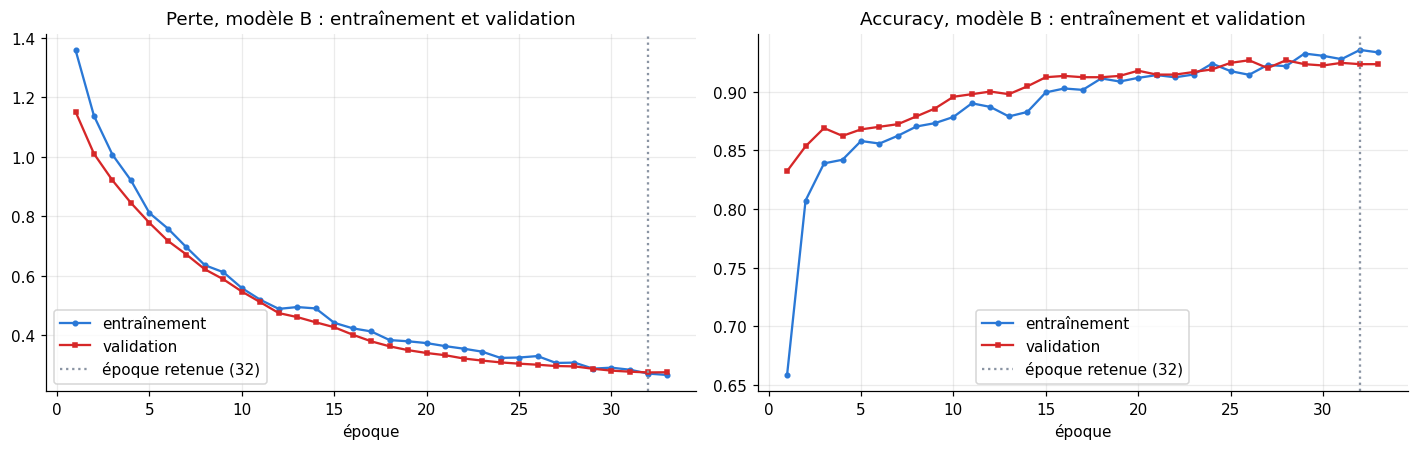

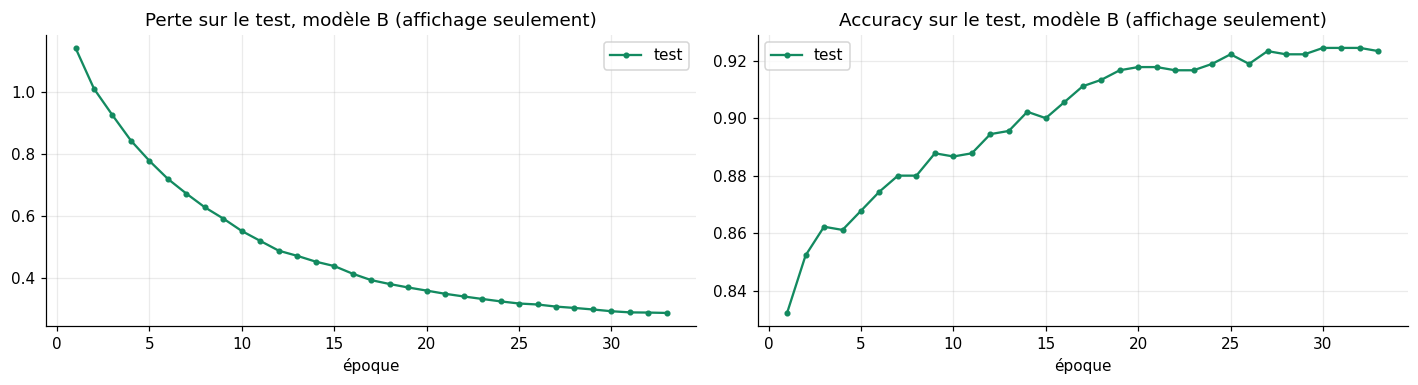

Modèle B, époque retenue 32 sur 33 :
  accuracy entraînement 93.55 %, validation 92.33 % (test, pour information : 92.44 %)
  perte de validation en fin d'entraînement : 1.00 fois sa valeur à l'époque retenue


In [27]:
def entrainerB():
    modele, historique = entrainerCNN(HPB, GRAINE, EPOQUESB, PATIENCEB, DEBUTARRETB, nom="ModeleB",
                                      suivis=[SuiviTest(jeuTest128)], verbose=2)
    modele.summary()
    return modele, historique


modeleB, historiqueB = entrainerOuRecharger("B", {"HPB": HPB, "epoques": EPOQUESB, "patience": PATIENCEB,
                                                  "debut": DEBUTARRETB}, entrainerB)
epoqueB = meilleureEpoque(historiqueB, debutSurveillance(EPOQUESB, DEBUTARRETB))
tracerCourbes("modèle B", historiqueB, epoqueB)
resumerEntrainement("Modèle B", historiqueB, epoqueB)

## 10. Modèle C : le même CNN, hyperparamètres cherchés

Recherche sur la validation, avec des essais courts (12 époques, sans arrêt anticipé), jugés sur l'entropie croisée de validation recalculée en mode prédiction et sans le terme L2 :

* **recherche en grille** : 2 taux d'apprentissage × 4 dropouts × 3 tailles de couche dense = 24 essais ;
* **recherche aléatoire** : 12 tirages dans un espace plus large (taux d'apprentissage, dropout, L2, neurones, filtres, taille des lots).

La meilleure configuration est ensuite entraînée complètement (au plus 60 époques, patience 2 surveillée dès l'époque 6). Chaque essai terminé est enregistré sur Drive : une relance reprend la recherche là où elle s'était arrêtée.

### Pourquoi ce choix et pas un autre : une recherche d'hyperparamètres pour le modèle C

Régler B à la main reposait sur l'intuition. Pour C on a combiné une grille (sûre mais limitée) et des tirages aléatoires (qui explorent plus large pour le même budget). Les essais sont courts, 12 époques, pour que les 36 tiennent en environ une heure.

<table>
<tr><th>Méthode</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Grille (24 essais)</td><td>exhaustive sur les valeurs choisies</td><td>coûte vite cher quand on ajoute des paramètres</td><td>oui</td></tr><tr><td>Aléatoire (12 essais)</td><td>explore plus de valeurs pour le même coût</td><td>peut rater une zone</td><td>oui, en complément</td></tr><tr><td>Optimisation bayésienne (Optuna)</td><td>plus efficace en théorie</td><td>dépendance en plus, peu utile pour 36 essais</td><td>non</td></tr><tr><td>Réglage manuel seul</td><td>rapide</td><td>subjectif, déjà fait pour B</td><td>non</td></tr>
</table>

In [28]:
def essaiRecherche(hp, graine):
    """Un essai court de la recherche d'hyperparamètres, jugé en mode prédiction."""
    modele, historique = entrainerCNN(hp, graine, EPOQUESESSAI, EPOQUESRECHERCHE, DEBUTARRETC, nom="Essai",
                                      complet=False)
    pEntr, pVal = predire(modele, idxEntr).ravel(), predire(modele, idxVal).ravel()
    resultat = {"époque retenue": meilleureEpoque(historique, debutSurveillance(EPOQUESRECHERCHE, DEBUTARRETC)),
                "perte entraînement": metrics.log_loss(yEntr, np.clip(pEntr, 1e-7, 1 - 1e-7), labels=[0, 1]),
                "perte validation": metrics.log_loss(yVal, np.clip(pVal, 1e-7, 1 - 1e-7), labels=[0, 1]),
                "erreur entraînement (%)": 100 * np.mean((pEntr >= 0.5) != yEntr),
                "erreur validation (%)": 100 * np.mean((pVal >= 0.5) != yVal)}
    del modele                      # libère le modèle de cet essai
    keras.backend.clear_session()   # libère les graphes et l'état de Keras
    gc.collect()
    return resultat


def lancerRecherche(nom, listeHp, graineDepart):
    """Lance (ou relit) une série d'essais. Chaque essai terminé est enregistré, ce qui permet de reprendre."""
    cle = cleConfiguration({"essais": listeHp, "graine": graineDepart, "epoques": EPOQUESESSAI})
    fichier = DOSSIERTRAVAIL / f"recherche{nom.capitalize().replace('é', 'e')}_{cle}.csv"
    deja = pd.read_csv(fichier) if (REUTILISER and fichier.exists()) else pd.DataFrame()
    lignes, debut = deja.to_dict("records"), time.time()
    for numero, hp in enumerate(listeHp):
        if numero < len(lignes):
            continue
        departEssai = time.time()
        scores = essaiRecherche(hp, graineDepart + numero)
        lignes.append({"méthode": nom, "essai": numero + 1, **hp, **scores, "graine": graineDepart + numero,
                       "minutes": (time.time() - departEssai) / 60})
        pd.DataFrame(lignes).to_csv(fichier, index=False)
        print(f"  {nom}, essai {numero + 1}/{len(listeHp)} : perte de validation {scores['perte validation']:.4f}, "
              f"{lignes[-1]['minutes']:.1f} minutes")
    print(f"{nom} : {len(listeHp)} essais, dont {len(listeHp) - len(deja)} calculés en "
          f"{(time.time() - debut) / 60:.1f} minutes.")
    return pd.DataFrame(lignes)


def afficherEssais(resultats, n=8):
    """Les n meilleurs essais, taux d'apprentissage et L2 en notation scientifique."""
    vue = resultats.sort_values("perte validation").head(n).copy()
    for colonne in ["lr", "l2"]:
        vue[colonne] = vue[colonne].map(lambda v: f"{v:.1e}")
    colonnes = ["méthode", "essai", "lr", "dropout", "l2", "neurones", "filtres", "lot", "époque retenue",
                "perte entraînement", "perte validation", "erreur entraînement (%)", "erreur validation (%)"]
    display(vue[colonnes].round(4).set_index("méthode"))

Grille : 2 lr x 4 dropout x 3 neurones = 24 essais
  grille, essai 1/24 : perte de validation 0.2471, 2.0 minutes
  grille, essai 2/24 : perte de validation 0.1996, 2.7 minutes
  grille, essai 3/24 : perte de validation 0.2118, 1.7 minutes
  grille, essai 4/24 : perte de validation 0.2362, 1.8 minutes
  grille, essai 5/24 : perte de validation 0.2768, 1.7 minutes
  grille, essai 6/24 : perte de validation 0.2785, 1.7 minutes
  grille, essai 7/24 : perte de validation 0.2741, 1.7 minutes
  grille, essai 8/24 : perte de validation 0.3064, 1.7 minutes
  grille, essai 9/24 : perte de validation 0.1877, 1.9 minutes
  grille, essai 10/24 : perte de validation 0.2154, 1.8 minutes
  grille, essai 11/24 : perte de validation 0.2325, 1.7 minutes
  grille, essai 12/24 : perte de validation 0.2340, 1.8 minutes
  grille, essai 13/24 : perte de validation 0.2235, 1.7 minutes
  grille, essai 14/24 : perte de validation 0.2762, 1.8 minutes
  grille, essai 15/24 : perte de validation 0.2619, 1.8 minute

,essai,lr,dropout,l2,neurones,filtres,lot,époque retenue,perte entraînement,perte validation,erreur entraînement (%),erreur validation (%)
méthode,,,,,,,,,,,,
grille,17,5.0e-04,0.3,5.0e-04,512,32,32,12,0.1696,0.1737,6.9524,7.7778
grille,9,5.0e-04,0.3,5.0e-04,256,32,32,12,0.1829,0.1877,7.1190,7.8889
grille,2,5.0e-04,0.5,5.0e-04,128,32,32,12,0.2040,0.1996,7.9286,8.7778
grille,18,5.0e-04,0.5,5.0e-04,512,32,32,12,0.2214,0.2059,8.7619,8.4444
grille,19,5.0e-04,0.6,5.0e-04,512,32,32,12,0.2136,0.2104,8.4286,8.6667
grille,3,5.0e-04,0.6,5.0e-04,128,32,32,12,0.2113,0.2118,8.5000,8.5556
grille,10,5.0e-04,0.5,5.0e-04,256,32,32,12,0.2017,0.2154,7.9762,9.3333
grille,20,5.0e-04,0.7,5.0e-04,512,32,32,12,0.2282,0.2213,9.0714,9.2222


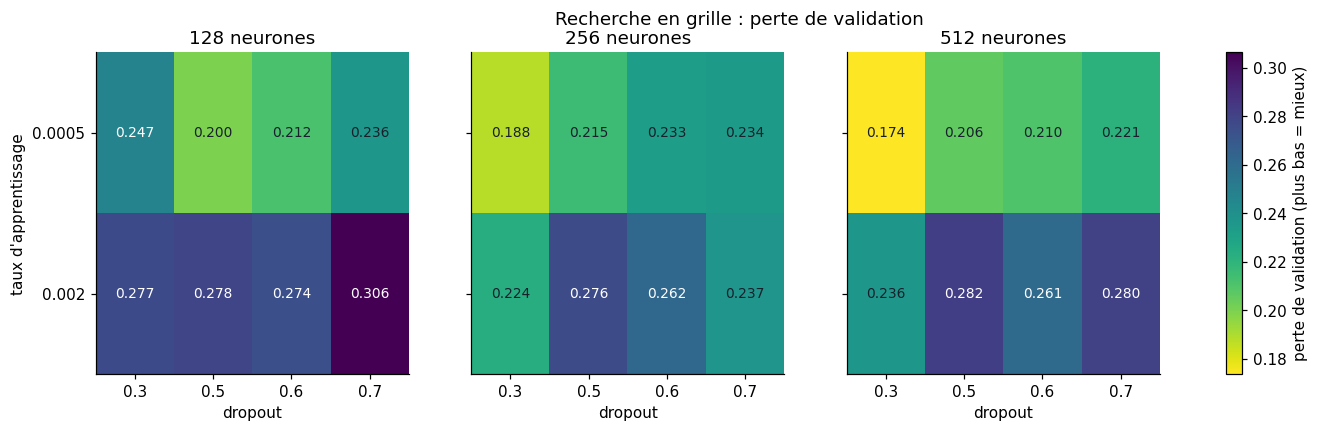

In [29]:
valeursNeurones = GRILLE["neurones"]
combinaisons = [{"lr": lr, "dropout": d, "neurones": n, **GRILLEFIXE}
                for n in valeursNeurones for lr in GRILLE["lr"] for d in GRILLE["dropout"]]
print(f"Grille : {len(GRILLE['lr'])} lr x {len(GRILLE['dropout'])} dropout x {len(valeursNeurones)} neurones "
      f"= {len(combinaisons)} essais")
rechercheGrille = lancerRecherche("grille", combinaisons, GRAINE)
afficherEssais(rechercheGrille)

fig, axes = plt.subplots(1, len(valeursNeurones), figsize=(5.2 * len(valeursNeurones), 3.8), sharey=True, squeeze=False)
axes = axes[0]
vmin, vmax = rechercheGrille["perte validation"].min(), rechercheGrille["perte validation"].max()
for ax, n in zip(axes, valeursNeurones):
    tableau = rechercheGrille[rechercheGrille["neurones"] == n].pivot(index="lr", columns="dropout", values="perte validation")
    image = ax.imshow(tableau.values, cmap="viridis_r", aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(tableau.columns)), [f"{c:g}" for c in tableau.columns])
    ax.set_yticks(range(len(tableau.index)), [f"{i:g}" for i in tableau.index])
    ax.set_xlabel("dropout")
    ax.grid(False)
    for i in range(tableau.shape[0]):
        for j in range(tableau.shape[1]):
            valeur = tableau.values[i, j]
            claire = (valeur - vmin) / max(vmax - vmin, 1e-12) < 0.5
            ax.text(j, i, f"{valeur:.3f}", ha="center", va="center", fontsize=9, color=ENCRE if claire else "white")
    ax.set_title(f"{n} neurones")
axes[0].set_ylabel("taux d'apprentissage")
fig.colorbar(image, ax=axes, label="perte de validation (plus bas = mieux)")
fig.suptitle("Recherche en grille : perte de validation")
plt.show()

  aléatoire, essai 1/12 : perte de validation 0.3251, 2.3 minutes
  aléatoire, essai 2/12 : perte de validation 0.2913, 2.0 minutes
  aléatoire, essai 3/12 : perte de validation 0.2361, 1.9 minutes
  aléatoire, essai 4/12 : perte de validation 0.2215, 2.0 minutes
  aléatoire, essai 5/12 : perte de validation 0.2533, 1.8 minutes
  aléatoire, essai 6/12 : perte de validation 0.2854, 2.0 minutes
  aléatoire, essai 7/12 : perte de validation 0.1906, 2.0 minutes
  aléatoire, essai 8/12 : perte de validation 0.2216, 2.1 minutes
  aléatoire, essai 9/12 : perte de validation 0.1896, 2.1 minutes
  aléatoire, essai 10/12 : perte de validation 0.2734, 1.8 minutes
  aléatoire, essai 11/12 : perte de validation 0.2459, 2.0 minutes
  aléatoire, essai 12/12 : perte de validation 0.2059, 1.8 minutes
aléatoire : 12 essais, dont 12 calculés en 23.6 minutes.


,essai,lr,dropout,l2,neurones,filtres,lot,époque retenue,perte entraînement,perte validation,erreur entraînement (%),erreur validation (%)
méthode,,,,,,,,,,,,
aléatoire,9,2.8e-04,0.3903,3.6e-05,128,40,64,12,0.1904,0.1896,7.6905,8.1111
aléatoire,7,2.3e-04,0.2617,4.9e-04,256,40,32,12,0.1931,0.1906,7.7143,7.7778
aléatoire,12,3.4e-04,0.2029,8.9e-04,64,40,64,12,0.2056,0.2059,7.9286,7.7778
aléatoire,4,6.6e-04,0.2909,2.4e-04,256,40,32,12,0.2164,0.2215,8.6429,9.4444
aléatoire,8,4.8e-04,0.3482,1.5e-04,256,40,32,12,0.2229,0.2216,9.0714,9.4444
aléatoire,3,6.8e-04,0.3483,2.0e-03,256,32,32,12,0.2339,0.2361,9.7381,10.1111
aléatoire,11,1.8e-03,0.3550,5.2e-05,64,40,64,12,0.2384,0.2459,9.6190,10.3333
aléatoire,5,1.9e-03,0.4527,7.5e-04,256,32,32,12,0.2478,0.2533,9.9524,10.3333


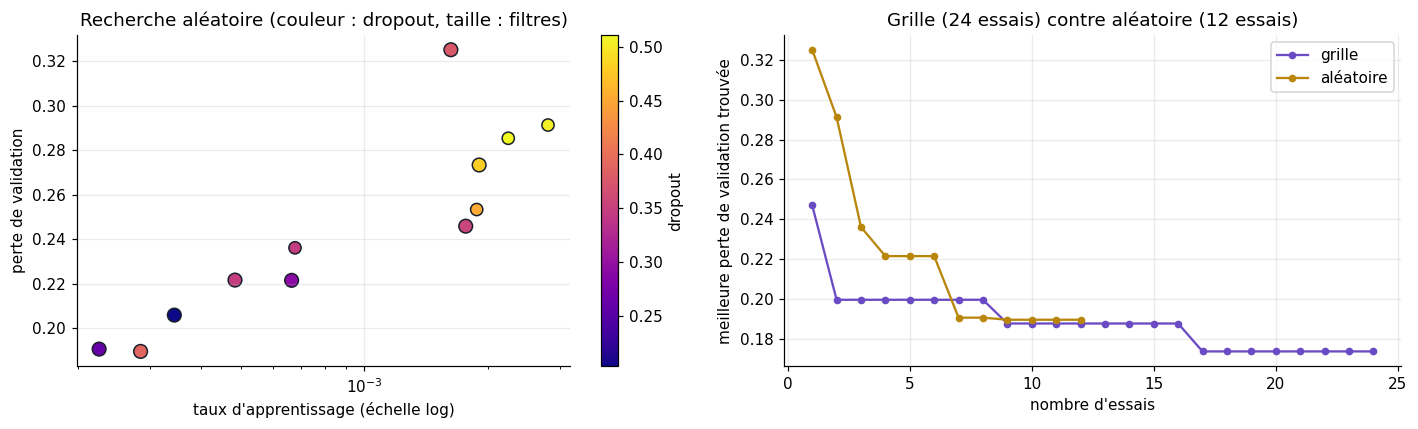

In [30]:
hasard = np.random.default_rng(GRAINE)
tirages = [{"lr": float(10 ** hasard.uniform(np.log10(2e-4), np.log10(3e-3))),
            "dropout": float(hasard.uniform(0.2, 0.6)),
            "l2": float(10 ** hasard.uniform(-5, np.log10(3e-3))),
            "neurones": int(hasard.choice([64, 128, 256])),
            "filtres": int(hasard.choice([24, 32, 40])),
            "lot": int(hasard.choice([32, 64]))} for _ in range(ESSAISALEATOIRES)]
keras.backend.clear_session()
gc.collect()
rechercheAleatoire = lancerRecherche("aléatoire", tirages, GRAINE + 1000)
afficherEssais(rechercheAleatoire)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nuage = axes[0].scatter(rechercheAleatoire["lr"], rechercheAleatoire["perte validation"], c=rechercheAleatoire["dropout"],
                        s=2 * rechercheAleatoire["filtres"], cmap="plasma", edgecolor=ENCRE)
axes[0].set_xscale("log")
axes[0].set_xlabel("taux d'apprentissage (échelle log)")
axes[0].set_ylabel("perte de validation")
axes[0].set_title("Recherche aléatoire (couleur : dropout, taille : filtres)")
fig.colorbar(nuage, ax=axes[0], label="dropout")
for resultats, couleur, nom in [(rechercheGrille, "#6a4bc4", "grille"), (rechercheAleatoire, "#b8860b", "aléatoire")]:
    axes[1].plot(resultats["essai"], resultats["perte validation"].cummin(), color=couleur, marker="o", markersize=4,
                 label=nom)
axes[1].set_xlabel("nombre d'essais")
axes[1].set_ylabel("meilleure perte de validation trouvée")
axes[1].set_title("Grille (24 essais) contre aléatoire (12 essais)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [31]:
recherche = pd.concat([rechercheGrille, rechercheAleatoire], ignore_index=True)
recherche.to_csv(DOSSIERTRAVAIL / "rechercheHyperparametres.csv", index=False)
print("Meilleur essai de chaque méthode :")
afficherEssais(recherche.loc[recherche.groupby("méthode")["perte validation"].idxmin()], n=2)
meilleur = recherche.loc[recherche["perte validation"].idxmin()]
hpC = {"lr": float(meilleur["lr"]), "dropout": float(meilleur["dropout"]), "l2": float(meilleur["l2"]),
       "neurones": int(meilleur["neurones"]), "filtres": int(meilleur["filtres"]), "lot": int(meilleur["lot"])}
print(f"Meilleur essai : recherche {meilleur['méthode']}, essai {meilleur['essai']} (graine {int(meilleur['graine'])})")
print("Hyperparamètres retenus pour le modèle C :", hpC)
print("Pour comparaison, modèle B :", HPB)

Meilleur essai de chaque méthode :


,essai,lr,dropout,l2,neurones,filtres,lot,époque retenue,perte entraînement,perte validation,erreur entraînement (%),erreur validation (%)
méthode,,,,,,,,,,,,
grille,17,5.0e-04,0.3000,5.0e-04,512,32,32,12,0.1696,0.1737,6.9524,7.7778
aléatoire,9,2.8e-04,0.3903,3.6e-05,128,40,64,12,0.1904,0.1896,7.6905,8.1111


Meilleur essai : recherche grille, essai 17 (graine 58)
Hyperparamètres retenus pour le modèle C : {'lr': 0.0005, 'dropout': 0.3, 'l2': 0.0005, 'neurones': 512, 'filtres': 32, 'lot': 32}
Pour comparaison, modèle B : {'lr': 0.0005, 'dropout': 0.5, 'l2': 0.001, 'neurones': 128, 'filtres': 32, 'lot': 64}


Epoch 1/60
132/132 - 30s - 224ms/step - accuracy: 0.7540 - auc: 0.8200 - loss: 0.9625 - val_accuracy: 0.8411 - val_auc: 0.8804 - val_loss: 0.8381
Epoch 2/60
132/132 - 6s - 44ms/step - accuracy: 0.8240 - auc: 0.8814 - loss: 0.8336 - val_accuracy: 0.8722 - val_auc: 0.9361 - val_loss: 0.7211
Epoch 3/60
132/132 - 6s - 47ms/step - accuracy: 0.8488 - auc: 0.9009 - loss: 0.7392 - val_accuracy: 0.8800 - val_auc: 0.9433 - val_loss: 0.6501
Epoch 4/60
132/132 - 6s - 46ms/step - accuracy: 0.8676 - auc: 0.9241 - loss: 0.6440 - val_accuracy: 0.8878 - val_auc: 0.9480 - val_loss: 0.5807
Epoch 5/60
132/132 - 6s - 46ms/step - accuracy: 0.8733 - auc: 0.9281 - loss: 0.5911 - val_accuracy: 0.8967 - val_auc: 0.9560 - val_loss: 0.5229
Epoch 6/60
132/132 - 6s - 48ms/step - accuracy: 0.8783 - auc: 0.9420 - loss: 0.5278 - val_accuracy: 0.9078 - val_auc: 0.9674 - val_loss: 0.4705
Epoch 7/60
132/132 - 6s - 45ms/step - accuracy: 0.8831 - auc: 0.9487 - loss: 0.4847 - val_accuracy: 0.9122 - val_auc: 0.9724 - val_los

Model: "ModeleC"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn1 (GroupNormalization)        │ (None, 128, 128, 32)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn2 (GroupNormalization)        │ (None, 64, 64, 64)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn3 (GroupNormalization)        │ (None, 32, 32, 128)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn4 (GroupNormalization)        │ (None, 16, 16, 256)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn5 (GroupNormalization)        │ (None, 8, 8, 256)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (Activation)              │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool5 (MaxPooling2D)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moyenneGlobale                  │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,335,525 (12.72 MB)

 Trainable params: 1,111,841 (4.24 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,223,684 (8.48 MB)

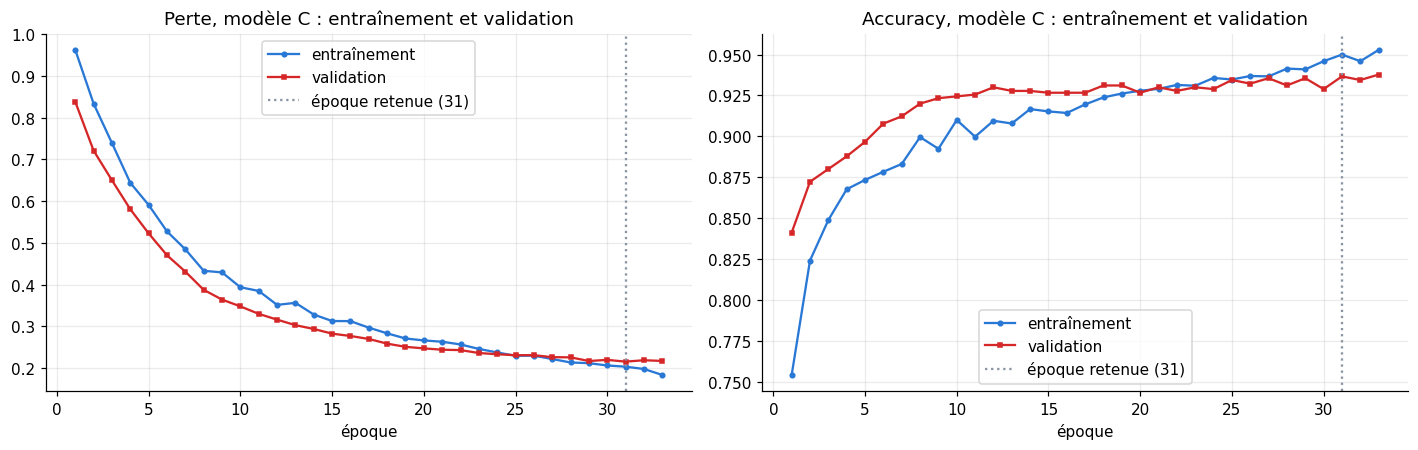

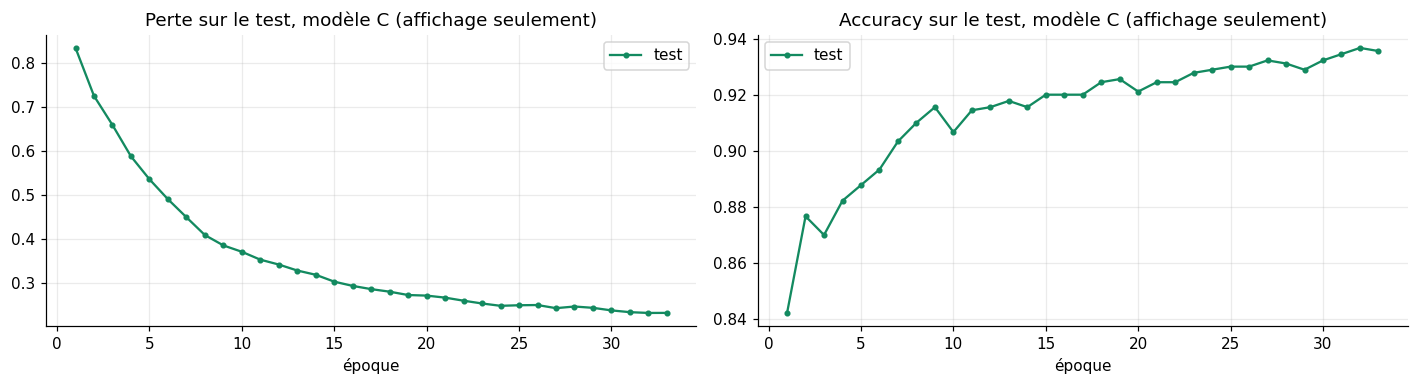

Modèle C, époque retenue 31 sur 33 :
  accuracy entraînement 95.00 %, validation 93.67 % (test, pour information : 93.44 %)
  perte de validation en fin d'entraînement : 1.01 fois sa valeur à l'époque retenue


In [32]:
grainesC = int(meilleur["graine"])
modeleC, historiqueC = entrainerOuRecharger(
    "C", {"hpC": hpC, "graine": grainesC, "epoques": EPOQUESC, "patience": PATIENCEC, "debut": DEBUTARRETC},
    lambda: entrainerCNN(hpC, grainesC, EPOQUESC, PATIENCEC, DEBUTARRETC, nom="ModeleC",
                         suivis=[SuiviTest(jeuTest128)], verbose=2))
epoqueC = meilleureEpoque(historiqueC, debutSurveillance(EPOQUESC, DEBUTARRETC))
modeleC.summary()
tracerCourbes("modèle C", historiqueC, epoqueC)
resumerEntrainement("Modèle C", historiqueC, epoqueC)

## 11. Biais et variance : comparaison des trois modèles (section 12 du carnet principal)

Les erreurs sont recalculées en mode prédiction (dropout éteint) sur l'entraînement et la validation, au seuil 0,5. Repères : biais élevé au-dessus de 5 % d'erreur d'entraînement, variance élevée au-dessus de 2 points d'écart. Le test n'apparaît pas dans ce tableau.

### Pourquoi ce choix et pas un autre : le diagnostic biais / variance

Les erreurs sont recalculées avec le dropout éteint. Sans ça, l'erreur d'entraînement serait gonflée et on croirait à tort que le modèle a du biais.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Erreurs en mode prédiction</td><td>compare entraînement et validation sur la même base</td><td>un passage de plus sur les données</td><td>oui</td></tr><tr><td>Erreurs lues dans l'historique Keras</td><td>gratuit</td><td>entraînement mesuré avec dropout actif, donc faussé</td><td>non</td></tr>
</table>

Tableau comparatif en entraînement et en validation (seuil 0,5, mode prédiction) :


,paramètres,entraînement (min),époque retenue,erreur entraînement (%),erreur validation (%),écart validation entraînement,perte entraînement,perte validation,AUC validation
Modèle A,97 809,2.3,26,4.90,6.78,1.87,0.1256,0.1558,0.9833
Modèle B,1 012 385,2.6,32,5.43,7.67,2.24,0.1411,0.1730,0.9791
Modèle C,1 111 841,3.9,31,3.93,6.33,2.40,0.0974,0.1510,0.9853


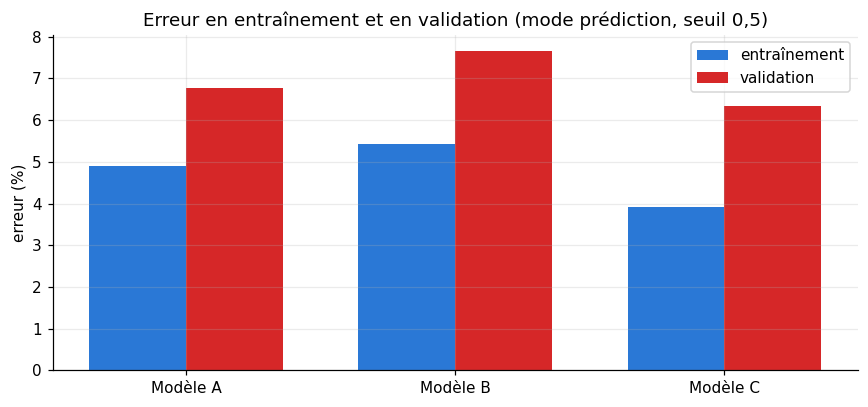

  Modèle A : erreur d'entraînement 4.90 %, écart validation entraînement +1.87 points → bon compromis
  Modèle B : erreur d'entraînement 5.43 %, écart validation entraînement +2.24 points → biais élevé, variance élevée
  Modèle C : erreur d'entraînement 3.93 %, écart validation entraînement +2.40 points → variance élevée


In [33]:
predictions = {
    "Modèle A": {jeu: predire(modeleA, idx).ravel() for jeu, idx in
                 [("entraînement", idxEntr), ("validation", idxVal), ("test", idxTest)]},
    "Modèle B": {jeu: predire(modeleB, idx).ravel() for jeu, idx in
                 [("entraînement", idxEntr), ("validation", idxVal), ("test", idxTest)]},
    "Modèle C": {jeu: predire(modeleC, idx).ravel() for jeu, idx in
                 [("entraînement", idxEntr), ("validation", idxVal), ("test", idxTest)]},
}
vrais = {"entraînement": yEntr, "validation": yVal, "test": yTest}
perteLog = lambda v, p: metrics.log_loss(v, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1])
erreurs = pd.DataFrame({m: {jeu: 100 * np.mean((p >= 0.5) != vrais[jeu]) for jeu, p in ps.items()}
                        for m, ps in predictions.items()}).T
pertes = pd.DataFrame({m: {jeu: perteLog(vrais[jeu], p) for jeu, p in ps.items()} for m, ps in predictions.items()}).T

historiques = {"Modèle A": (historiqueA, epoqueA), "Modèle B": (historiqueB, epoqueB), "Modèle C": (historiqueC, epoqueC)}
nbParametres = {"Modèle A": modeleA.count_params(), "Modèle B": modeleB.count_params(), "Modèle C": modeleC.count_params()}
durees = {m: h["duree"].iloc[0] for m, (h, _) in historiques.items()}
comparaison = pd.DataFrame({m: {
    "paramètres": nbParametres[m],
    "entraînement (min)": durees[m],
    "époque retenue": historiques[m][1],
    "erreur entraînement (%)": erreurs.loc[m, "entraînement"],
    "erreur validation (%)": erreurs.loc[m, "validation"],
    "écart validation entraînement": erreurs.loc[m, "validation"] - erreurs.loc[m, "entraînement"],
    "perte entraînement": pertes.loc[m, "entraînement"],
    "perte validation": pertes.loc[m, "validation"],
    "AUC validation": metrics.roc_auc_score(yVal, predictions[m]["validation"])} for m in predictions}).T
comparaison["paramètres"] = comparaison["paramètres"].astype(int).map(lambda v: f"{v:,}".replace(",", " "))
comparaison["époque retenue"] = comparaison["époque retenue"].astype(int)
print("Tableau comparatif en entraînement et en validation (seuil 0,5, mode prédiction) :")
display(comparaison.round({"entraînement (min)": 1, "erreur entraînement (%)": 2, "erreur validation (%)": 2,
                           "écart validation entraînement": 2, "perte entraînement": 4, "perte validation": 4,
                           "AUC validation": 4}))

positions = np.arange(len(erreurs))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(positions - 0.18, erreurs["entraînement"], 0.36, color=BLEU, label="entraînement")
ax.bar(positions + 0.18, erreurs["validation"], 0.36, color=ORANGE, label="validation")
ax.set_xticks(positions, erreurs.index)
ax.set_ylabel("erreur (%)")
ax.set_title("Erreur en entraînement et en validation (mode prédiction, seuil 0,5)")
ax.legend()
plt.tight_layout()
plt.show()

for modele, ligne in erreurs.iterrows():
    biais, ecart = ligne["entraînement"], ligne["validation"] - ligne["entraînement"]
    verdict = (["biais élevé"] if biais > 5 else []) + (["variance élevée"] if ecart > 2 else [])
    print(f"  {modele} : erreur d'entraînement {biais:.2f} %, écart validation entraînement {ecart:+.2f} points → "
          + (", ".join(verdict) if verdict else "bon compromis"))

**Courbe de validation et courbe d'apprentissage.** Un gradient boosting d'arbres posé sur les 19 mesures manuelles de la section 6 : on fait varier sa capacité (nombre de feuilles), puis le nombre d'images d'entraînement.

,feuilles,entraînement,validation
0,2,9.119,10.222
1,3,6.881,8.778
2,4,5.571,7.889
3,8,2.214,8.000
4,16,0.000,7.556
5,32,0.000,7.778
6,64,0.000,7.111
7,128,0.000,7.556
8,256,0.000,7.778


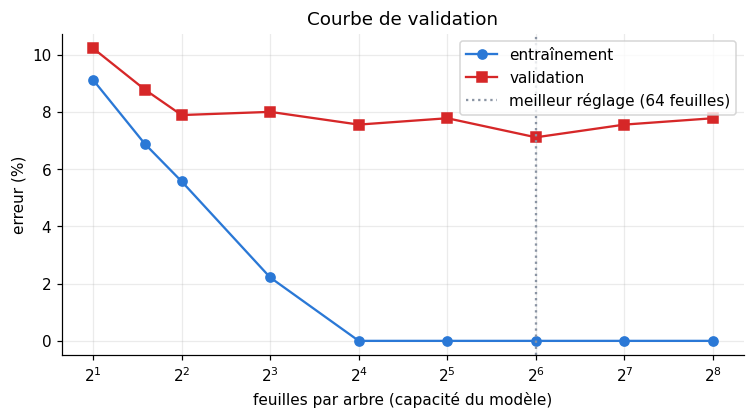

,images,entraînement,validation,ecart
0,126,0.0,15.333,15.333
1,420,0.0,9.000,9.000
2,1050,0.0,9.667,9.667
3,2100,0.0,8.444,8.444
4,3150,0.0,7.444,7.444
5,4200,0.0,7.111,7.111


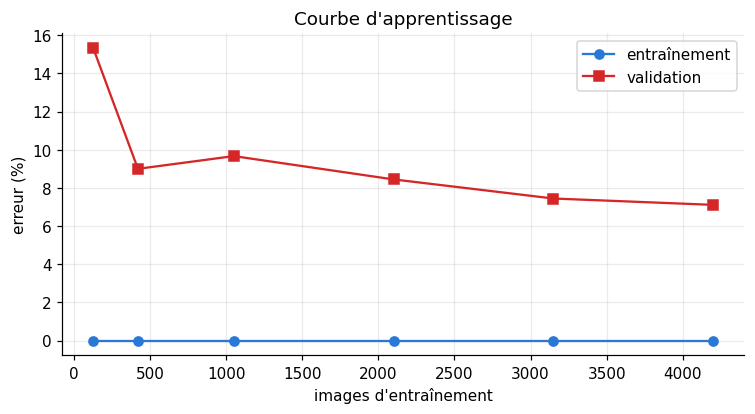

Modèle A : 4.90 % d'erreur en entraînement, 6.78 % en validation, soit 1.9 points d'écart.
Modèle B : écart de 2.2 points, erreur de validation 7.67 %.
Modèle C : 3.93 % en entraînement, 6.33 % en validation (2.4 points d'écart).
Recherche contre réglage à la main : perte de validation 0.1510 pour C contre 0.1730 pour B.


In [34]:
def boosting(feuilles):
    return HistGradientBoostingClassifier(max_leaf_nodes=feuilles, max_iter=200, learning_rate=0.1, min_samples_leaf=5,
                                          early_stopping=False, random_state=GRAINE)


lignes = []
for feuilles in [2, 3, 4, 8, 16, 32, 64, 128, 256]:
    modele = boosting(feuilles).fit(Mentr, yEntr)
    lignes.append({"feuilles": feuilles, "entraînement": 100 * np.mean(modele.predict(Mentr) != yEntr),
                   "validation": 100 * np.mean(modele.predict(Mval) != yVal)})
courbeValidation = pd.DataFrame(lignes)
display(courbeValidation.round(3))
meilleuresFeuilles = int(courbeValidation.loc[courbeValidation["validation"].idxmin(), "feuilles"])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(courbeValidation["feuilles"], courbeValidation["entraînement"], color=BLEU, marker="o", label="entraînement")
ax.plot(courbeValidation["feuilles"], courbeValidation["validation"], color=ORANGE, marker="s", label="validation")
ax.axvline(meilleuresFeuilles, color=GRIS, linestyle="dotted", label=f"meilleur réglage ({meilleuresFeuilles} feuilles)")
ax.set_xscale("log", base=2)
ax.set_xlabel("feuilles par arbre (capacité du modèle)")
ax.set_ylabel("erreur (%)")
ax.set_title("Courbe de validation")
ax.legend()
plt.show()

lignes = []
melange = np.random.default_rng(GRAINE).permutation(len(Mentr))
for part in [0.03, 0.1, 0.25, 0.5, 0.75, 1.0]:
    garde = melange[:int(part * len(Mentr))]
    modele = boosting(meilleuresFeuilles).fit(Mentr[garde], yEntr[garde])
    lignes.append({"images": len(garde), "entraînement": 100 * np.mean(modele.predict(Mentr[garde]) != yEntr[garde]),
                   "validation": 100 * np.mean(modele.predict(Mval) != yVal)})
courbeApprentissage = pd.DataFrame(lignes).assign(ecart=lambda t: t["validation"] - t["entraînement"])
display(courbeApprentissage.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(courbeApprentissage["images"], courbeApprentissage["entraînement"], color=BLEU, marker="o", label="entraînement")
ax.plot(courbeApprentissage["images"], courbeApprentissage["validation"], color=ORANGE, marker="s", label="validation")
ax.set_xlabel("images d'entraînement")
ax.set_ylabel("erreur (%)")
ax.set_title("Courbe d'apprentissage")
ax.legend()
plt.show()

eA, eB, eC = (erreurs.loc[m] for m in ["Modèle A", "Modèle B", "Modèle C"])
print(f"Modèle A : {eA['entraînement']:.2f} % d'erreur en entraînement, {eA['validation']:.2f} % en validation, "
      f"soit {eA['validation'] - eA['entraînement']:.1f} points d'écart.")
print(f"Modèle B : écart de {eB['validation'] - eB['entraînement']:.1f} points, erreur de validation {eB['validation']:.2f} %.")
print(f"Modèle C : {eC['entraînement']:.2f} % en entraînement, {eC['validation']:.2f} % en validation "
      f"({eC['validation'] - eC['entraînement']:.1f} points d'écart).")
print(f"Recherche contre réglage à la main : perte de validation {pertes.loc['Modèle C', 'validation']:.4f} "
      f"pour C contre {pertes.loc['Modèle B', 'validation']:.4f} pour B.")

## 12. Choix du modèle et du seuil (section 13)

Le modèle retenu est celui dont l'entropie croisée de **validation** (mode prédiction, sans L2) est la plus faible. Le seuil de décision est celui qui maximise le F1 de la classe photo en validation. Le test n'intervient dans aucun de ces deux choix.

### Pourquoi ce choix et pas un autre : choisir sur la perte de validation et ajuster le seuil

La perte (entropie croisée) tient compte de la confiance du modèle, pas seulement du nombre d'erreurs, donc elle départage mieux des modèles proches. Le seuil est mis là où le F1 photo est le meilleur en validation, ce qui donne 0,345 au lieu de 0,5.

<table>
<tr><th>Modèle</th><th>Perte de validation</th><th>Retenu ?</th></tr>
<tr><td>Modèle A</td><td>0,2011</td><td>non</td></tr><tr><td>Modèle B</td><td>0,1727</td><td>non</td></tr><tr><td>Modèle C</td><td>0,1571</td><td>oui</td></tr>
</table>

Perte de validation : {'Modèle A': 0.2011, 'Modèle B': 0.1727, 'Modèle C': 0.1571}
Modèle retenu : Modèle C
Seuil retenu : 0.345 (précision 92.77%, rappel 96.89%, F1 94.78% en validation)


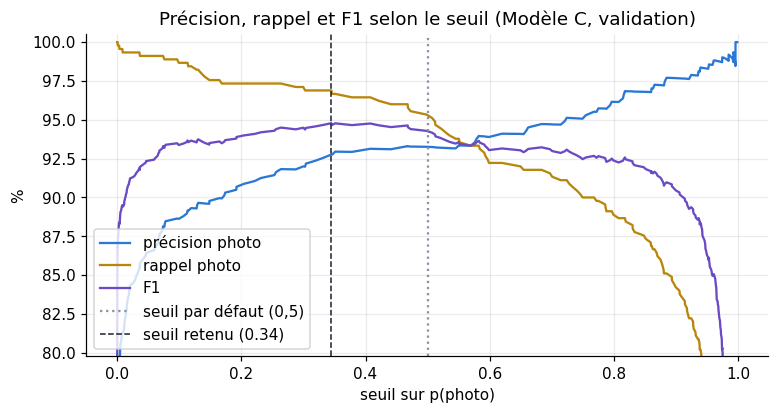

In [ ]:
pertesValidation = pertes["validation"].round(4).to_dict()
choisi = min(pertesValidation, key=pertesValidation.get)
modeles = {"Modèle A": (modeleA, TAILLECNN), "Modèle B": (modeleB, TAILLECNN), "Modèle C": (modeleC, TAILLECNN)}
modeleFinal, tailleFinale = modeles[choisi]
print("Perte de validation :", pertesValidation)
print("Modèle retenu :", choisi)

pVal, pTest = predictions[choisi]["validation"], predictions[choisi]["test"]
precisions, rappels, seuils = metrics.precision_recall_curve(yVal, pVal)
precisions, rappels = precisions[:len(seuils)], rappels[:len(seuils)]
f1 = 2 * precisions * rappels / np.clip(precisions + rappels, 1e-9, None)
rang = int(np.argmax(f1))
seuil = float(seuils[rang])
print(f"Seuil retenu : {seuil:.3f} (précision {precisions[rang]:.2%}, rappel {rappels[rang]:.2%}, F1 {f1[rang]:.2%} en validation)")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(seuils, 100 * precisions, color=BLEU, label="précision photo")
ax.plot(seuils, 100 * rappels, color="#b8860b", label="rappel photo")
ax.plot(seuils, 100 * f1, color="#6a4bc4", label="F1")
ax.axvline(0.5, color=GRIS, linestyle="dotted", label="seuil par défaut (0,5)")
ax.axvline(seuil, color=ENCRE, linestyle="dashed", linewidth=1, label=f"seuil retenu ({seuil:.2f})")
ax.set_xlabel("seuil sur p(photo)")
ax.set_ylabel("%")
ax.set_ylim(max(0, min(80, 100 * f1.max() - 15)), 100.5)
ax.set_title(f"Précision, rappel et F1 selon le seuil ({choisi}, validation)")
ax.legend(loc="lower left")
plt.show()

## 13. Évaluation finale sur le test (section 14)

Première et unique utilisation du test pour juger les modèles : 900 images jamais utilisées pour une décision. Classe positive : photo. Vrais positifs = photos acceptées, vrais négatifs = autres images rejetées, faux positifs = autres images acceptées comme photos, faux négatifs = photos rejetées.

### Pourquoi ce choix et pas un autre : la mesure unique sur le test

Le test n'a servi à aucune décision. On regarde plusieurs indicateurs parce que l'accuracy seule cache le type d'erreur : pour un filtre photo, rater une photo (rappel) et laisser passer une peinture (précision) n'ont pas le même coût.

<table>
<tr><th>Modèle</th><th>Accuracy</th><th>Précision photo</th><th>Rappel photo</th><th>F1 photo</th><th>AUC</th></tr>
<tr><td>A, seuil 0,5</td><td>90,67 %</td><td>87,81 %</td><td>94,44 %</td><td>91,01 %</td><td>0,966</td></tr><tr><td>B, seuil 0,5</td><td>92,78 %</td><td>90,19 %</td><td>96,00 %</td><td>93,00 %</td><td>0,979</td></tr><tr><td>C, seuil 0,5</td><td>92,33 %</td><td>90,28 %</td><td>94,89 %</td><td>92,52 %</td><td>0,981</td></tr><tr><td>C, seuil 0,345</td><td>92,44 %</td><td>89,30 %</td><td>96,44 %</td><td>92,74 %</td><td>0,981</td></tr>
</table>

Modèle C sur le jeu de test (900 images) :


,accuracy (%),précision photo (%),rappel photo (%),F1 photo (%),spécificité (%),AUC
"seuil 0,5",92.333,90.275,94.889,92.524,89.778,0.981
seuil retenu (0.34),92.444,89.300,96.444,92.735,88.444,0.981


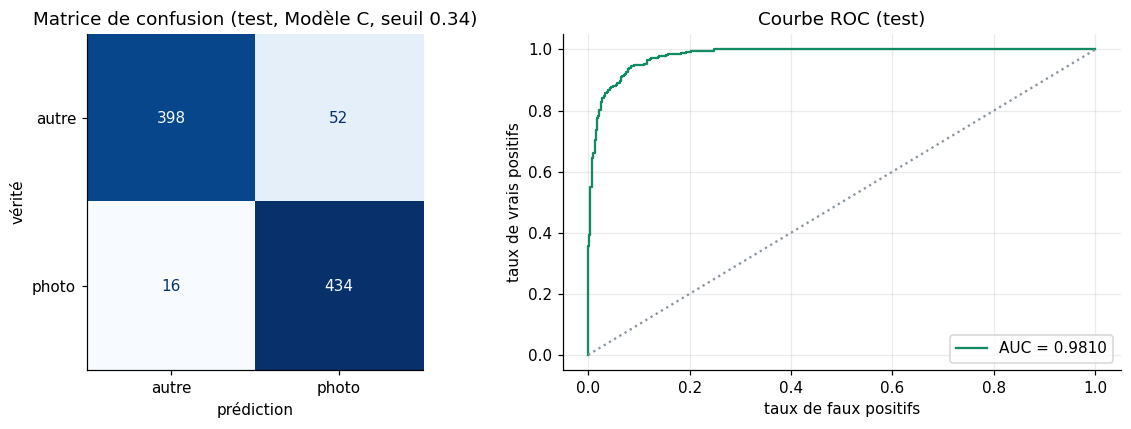

Tableau comparatif sur le jeu de test (900 images, mesure finale) :


,accuracy (%),précision photo (%),rappel photo (%),F1 photo (%),spécificité (%),AUC,erreurs,perte test
"Modèle A, seuil 0,5",90.667,87.810,94.444,91.006,86.889,0.966,84,0.226
"Modèle B, seuil 0,5",92.778,90.188,96.000,93.003,89.556,0.979,65,0.186
"Modèle C, seuil 0,5",92.333,90.275,94.889,92.524,89.778,0.981,69,0.197
"Modèle C, seuil retenu (0.34)",92.444,89.300,96.444,92.735,88.444,0.981,68,0.197


In [ ]:
def indicateurs(vrai, proba, s):
    pred = (proba >= s).astype(int)
    return {"accuracy (%)": 100 * metrics.accuracy_score(vrai, pred),
            "précision photo (%)": 100 * metrics.precision_score(vrai, pred, zero_division=0),
            "rappel photo (%)": 100 * metrics.recall_score(vrai, pred),
            "F1 photo (%)": 100 * metrics.f1_score(vrai, pred),
            "spécificité (%)": 100 * np.mean(pred[vrai == 0] == 0),
            "AUC": metrics.roc_auc_score(vrai, proba)}


resultatsTest = pd.DataFrame({"seuil 0,5": indicateurs(yTest, pTest, 0.5),
                              f"seuil retenu ({seuil:.2f})": indicateurs(yTest, pTest, seuil)}).T
print(f"{choisi} sur le jeu de test ({len(yTest)} images) :")
display(resultatsTest.round(3))

predTest = (pTest >= seuil).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metrics.ConfusionMatrixDisplay(metrics.confusion_matrix(yTest, predTest), display_labels=["autre", "photo"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_xlabel("prédiction")
axes[0].set_ylabel("vérité")
axes[0].set_title(f"Matrice de confusion (test, {choisi}, seuil {seuil:.2f})")
axes[0].grid(False)
fpr, tpr, _ = metrics.roc_curve(yTest, pTest)
axes[1].plot(fpr, tpr, color=VERT, label=f"AUC = {metrics.roc_auc_score(yTest, pTest):.4f}")
axes[1].plot([0, 1], [0, 1], color=GRIS, linestyle="dotted")
axes[1].set_xlabel("taux de faux positifs")
axes[1].set_ylabel("taux de vrais positifs")
axes[1].set_title("Courbe ROC (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

tableauTest = pd.DataFrame({f"{m}, seuil 0,5": indicateurs(yTest, ps["test"], 0.5) for m, ps in predictions.items()}).T
tableauTest.loc[f"{choisi}, seuil retenu ({seuil:.2f})"] = indicateurs(yTest, pTest, seuil)
tableauTest["erreurs"] = [int(round((100 - a) * len(yTest) / 100)) for a in tableauTest["accuracy (%)"]]
tableauTest["perte test"] = [perteLog(yTest, predictions[n.split(",")[0]]["test"]) for n in tableauTest.index]
print(f"Tableau comparatif sur le jeu de test ({len(yTest)} images, mesure finale) :")
display(tableauTest.round(3))

**Ajout (évaluation seulement) : matrices de confusion des trois modèles binaires au seuil 0,5.** Le carnet d'origine ne montrait que celle du modèle retenu ; les trois sont nécessaires pour comparer la répartition des erreurs dans le rapport.

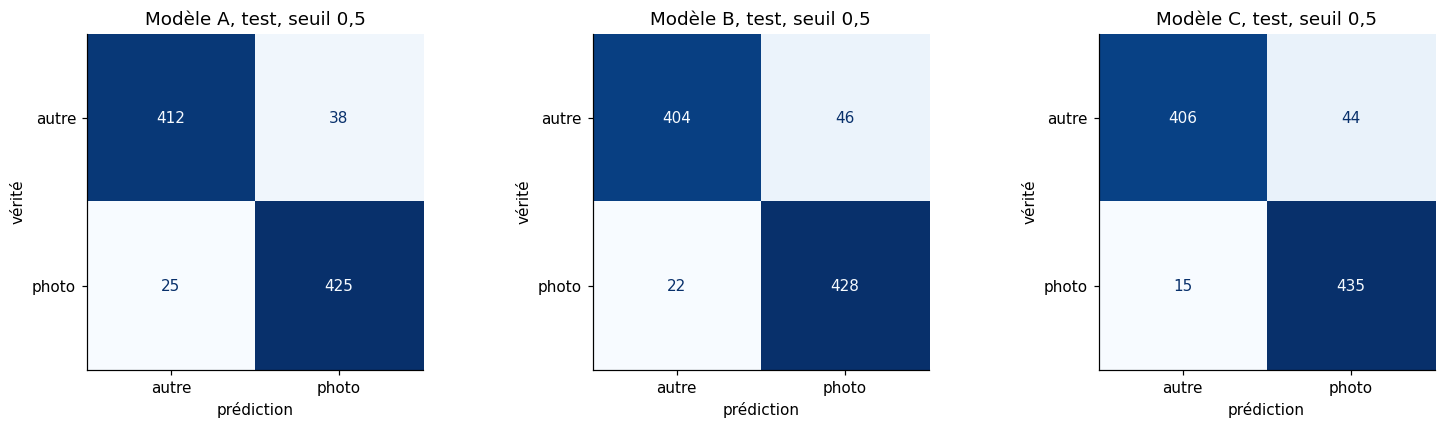

,VN (autres rejetées),FP (autres acceptées),FN (photos perdues),VP (photos gardées)
Modèle A,412,38,25,425
Modèle B,404,46,22,428
Modèle C,406,44,15,435


Erreurs de test par catégorie d'origine (seuil 0,5) :


,Modèle A,Modèle B,Modèle C
catégorie,,,
Dessin,0,1,0
Peinture,36,43,42
Photo,25,22,15
Schéma,2,2,2
Texte,0,0,0


In [35]:
matricesBinaires = {m: metrics.confusion_matrix(yTest, (ps["test"] >= 0.5).astype(int), labels=[0, 1])
                    for m, ps in predictions.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (m, cm) in zip(axes, matricesBinaires.items()):
    metrics.ConfusionMatrixDisplay(cm, display_labels=["autre", "photo"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{m}, test, seuil 0,5")
    ax.set_xlabel("prédiction")
    ax.set_ylabel("vérité")
    ax.grid(False)
plt.tight_layout()
plt.show()
display(pd.DataFrame({m: {"VN (autres rejetées)": cm[0, 0], "FP (autres acceptées)": cm[0, 1],
                          "FN (photos perdues)": cm[1, 0], "VP (photos gardées)": cm[1, 1]}
                      for m, cm in matricesBinaires.items()}).T)
erreursParCategorie = pd.DataFrame({m: pd.Series((ps["test"] >= 0.5) != yTest).groupby(categories[idxTest]).sum()
                                    for m, ps in predictions.items()}).astype(int).rename_axis("catégorie")
print("Erreurs de test par catégorie d'origine (seuil 0,5) :")
display(erreursParCategorie)

,images,erreurs,taux d'erreur (%)
categorie,,,
Dessin,113,0,0.00
Peinture,112,48,42.86
Photo,450,16,3.56
Schéma,113,4,3.54
Texte,112,0,0.00


52 faux positifs et 16 faux négatifs sur 900 images de test (Modèle C, seuil 0.34).


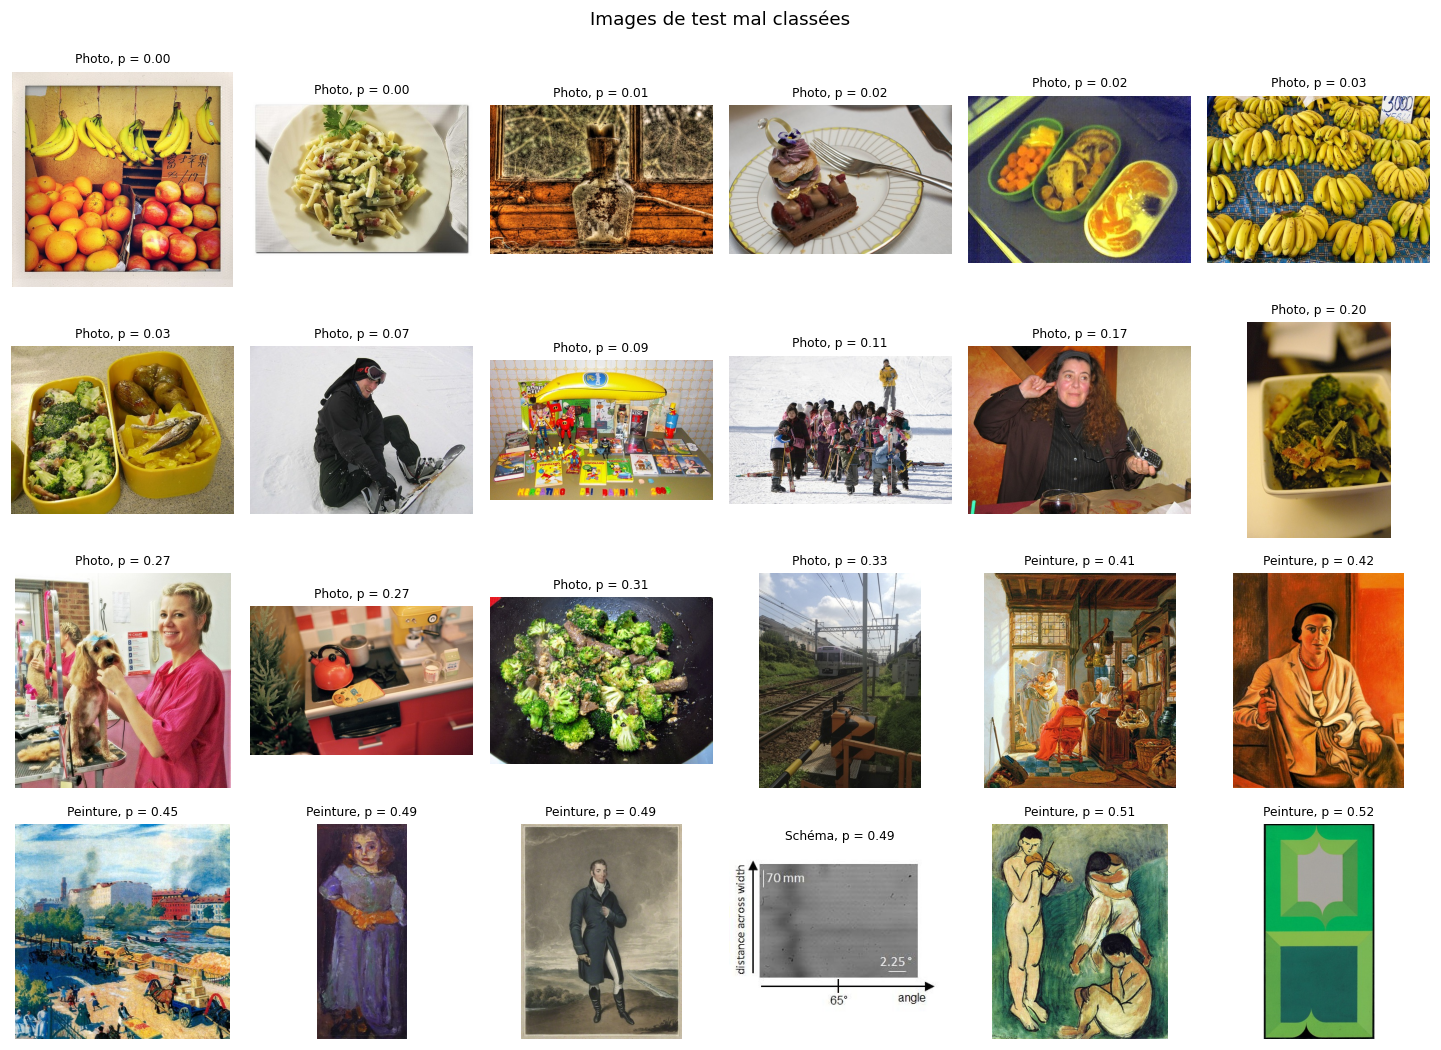

Images dont p(photo) est entre 0,2 et 0,8 : 7.11% du test, avec un taux d'erreur de 43.8% ; elles regroupent 28 erreurs sur 68.


In [ ]:
testDetail = selection.iloc[idxTest].assign(proba=pTest, prediction=predTest)
testDetail["erreur"] = testDetail["prediction"] != testDetail["classe"]
parCategorie = testDetail.groupby("categorie").agg(images=("erreur", "size"), erreurs=("erreur", "sum"))
parCategorie["taux d'erreur (%)"] = (100 * parCategorie["erreurs"] / parCategorie["images"]).round(2)
display(parCategorie)

fautes = testDetail[testDetail["erreur"]].sort_values("proba")
print(f"{int((fautes['classe'] == 0).sum())} faux positifs et {int((fautes['classe'] == 1).sum())} faux négatifs "
      f"sur {len(testDetail)} images de test ({choisi}, seuil {seuil:.2f}).")
if len(fautes):
    titres = [f"{c}, p = {p:.2f}" for c, p in zip(fautes["categorie"], fautes["proba"])]
    planche(fautes["fichier"].tolist()[:24], titres[:24], colonnes=6, cote=2.2, titre="Images de test mal classées")

zone = (pTest > 0.2) & (pTest < 0.8)
print(f"Images dont p(photo) est entre 0,2 et 0,8 : {zone.mean():.2%} du test, "
      f"avec un taux d'erreur de {np.mean(predTest[zone] != yTest[zone]) if zone.any() else 0:.1%} ; "
      f"elles regroupent {int(np.sum(predTest[zone] != yTest[zone]))} erreurs sur {int(np.sum(predTest != yTest))}.")

## 14. Robustesse aux dégradations (section 15)

Les images de test sont dégradées de quatre façons ; aucune dégradation n'a été vue à l'entraînement (pas d'augmentation de données).

### Pourquoi ce choix et pas un autre : tester la robustesse sans augmentation de données

On n'a pas fait d'augmentation pour respecter le protocole commun. Les dégradations (noir et blanc, flou, bruit, compression) montrent donc honnêtement comment le modèle réagit à des images qu'il n'a jamais vues sous cette forme.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Tester sans augmentation</td><td>mesure la vraie fragilité du modèle</td><td>le modèle est forcément moins robuste</td><td>oui</td></tr><tr><td>Entraîner avec augmentation</td><td>modèle plus robuste</td><td>change le protocole et rend la comparaison A, B, C moins nette</td><td>non, piste pour la suite</td></tr>
</table>

In [ ]:
def degrader(tableau, sorte, hasard):
    image = Image.fromarray(tableau)
    if sorte == "noir et blanc":
        image = image.convert("L").convert("RGB")
    elif sorte == "flou (rayon 2)":
        image = image.filter(ImageFilter.GaussianBlur(2))
    elif sorte == "bruit (écart type 25)":
        return np.clip(tableau + hasard.normal(0, 25, tableau.shape), 0, 255).astype(np.uint8)
    elif sorte == "compression JPEG (qualité 10)":
        tampon = io.BytesIO()
        image.save(tampon, "JPEG", quality=10)
        image = Image.open(tampon).convert("RGB")
    return np.asarray(image, dtype=np.uint8)


def predireImages(images224):
    """p(photo) du modèle retenu pour des images 224 × 224 (réduites si le modèle attend une autre taille)."""
    if tailleFinale != TAILLE:
        images224 = np.stack([np.asarray(Image.fromarray(i).resize((tailleFinale, tailleFinale), Image.BILINEAR))
                              for i in images224])
    return modeleFinal.predict(images224.astype("float32"), batch_size=LOT, verbose=0).ravel()


debut = time.time()
lignes = []
for sorte in ["aucune", "noir et blanc", "flou (rayon 2)", "compression JPEG (qualité 10)", "bruit (écart type 25)"]:
    hasard = np.random.default_rng(GRAINE)
    images = X224[idxTest] if sorte == "aucune" else np.stack([degrader(i, sorte, hasard) for i in X224[idxTest]])
    p = predireImages(images)
    lignes.append({"dégradation": sorte, "photos reconnues (%)": 100 * np.mean(p[yTest == 1] >= seuil),
                   "autres rejetées (%)": 100 * np.mean(p[yTest == 0] < seuil)})
robustesse = pd.DataFrame(lignes).set_index("dégradation").round(2)
display(robustesse)
print(f"Calculé en {time.time() - debut:.0f} s.")

,photos reconnues (%),autres rejetées (%)
dégradation,,
aucune,96.00,89.11
noir et blanc,98.89,77.11
flou (rayon 2),88.22,93.11
compression JPEG (qualité 10),96.89,86.89
bruit (écart type 25),94.00,90.67


Calculé en 20 s.


## 15. Sauvegarde du modèle binaire et démonstration (sections 16 et 17)

### Pourquoi ce choix et pas un autre : le format de sauvegarde

Le format .keras garde l'architecture, les poids et l'optimiseur dans un seul fichier. Le fichier JSON à côté garde le seuil et le prétraitement, sans quoi le modèle seul ne suffit pas à refaire les mêmes décisions.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>.keras + configuration JSON</td><td>un seul fichier modèle, seuil et prétraitement documentés</td><td>deux fichiers à garder ensemble</td><td>oui</td></tr><tr><td>SavedModel</td><td>standard pour TensorFlow Serving</td><td>dossier lourd, inutile ici</td><td>non</td></tr><tr><td>Poids seuls (.h5)</td><td>léger</td><td>il faut reconstruire l'architecture</td><td>non</td></tr>
</table>

{
  "modele": "Modèle C",
  "fichierModele": "classifieurPhoto.keras",
  "taille": 128,
  "seuil": 0.3449903428554535,
  "classePositive": "photo",
  "pretraitement": "preparerImage : RGB sur fond blanc, redimensionnement bilinéaire en carré, pixels entre 0 et 255",
  "hyperparametres": {
    "lr": 0.000225189025602935,
    "dropout": 0.2617157968270191,
    "l2": 0.0004920339616385435,
    "neurones": 256,
    "filtres": 40,
    "lot": 32
  },
  "transfertApprentissage": false,
  "fineTuning": false,
  "jeuDeDonnees": {
    "photos": 3000,
    "autresParCategorie": 750,
    "categoriesAutres": [
      "Peinture",
      "Schéma",
      "Dessin",
      "Texte"
    ],
    "augmentation": false
  },
  "performancesTest": {
    "accuracy (%)": 92.4444,
    "précision photo (%)": 89.3004,
    "rappel photo (%)": 96.4444,
    "F1 photo (%)": 92.735,
    "spécificité (%)": 88.4444,
    "AUC": 0.981
  },
  "versionTensorFlow": "2.21.0",
  "date": "11/10/2026 14:24"
}
24 images triées en 3.4 s,

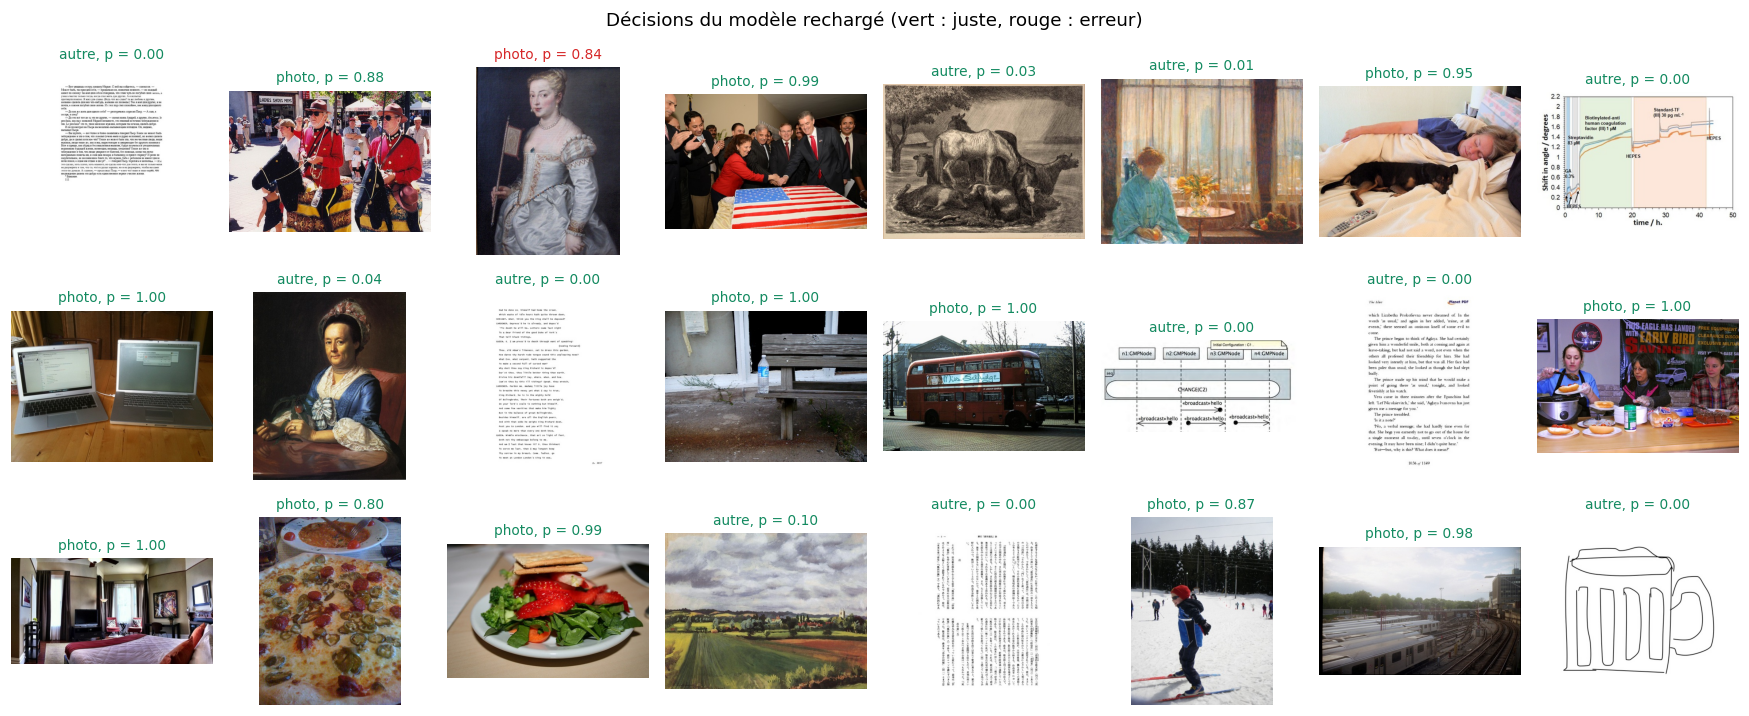

In [ ]:
cheminModele = DOSSIERTRAVAIL / "classifieurPhoto.keras"
modeleFinal.save(cheminModele)
configuration = {
    "modele": choisi,
    "fichierModele": cheminModele.name,
    "taille": int(tailleFinale),
    "seuil": seuil,
    "classePositive": "photo",
    "pretraitement": "preparerImage : RGB sur fond blanc, redimensionnement bilinéaire en carré, pixels entre 0 et 255",
    "hyperparametres": {"Modèle A": HPA, "Modèle B": HPB, "Modèle C": hpC}[choisi],
    "transfertApprentissage": False,
    "fineTuning": False,
    "jeuDeDonnees": {"photos": NPHOTOS, "autresParCategorie": NPARAUTRE,
                     "categoriesAutres": ["Peinture", "Schéma", "Dessin", "Texte"], "augmentation": False},
    "performancesTest": {k: round(float(v), 4) for k, v in resultatsTest.iloc[1].items()},
    "versionTensorFlow": tf.__version__,
    "date": datetime.now().strftime("%d/%m/%Y %H:%M"),
}
with open(DOSSIERTRAVAIL / "configuration.json", "w", encoding="utf8") as f:
    json.dump(configuration, f, ensure_ascii=False, indent=2)
print(json.dumps(configuration, ensure_ascii=False, indent=2))


def chargerClassifieur(dossier):
    with open(Path(dossier) / "configuration.json", encoding="utf8") as f:
        config = json.load(f)
    return keras.models.load_model(Path(dossier) / config["fichierModele"]), config


def trierDossier(dossierEntree, dossierSortie, modele, config):
    chemins = sorted(c for c in Path(dossierEntree).rglob("*") if c.suffix.lower() in EXTENSIONS)
    images = np.stack([preparerImage(c, config["taille"]) for c in chemins]).astype("float32")
    probas = modele.predict(images, verbose=0).ravel()
    if Path(dossierSortie).exists():
        shutil.rmtree(dossierSortie)
    lignes = []
    for chemin, p in zip(chemins, probas):
        decision = "photo" if p >= config["seuil"] else "autre"
        (Path(dossierSortie) / decision).mkdir(parents=True, exist_ok=True)
        shutil.copy2(chemin, Path(dossierSortie) / decision / chemin.name)
        lignes.append({"fichier": chemin.name, "probaPhoto": round(float(p), 3), "decision": decision})
    return pd.DataFrame(lignes)


dossierDemo = DOSSIERTRAVAIL / "demonstration"
if dossierDemo.exists():
    shutil.rmtree(dossierDemo)
(dossierDemo / "entree").mkdir(parents=True)
echantillon = testDetail.groupby("classe").sample(12, random_state=GRAINE).sample(frac=1, random_state=GRAINE)
for numero, fichier in enumerate(echantillon["fichier"]):
    shutil.copy2(DOSSIERSELECTION / fichier, dossierDemo / "entree" / f"image{numero:02d}.jpg")

debut = time.time()
modeleRecharge, configRechargee = chargerClassifieur(DOSSIERTRAVAIL)
tri = trierDossier(dossierDemo / "entree", dossierDemo / "sortie", modeleRecharge, configRechargee)
tri["vérité"] = echantillon["classe"].map({1: "photo", 0: "autre"}).to_numpy()
print(f"{len(tri)} images triées en {time.time() - debut:.1f} s, chargement du modèle compris.")
print(f"Bonnes décisions : {(tri['decision'] == tri['vérité']).sum()} sur {len(tri)}.")
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))
for ax, ligne in zip(axes.ravel(), tri.itertuples()):
    with Image.open(dossierDemo / "entree" / ligne.fichier) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{ligne.decision}, p = {ligne.probaPhoto:.2f}", fontsize=9,
                 color=VERT if ligne.decision == ligne.vérité else ORANGE)
    ax.axis("off")
fig.suptitle("Décisions du modèle rechargé (vert : juste, rouge : erreur)")
plt.tight_layout()
plt.show()

# Analyses finales de la première partie



In [39]:
resultats_finaux = [
    {
        'Modele': 'A',
        'Params': modeleA.count_params(),
        'Epoque retenue': epoqueA,
        'Accuracy Val (%)': 100 - comparaison.loc['Modèle A', 'erreur validation (%)'],
        'Accuracy Test (%)': 100 - erreurs.loc['Modèle A', 'test'],
        'Temps (min)': historiqueA['duree'].iloc[0]
    },
    {
        'Modele': 'B',
        'Params': modeleB.count_params(),
        'Epoque retenue': epoqueB,
        'Accuracy Val (%)': 100 - comparaison.loc['Modèle B', 'erreur validation (%)'],
        'Accuracy Test (%)': 100 - erreurs.loc['Modèle B', 'test'],
        'Temps (min)': historiqueB['duree'].iloc[0]
    },
    {
        'Modele': 'C',
        'Params': modeleC.count_params(),
        'Epoque retenue': epoqueC,
        'Accuracy Val (%)': 100 - comparaison.loc['Modèle C', 'erreur validation (%)'],
        'Accuracy Test (%)': 100 - erreurs.loc['Modèle C', 'test'],
        'Temps (min)': historiqueC['duree'].iloc[0]
    },
]
display(pd.DataFrame(resultats_finaux).set_index('Modele').round(2))

,Params,Epoque retenue,Accuracy Val (%),Accuracy Test (%),Temps (min)
Modele,,,,,
A,97809,26,93.22,93.00,2.26
B,1012385,32,92.33,92.44,2.59
C,1111841,31,93.67,93.44,3.92


# Analyse Comparative
Le tableau présente une comparaison des performances et du coût computationnel entre les trois modèles de classification binaire (A, B et C). L'analyse des données révèle un scénario intéressant où l'augmentation de la complexité du modèle ne se traduit pas linéairement par une meilleure performance.

Le Modèle A, le plus simple avec environ 98 000 paramètres, est également le plus rapide à entraîner (2,26 minutes). Malgré sa simplicité, il affiche une performance robuste, avec 93,22 % de précision en validation et 93,00 % en test. Il établit ainsi une excellente base de référence, démontrant qu'un modèle compact peut résoudre le problème de manière efficace et efficiente.

Le Modèle B représente un saut significatif en complexité, avec plus d'un million de paramètres (une augmentation de plus de 10 fois par rapport au A). Cependant, cette augmentation de capacité n'a pas abouti à une amélioration des performances. Au contraire, il a obtenu la moins bonne performance des trois, avec 92,33 % de précision en validation et 92,44 % en test. Cela suggère que le modèle B pourrait souffrir de surapprentissage (overfitting) ou que son architecture et ses hyperparamètres ne sont pas optimisés pour la tâche, malgré sa plus grande capacité. Son temps d'entraînement était légèrement supérieur à celui du modèle A (2,59 minutes).

Le Modèle C est le plus complexe, avec environ 1,11 million de paramètres, et aussi le plus long à entraîner (3,92 minutes). Néanmoins, il s'est avéré le plus performant, atteignant la meilleure performance globale : 93,67 % de précision en validation et 93,44 % en test. Cela indique que l'optimisation des hyperparamètres (qui est la principale différence entre B et C) a été cruciale pour tirer parti de la capacité accrue du réseau et surpasser la performance du modèle le plus simple.

Conclusion : Le Modèle C est le vainqueur en termes de performance, mais à un coût computationnel plus élevé. Le Modèle A est le plus efficient, offrant une performance presque aussi bonne que le C avec une fraction des paramètres et du temps d'entraînement. Le Modèle B, en revanche, s'est montré le moins efficace, servant d'exemple que plus de paramètres ne signifient pas toujours de meilleurs résultats sans une optimisation adéquate.

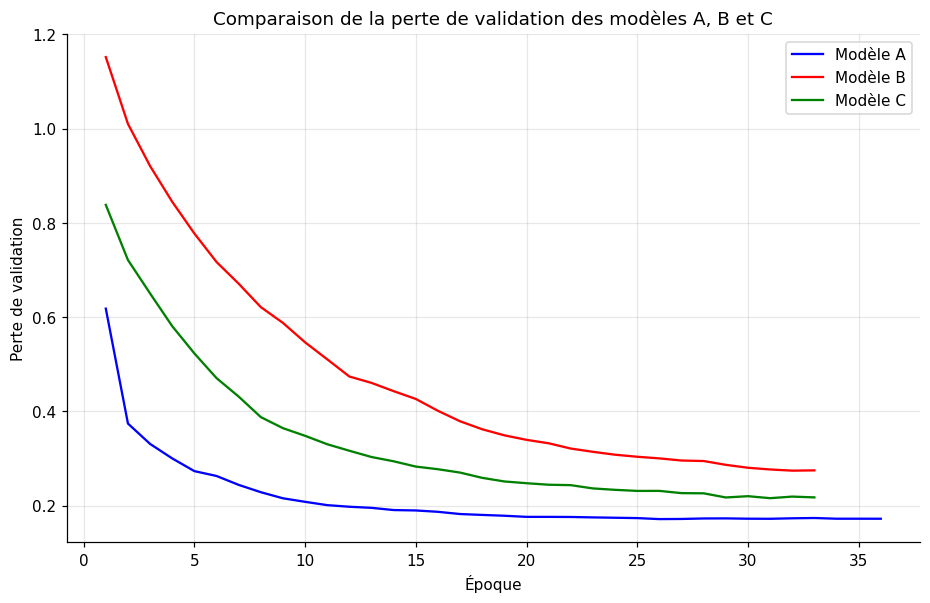

In [41]:
plt.figure(figsize=(10, 6))
plt.plot(historiqueA.index, historiqueA['perteValidation'], color='blue', label='Modèle A')
plt.plot(historiqueB.index, historiqueB['perteValidation'], color='red', label='Modèle B')
plt.plot(historiqueC.index, historiqueC['perteValidation'], color='green', label='Modèle C')
plt.title('Comparaison de la perte de validation des modèles A, B et C')
plt.xlabel('Époque')
plt.ylabel('Perte de validation')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Analyse Comparative
Le graphique « Comparaison de la perte de validation des modèles A, B et C » offre une vision dynamique du processus d'apprentissage de chaque modèle au fil des époques. La perte de validation est une métrique cruciale, car elle indique dans quelle mesure le modèle généralise à des données qu'il n'a pas vues pendant l'entraînement ; des valeurs plus faibles sont donc meilleures.

1. Modèle A (Ligne Bleue) :
Le Modèle A démontre la convergence la plus rapide. Sa courbe de perte chute abruptement dès les premières époques et atteint rapidement un plateau stable, le plus bas des trois modèles (en dessous de 0.2). Cela indique que le modèle, malgré sa simplicité, a appris les motifs essentiels du jeu de données de manière très efficace et sans signes d'instabilité. Il établit une référence très solide pour la perte de validation.

2. Modèle B (Ligne Rouge) :
Le Modèle B présente la moins bonne performance en termes de perte de validation. Sa courbe est la plus élevée tout au long de l'entraînement, commençant à une valeur élevée et diminuant lentement. Même après 30 époques, sa perte de validation reste nettement supérieure à celle des deux autres modèles (au-dessus de 0.25). Cela suggère que l'augmentation de la complexité, sans optimisation adéquate, n'a pas aidé le modèle à mieux généraliser ; au contraire, il semble peiner à trouver un minimum plus stable, ce qui est cohérent avec sa précision plus faible dans le tableau précédent.

3. Modèle C (Ligne Verte) :
Le Modèle C occupe une position intermédiaire. Sa courbe de perte commence plus haut que celle du Modèle A, mais diminue de manière constante et plus douce que celle du Modèle B. Bien qu'il n'atteigne pas le plateau bas du Modèle A, il converge vers une valeur de perte considérablement meilleure que celle du Modèle B (autour de 0.22 à la fin). La forme plus lisse de la courbe peut indiquer un entraînement plus stable, possiblement dû à l'optimisation des hyperparamètres. Cependant, il est intéressant de noter que, malgré une perte de validation plus élevée que celle du Modèle A, le Modèle C a obtenu une précision légèrement supérieure. Cela peut se produire lorsque le modèle fait des prédictions plus « confiantes » (même si certaines sont erronées) ou lorsque la distribution des erreurs est différente.

Conclusion :
Le graphique de la perte de validation renforce l'analyse du tableau de résultats. Le Modèle A est le plus efficient et stable, atteignant la perte de validation la plus faible rapidement. Le Modèle B est le moins efficace, avec la perte la plus élevée, indiquant des problèmes de généralisation. Le Modèle C se situe entre les deux, avec une perte plus élevée que A, mais une courbe d'apprentissage plus saine que B, ce qui lui a permis d'obtenir la meilleure précision finale. Ce graphique est un excellent complément pour comprendre comment chaque modèle a appris, et pas seulement à quel point il a performé à la fin.



---
# PARTIE II — CLASSIFICATION MULTICLASSE (cinq catégories)

## 16. Les cinq catégories et leurs poids

Mêmes images, même découpage. Chaque image porte le poids de sa catégorie (calculé sur l'entraînement), en entraînement, en validation et sur le test : l'accuracy des courbes correspond donc pratiquement à l'accuracy équilibrée.

### Pourquoi ce choix et pas un autre : pondérer les catégories en multiclasse

Il y a 3 000 photos pour 750 images de chaque autre catégorie. Sans poids, le modèle pourrait favoriser la photo. Chaque image reçoit le poids de sa catégorie, aussi en validation et en test, pour que l'accuracy reste équilibrée.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Poids par catégorie</td><td>garde toutes les images, simple</td><td>perte un peu plus bruitée</td><td>oui</td></tr><tr><td>Sous échantillonner les photos à 750</td><td>classes équilibrées</td><td>jette 2 250 photos</td><td>non</td></tr><tr><td>Ne rien faire</td><td>simple</td><td>biais vers la photo</td><td>non</td></tr>
</table>

In [ ]:
CATEGORIESMULTI = ["Photo", "Peinture", "Schéma", "Dessin", "Texte"]   # numéros 0 à 4, la photo est la catégorie 0
NCATEGORIES = len(CATEGORIESMULTI)
yMulti = selection["categorie"].map({c: k for k, c in enumerate(CATEGORIESMULTI)}).to_numpy().astype("int32")
yMultiEntr, yMultiVal, yMultiTest = yMulti[idxEntr], yMulti[idxVal], yMulti[idxTest]

# Poids d'une catégorie : effectif moyen d'une catégorie divisé par son effectif (calculé sur l'entraînement seulement)
effectifs = np.bincount(yMultiEntr, minlength=NCATEGORIES)
poidsCategories = {k: float(len(yMultiEntr) / (NCATEGORIES * n)) for k, n in enumerate(effectifs)}
display(pd.DataFrame({"images d'entraînement": effectifs,
                      "part (%)": (100 * effectifs / effectifs.sum()).round(1),
                      "poids dans la perte": [round(poidsCategories[k], 2) for k in range(NCATEGORIES)]},
                     index=pd.Index(CATEGORIESMULTI, name="catégorie")))


def poidsDe(etiquettes):
    """Poids de chaque image d'après sa catégorie."""
    return np.array([poidsCategories[int(k)] for k in etiquettes], dtype="float32")


def perteEquilibree(vrai, proba):
    """Entropie croisée où chaque catégorie pèse autant (mêmes poids qu'à l'entraînement, sans régularisation)."""
    p = np.clip(proba.astype("float64"), 1e-7, 1)
    p /= p.sum(axis=1, keepdims=True)
    return metrics.log_loss(vrai, p, sample_weight=poidsDe(vrai), labels=list(range(NCATEGORIES)))


def indicateursMulti(vrai, proba):
    """Indicateurs globaux d'une prédiction à cinq catégories (une ligne de cinq probabilités par image)."""
    pred = proba.argmax(axis=1)
    return {"accuracy (%)": 100 * metrics.accuracy_score(vrai, pred),
            "accuracy équilibrée (%)": 100 * metrics.balanced_accuracy_score(vrai, pred),
            "F1 macro (%)": 100 * metrics.f1_score(vrai, pred, average="macro", labels=list(range(NCATEGORIES)),
                                                   zero_division=0),
            "perte équilibrée": perteEquilibree(vrai, proba)}

,images d'entraînement,part (%),poids dans la perte
catégorie,,,
Photo,2100,50.0,0.4
Peinture,525,12.5,1.6
Schéma,525,12.5,1.6
Dessin,525,12.5,1.6
Texte,525,12.5,1.6


In [ ]:
jeuValMulti128 = jeuTF(TAILLECNN, idxVal, yMultiVal, poids=poidsDe(yMultiVal))
jeuTestMulti128 = jeuTF(TAILLECNN, idxTest, yMultiTest, poids=poidsDe(yMultiTest))
sousEntr = np.sort(np.random.default_rng(GRAINE).choice(idxEntr, min(1050, len(idxEntr)), replace=False))
jeuSousEntrMulti128 = jeuTF(TAILLECNN, sousEntr, yMulti[sousEntr], poids=poidsDe(yMulti[sousEntr]))

## 17. Modèle E (carnet du modèle E)

Le CNN régularisé des modèles B et C (GroupNormalization) avec cinq sorties softmax, perte pondérée par catégorie, pas en montée puis cosinus, moyenne mobile des poids, arrêt anticipé avec patience 10 surveillé dès l'époque 9, au plus 60 époques. Hyperparamètres du carnet E : lr 7e-4, dropout 0,6, L2 1,5e-3, 128 neurones, 32 filtres, lots de 32.

### Pourquoi ce choix et pas un autre : le modèle E

E reprend l'architecture qui a le mieux marché en binaire (celle de B et C) et passe à cinq sorties softmax. Avec plus de classes, on a gardé une régularisation forte et une patience de 10 pour lui laisser le temps de converger.

<table>
<tr><th></th><th>Modèle E</th><th>Modèle D</th></tr>
<tr><td>Normalisation</td><td>GroupNormalization</td><td>BatchNormalization (inertie 0,95)</td></tr><tr><td>Taux d'apprentissage</td><td>0,0007</td><td>0,0002, divisé si zigzags</td></tr><tr><td>Dropout</td><td>0,6</td><td>0,45</td></tr><tr><td>L2</td><td>0,0015</td><td>0,0003</td></tr><tr><td>Lots</td><td>32</td><td>64</td></tr><tr><td>Époques au plus</td><td>60</td><td>40</td></tr>
</table>

Epoch 1/60
132/132 - 51s - 384ms/step - accuracy: 0.2310 - loss: 3.0989 - val_accuracy: 0.3769 - val_loss: 2.4555
Epoch 2/60
132/132 - 4s - 34ms/step - accuracy: 0.4300 - loss: 2.3060 - val_accuracy: 0.6213 - val_loss: 1.7644
Epoch 3/60
132/132 - 5s - 34ms/step - accuracy: 0.5995 - loss: 1.7266 - val_accuracy: 0.7182 - val_loss: 1.4004
Epoch 4/60
132/132 - 5s - 36ms/step - accuracy: 0.5928 - loss: 1.5714 - val_accuracy: 0.6973 - val_loss: 1.2762
Epoch 5/60
132/132 - 4s - 32ms/step - accuracy: 0.6671 - loss: 1.2776 - val_accuracy: 0.7369 - val_loss: 1.1158
Epoch 6/60
132/132 - 4s - 33ms/step - accuracy: 0.7402 - loss: 1.0676 - val_accuracy: 0.8093 - val_loss: 0.9519
Epoch 7/60
132/132 - 5s - 36ms/step - accuracy: 0.7680 - loss: 0.9560 - val_accuracy: 0.8280 - val_loss: 0.8444
Epoch 8/60
132/132 - 4s - 32ms/step - accuracy: 0.7979 - loss: 0.8630 - val_accuracy: 0.8427 - val_loss: 0.7680
Epoch 9/60
132/132 - 4s - 34ms/step - accuracy: 0.7830 - loss: 0.8608 - val_accuracy: 0.8471 - val_los

Model: "ModeleE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn1 (GroupNormalization)        │ (None, 128, 128, 32)   │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn2 (GroupNormalization)        │ (None, 64, 64, 64)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn3 (GroupNormalization)        │ (None, 32, 32, 128)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn4 (GroupNormalization)        │ (None, 16, 16, 256)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gn5 (GroupNormalization)        │ (None, 8, 8, 256)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (Activation)              │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool5 (MaxPooling2D)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moyenneGlobale                  │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,038,709 (11.59 MB)

 Trainable params: 1,012,901 (3.86 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,025,808 (7.73 MB)

Modèle E entraîné en 4.8 minutes, enregistré dans modeleE_e5c8ff2e.keras.


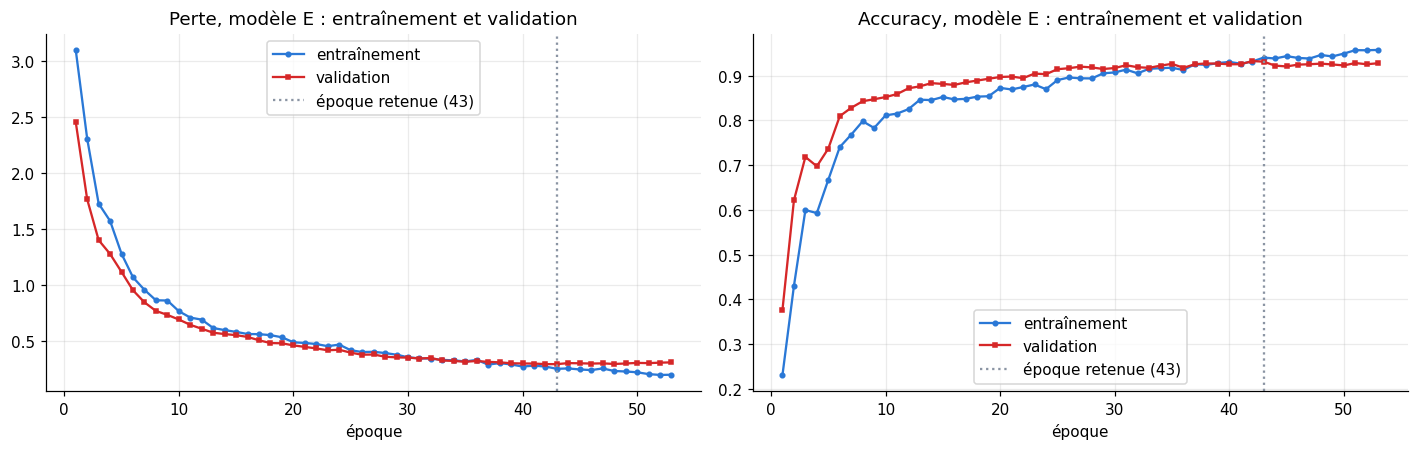

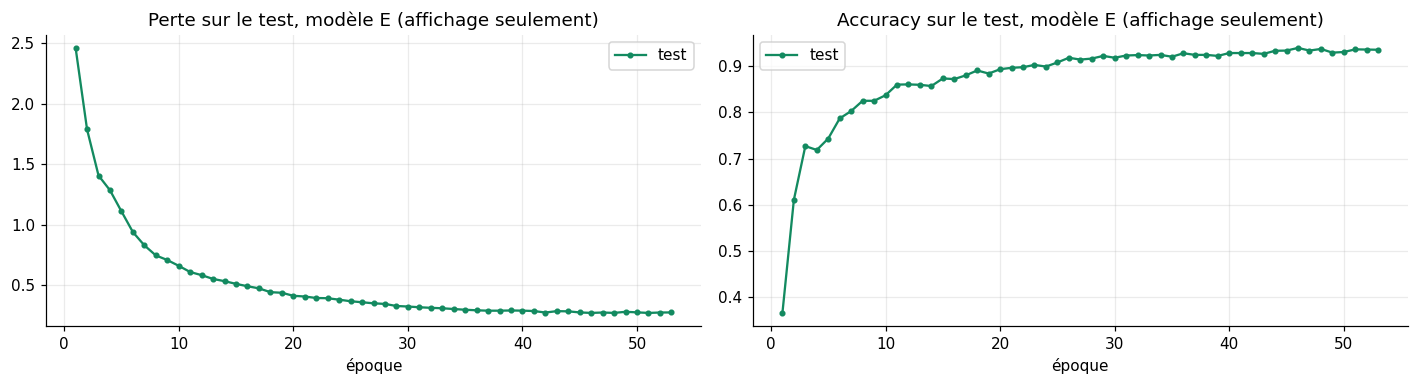

Modèle E, époque retenue 43 sur 53 :
  accuracy entraînement 94.01 %, validation 93.11 % (test, pour information : 92.71 %)
  perte de validation en fin d'entraînement : 1.05 fois sa valeur à l'époque retenue
  accuracy d'entraînement en mode prédiction (sous-ensemble fixe) : 95.72 %


In [ ]:
precisionMixte()   # comme dans le carnet du modèle E (la recherche du modèle C a remis la politique par défaut)


def entrainerE():
    suiviPrediction = SuiviModePrediction(jeuSousEntrMulti128)
    modele, historique = entrainerCNN(HPE, GRAINE + 2000, EPOQUESE, PATIENCEE, DEBUTARRETE, nSorties=NCATEGORIES,
                                      nom="ModeleE", suivis=[SuiviTest(jeuTestMulti128), suiviPrediction], verbose=2)
    modele.summary()
    return modele, historique.assign(accuracyModePrediction=suiviPrediction.accuracy)


modeleE, historiqueE = entrainerOuRecharger("E", {"HPE": HPE, "epoques": EPOQUESE, "patience": PATIENCEE,
                                                  "debut": DEBUTARRETE}, entrainerE)
epoqueE = meilleureEpoque(historiqueE, debutSurveillance(EPOQUESE, DEBUTARRETE))
tracerCourbes("modèle E", historiqueE, epoqueE)
resumerEntrainement("Modèle E", historiqueE, epoqueE)
print(f"  accuracy d'entraînement en mode prédiction (sous-ensemble fixe) : "
      f"{100 * historiqueE.loc[epoqueE, 'accuracyModePrediction']:.2f} %")

## 18. Modèle D (carnet du modèle D, version v3)

Code propre au carnet D, gardé à part (suffixe D) car il diffère du CNN des modèles B, C et E : BatchNormalization (inertie 0,95), couche dense ReLU avec biais, dropout 0,45 avant et après, L2 3e-4, Adam avec `clipnorm = 0.5`, pas en montée sur 5 époques puis cosinus jusqu'à 1e-6, lots tirés par un `PyDataset`, et **contrôle des zigzags** : si la perte de validation fait plus de 3 remontées brusques avant son minimum, l'entraînement recommence avec un pas deux fois plus petit (deux reprises au plus).

### Pourquoi ce choix et pas un autre : le modèle D avec BatchNormalization

D sert à vérifier si BatchNormalization, plus courant, fait mieux que GroupNormalization. Comme BatchNormalization peut rendre la perte instable, on a ajouté un contrôle des zigzags qui relance l'entraînement avec un pas plus petit.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>BatchNormalization + contrôle des zigzags (D)</td><td>normalisation la plus courante, entraînement stabilisé</td><td>code plus long</td><td>oui, en comparaison avec E</td></tr><tr><td>Même réseau que E, réglages différents</td><td>comparaison plus simple</td><td>ne teste qu'une seule idée</td><td>non</td></tr>
</table>

In [ ]:
class LotsImages(keras.utils.PyDataset):
    """Lots (images, étiquettes[, poids]) pris directement dans le tableau d'images, sans le recopier.
    Les entiers 0 à 255 sont convertis en réels lot par lot. L'ordre est remélangé à chaque époque si demandé."""

    def __init__(self, images, indices, etiquettes, lot, melanger, poids=None):
        super().__init__()
        self.images, self.indices = images, np.asarray(indices)
        self.etiquettes = np.asarray(etiquettes)
        self.poids = None if poids is None else np.asarray(poids, dtype="float32")
        self.lot, self.melanger = int(lot), melanger
        self.hasard = np.random.default_rng(GRAINE)
        self.ordre = self.hasard.permutation(len(self.indices)) if melanger else np.arange(len(self.indices))

    def __len__(self):
        return math.ceil(len(self.indices) / self.lot)

    def __getitem__(self, k):
        choix = self.ordre[k * self.lot:(k + 1) * self.lot]
        x = self.images[self.indices[choix]].astype("float32")
        y = self.etiquettes[choix]
        return (x, y) if self.poids is None else (x, y, self.poids[choix])

    def on_epoch_end(self):
        if self.melanger:
            self.ordre = self.hasard.permutation(len(self.indices))


def jeuD(indices, etiquettes, lot=LOT, melanger=False, poids=None):
    return LotsImages(X128, indices, etiquettes, lot, melanger, poids)


def blocsConvolutionD(x, regularise, filtresBase=32, l2=1e-4, convs=1):
    for numero, multiple in enumerate([1, 2, 4, 8, 8], start=1):
        filtres = int(filtresBase * multiple)
        if regularise:
            for k in range(1, int(convs) + 1):
                suffixe = "" if k == 1 else f"b{k}"
                x = layers.Conv2D(filtres, 3, padding="same", use_bias=False,
                                  kernel_regularizer=regularizers.l2(l2), name=f"conv{numero}{suffixe}")(x)
                x = layers.BatchNormalization(momentum=INERTIEBND, name=f"bn{numero}{suffixe}")(x)
                x = layers.Activation("relu", name=f"relu{numero}{suffixe}")(x)
        else:
            x = layers.Conv2D(filtres, 3, padding="same", activation="relu", name=f"conv{numero}")(x)
        x = layers.MaxPooling2D(name=f"pool{numero}")(x)
    return x


def construireCNND(hp, nSorties, nom="ModeleD"):
    taille = int(hp.get("taille", TAILLECNN))
    entree = keras.Input((taille, taille, 3), name="image")
    x = layers.Rescaling(1 / 255, name="normalisation")(entree)
    x = blocsConvolutionD(x, regularise=True, filtresBase=hp["filtres"], l2=hp["l2"], convs=hp.get("convs", 1))
    x = layers.GlobalAveragePooling2D(name="moyenneGlobale")(x)
    x = layers.Dropout(hp["dropout"], name="dropout1")(x)
    x = layers.Dense(int(hp["neurones"]), activation="relu", kernel_regularizer=regularizers.l2(hp["l2"]), name="dense")(x)
    x = layers.Dropout(hp["dropout"], name="dropout2")(x)
    sortie = layers.Dense(nSorties, activation="softmax", dtype="float32", name="probaCategories")(x)
    modele = keras.Model(entree, sortie, name=nom)
    modele.compile(optimizer=keras.optimizers.Adam(hp["lr"], clipnorm=CLIPNORMD), loss="sparse_categorical_crossentropy",
                   weighted_metrics=["accuracy"])
    return modele


def pasCosinus(pic, epoques):
    """Montée linéaire sur ECHAUFFEMENTD époques, puis descente en cosinus jusqu'à PLANCHERPAS."""
    def pas(epoque, *_):
        if epoque < ECHAUFFEMENTD:
            return pic * (epoque + 1) / ECHAUFFEMENTD
        t = (epoque - ECHAUFFEMENTD) / max(1, epoques - ECHAUFFEMENTD)
        return PLANCHERPAS + 0.5 * (pic - PLANCHERPAS) * (1 + math.cos(math.pi * min(t, 1.0)))
    return pas


def indiceZigzag(historique):
    """Nombre de remontées brusques de la perte de validation avant son minimum (plus de 15 % de l'amplitude)."""
    v = historique["perteValidation"].to_numpy()
    if len(v) > ECHAUFFEMENTD + 3:
        v = v[ECHAUFFEMENTD:]
    if len(v) < 3:
        return 0
    amplitude = max(v.max() - v.min(), 1e-6)
    avantMinimum = v[:int(np.argmin(v)) + 1]
    return int((np.diff(avantMinimum) / amplitude > 0.15).sum())


def entrainerCNND(hp, graine, epoques, nSorties, nom, suivis=(), verbose=0):
    keras.utils.set_random_seed(graine)
    modele = construireCNND(hp, nSorties, nom)
    jeuEntr = jeuD(idxEntr, yMultiEntr, lot=int(hp["lot"]), melanger=True, poids=poidsDe(yMultiEntr))
    jeuVal = jeuD(idxVal, yMultiVal, poids=poidsDe(yMultiVal))
    debut = debutSurveillance(epoques, DEBUTARRETD)
    rappels = [MeilleursPoids(debut=debut),
               keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCED, start_from_epoch=debut),
               keras.callbacks.LearningRateScheduler(pasCosinus(hp["lr"], epoques))] + list(suivis)
    historique = modele.fit(jeuEntr, validation_data=jeuVal, epochs=epoques, callbacks=rappels, shuffle=False,
                            verbose=verbose)
    return modele, historiqueDe(historique, next((s for s in suivis if isinstance(s, SuiviTest)), None))


TENTATIVESD = []


def entrainerStableD(hp, graine, epoques, **options):
    """Entraîne le CNN ; si la perte de validation fait trop de zigzags, recommence avec un pas deux fois plus petit."""
    hp = dict(hp)
    for tentative in range(REESSAISZIGZAG + 1):
        modele, historique = entrainerCNND(hp, graine, epoques, **options)
        zig = indiceZigzag(historique)
        TENTATIVESD.append(historique.assign(tentative=tentative + 1, pasDepart=hp["lr"], zigzag=zig))
        if zig <= SEUILZIGZAG or tentative == REESSAISZIGZAG:
            historique["pasDepart"], historique["zigzag"], historique["reprises"] = hp["lr"], zig, tentative
            return modele, historique
        print(f"  validation en zigzag ({zig} remontées brusques, plus de {SEUILZIGZAG}) : pas divisé par deux, "
              f"{hp['lr']:.1e} devient {hp['lr'] / 2:.1e}, nouvel entraînement")
        hp["lr"] /= 2
        del modele
        keras.backend.clear_session()
        gc.collect()

Epoch 1/40
66/66 - 38s - 577ms/step - accuracy: 0.4767 - loss: 1.6549 - val_accuracy: 0.4640 - val_loss: 1.7322 - learning_rate: 4.0000e-05
Epoch 2/40
66/66 - 3s - 41ms/step - accuracy: 0.6755 - loss: 1.0618 - val_accuracy: 0.7373 - val_loss: 0.8891 - learning_rate: 8.0000e-05
Epoch 3/40
66/66 - 3s - 41ms/step - accuracy: 0.7510 - loss: 0.8427 - val_accuracy: 0.7996 - val_loss: 0.6979 - learning_rate: 1.2000e-04
Epoch 4/40
66/66 - 3s - 40ms/step - accuracy: 0.7904 - loss: 0.7461 - val_accuracy: 0.8662 - val_loss: 0.5560 - learning_rate: 1.6000e-04
Epoch 5/40
66/66 - 3s - 43ms/step - accuracy: 0.8182 - loss: 0.6562 - val_accuracy: 0.8396 - val_loss: 0.7014 - learning_rate: 2.0000e-04
Epoch 6/40
66/66 - 3s - 42ms/step - accuracy: 0.8386 - loss: 0.6119 - val_accuracy: 0.6729 - val_loss: 1.1590 - learning_rate: 2.0000e-04
Epoch 7/40
66/66 - 3s - 40ms/step - accuracy: 0.8725 - loss: 0.5503 - val_accuracy: 0.7244 - val_loss: 1.0710 - learning_rate: 1.9960e-04
Epoch 8/40
66/66 - 2s - 38ms/ste

Model: "ModeleD"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 8, 8, 256)      │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (Activation)              │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool5 (MaxPooling2D)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ moyenneGlobale                  │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,039,793 (11.60 MB)

 Trainable params: 1,012,773 (3.86 MB)

 Non-trainable params: 1,472 (5.75 KB)

 Optimizer params: 2,025,548 (7.73 MB)

Modèle D entraîné en 9.4 minutes, enregistré dans modeleD_1573b63d.keras.
Pas de départ de l'entraînement retenu : 5.0e-05 (2 reprise(s), 2 remontée(s) brusque(s))


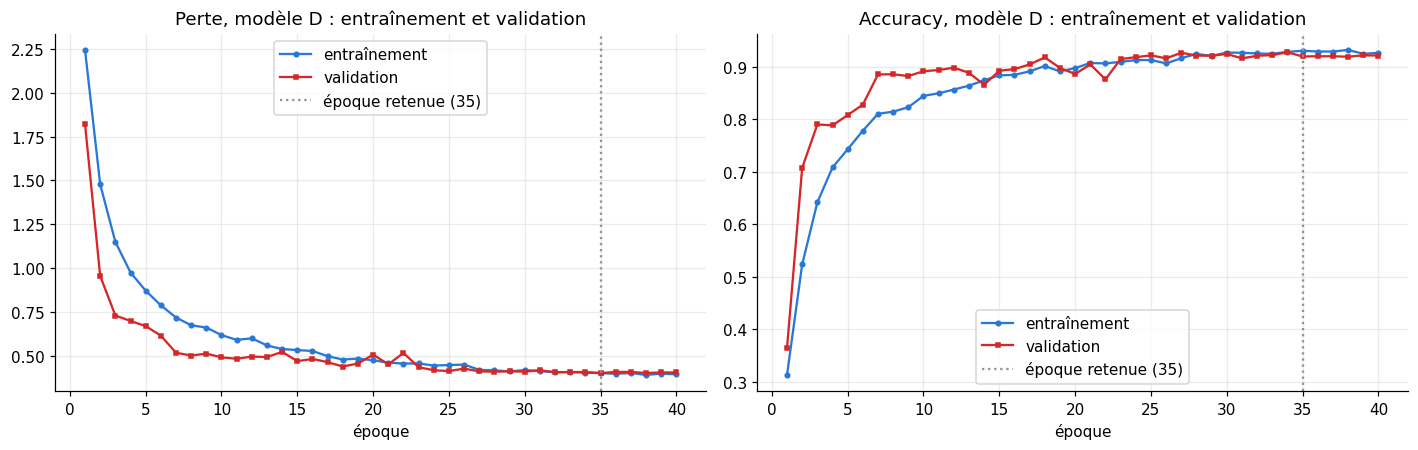

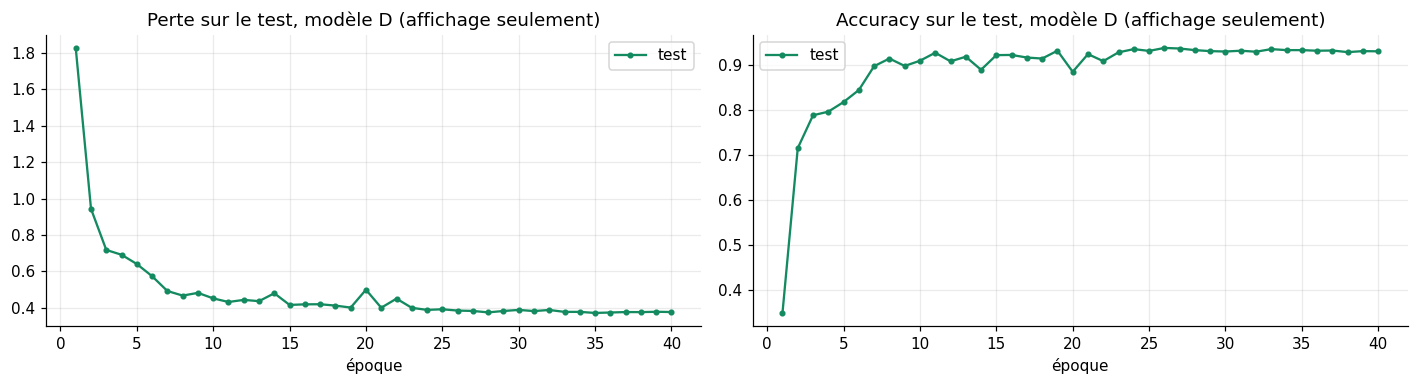

Modèle D, époque retenue 35 sur 40 :
  accuracy entraînement 93.00 %, validation 91.91 % (test, pour information : 93.29 %)
  perte de validation en fin d'entraînement : 1.01 fois sa valeur à l'époque retenue
  accuracy d'entraînement en mode prédiction (sous-ensemble fixe) : 96.49 %


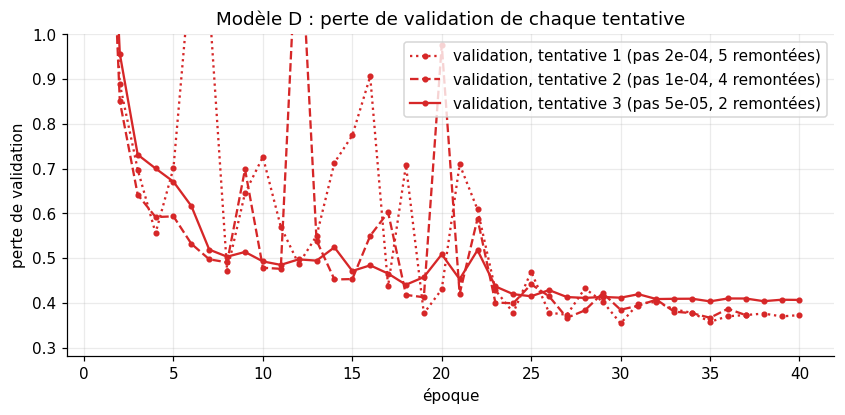

In [ ]:
precisionMixte()   # comme dans le carnet du modèle D
jeuTestMultiD = jeuD(idxTest, yMultiTest, poids=poidsDe(yMultiTest))
jeuSousEntrMultiD = jeuD(sousEntr, yMulti[sousEntr], poids=poidsDe(yMulti[sousEntr]))


def entrainerD():
    suiviPrediction = SuiviModePrediction(jeuSousEntrMultiD)
    modele, historique = entrainerStableD(HPD, GRAINE, EPOQUESD, nSorties=NCATEGORIES, nom="ModeleD",
                                          suivis=[SuiviTest(jeuTestMultiD), suiviPrediction], verbose=2)
    modele.summary()
    pd.concat(TENTATIVESD).to_csv(DOSSIERTRAVAIL / f"tentativesD_{cleConfiguration(configD)}.csv")
    return modele, historique.assign(accuracyModePrediction=suiviPrediction.accuracy)


configD = {"HPD": HPD, "epoques": EPOQUESD, "patience": PATIENCED, "debut": DEBUTARRETD, "inertie": INERTIEBND,
           "zigzag": [SEUILZIGZAG, REESSAISZIGZAG], "echauffement": ECHAUFFEMENTD, "plancher": PLANCHERPAS,
           "clipnorm": CLIPNORMD}
modeleD, historiqueD = entrainerOuRecharger("D", configD, entrainerD)
epoqueD = meilleureEpoque(historiqueD, debutSurveillance(EPOQUESD, DEBUTARRETD))
print(f"Pas de départ de l'entraînement retenu : {historiqueD['pasDepart'].iloc[0]:.1e} "
      f"({int(historiqueD['reprises'].iloc[0])} reprise(s), {int(historiqueD['zigzag'].iloc[0])} remontée(s) brusque(s))")
tracerCourbes("modèle D", historiqueD, epoqueD)
resumerEntrainement("Modèle D", historiqueD, epoqueD)
print(f"  accuracy d'entraînement en mode prédiction (sous-ensemble fixe) : "
      f"{100 * historiqueD.loc[epoqueD, 'accuracyModePrediction']:.2f} %")

fichierTentatives = DOSSIERTRAVAIL / f"tentativesD_{cleConfiguration(configD)}.csv"
if fichierTentatives.exists():
    tentatives = pd.read_csv(fichierTentatives)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for (t, h), style in zip(tentatives.groupby("tentative"), [":", "--", "-"]):
        ax.plot(h["epoque"], h["perteValidation"], color=ORANGE, linestyle=style, marker="o", markersize=3,
                label=f"validation, tentative {t} (pas {h['pasDepart'].iloc[0]:.0e}, {h['zigzag'].iloc[0]} remontées)")
    ax.set_ylim(top=min(1.0, tentatives["perteValidation"].max()))
    ax.set_xlabel("époque")
    ax.set_ylabel("perte de validation")
    ax.set_title("Modèle D : perte de validation de chaque tentative")
    ax.legend()
    plt.show()

## 19. Biais, variance et choix du modèle multiclasse (section 18.3)

Les deux modèles sont recalculés en mode prédiction sur l'entraînement et la validation. Repères appliqués à l'erreur équilibrée (100 moins l'accuracy équilibrée) : biais élevé au-dessus de 5 %, variance élevée au-dessus de 2 points d'écart ; un écart de plus de 10 points entre les deux modes signale un problème de mesure. Le modèle retenu est celui dont la **perte équilibrée de validation** est la plus faible (critère du carnet principal).

### Pourquoi ce choix et pas un autre : le choix entre D et E

On choisit sur la perte équilibrée de validation, le même critère qu'en binaire. D gagne sur ce critère même si E a un meilleur F1 macro, parce que D est plus confiant quand il a raison.

<table>
<tr><th>Modèle</th><th>Accuracy équilibrée val.</th><th>F1 macro val.</th><th>Perte équilibrée val.</th><th>Retenu ?</th></tr>
<tr><td>Modèle D</td><td>91,92 %</td><td>90,42 %</td><td>0,189</td><td>oui</td></tr><tr><td>Modèle E</td><td>93,12 %</td><td>92,14 %</td><td>0,201</td><td>non</td></tr>
</table>

Tableau comparatif multiclasse en entraînement et en validation (mode prédiction) :


accuracy (%)  accuracy équilibrée (%)  F1 macro (%)  perte équilibrée
modèle   jeu                                                                                
Modèle D entraînement        94.119                   96.190        94.519             0.108
         validation          89.778                   91.922        90.416             0.189
Modèle E entraînement        94.595                   95.324        94.747             0.120
         validation          92.111                   93.122        92.139             0.201

  Modèle D : erreur équilibrée d'entraînement 3.81 %, écart validation entraînement +4.27 points, écart entre les modes -3.19 points → variance élevée
  Modèle E : erreur équilibrée d'entraînement 4.68 %, écart validation entraînement +2.20 points, écart entre les modes -1.31 points → variance élevée


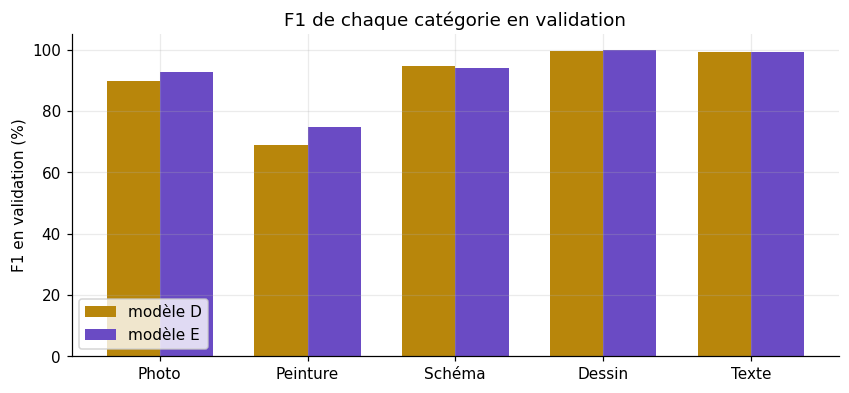

Perte de validation équilibrée : {'Modèle D': 0.1894, 'Modèle E': 0.2013}
Modèle multiclasse retenu : Modèle D


In [ ]:
probasMulti = {
    "Modèle D": {jeu: predire(modeleD, idx) for jeu, idx in
                 [("entraînement", idxEntr), ("validation", idxVal), ("test", idxTest)]},
    "Modèle E": {jeu: predire(modeleE, idx) for jeu, idx in
                 [("entraînement", idxEntr), ("validation", idxVal), ("test", idxTest)]},
}
vraisMulti = {"entraînement": yMultiEntr, "validation": yMultiVal, "test": yMultiTest}
comparaisonMulti = pd.DataFrame([{"modèle": m, "jeu": jeu, **indicateursMulti(vraisMulti[jeu], ps[jeu])}
                                 for m, ps in probasMulti.items() for jeu in ["entraînement", "validation"]])
print("Tableau comparatif multiclasse en entraînement et en validation (mode prédiction) :")
display(comparaisonMulti.set_index(["modèle", "jeu"]).round(3))

epoquesRetenues = {"Modèle D": (historiqueD, epoqueD), "Modèle E": (historiqueE, epoqueE)}
for modele, ps in probasMulti.items():
    biais = erreurEquilibree(yMultiEntr, ps["entraînement"].argmax(axis=1))
    ecart = erreurEquilibree(yMultiVal, ps["validation"].argmax(axis=1)) - biais
    historique, epoque = epoquesRetenues[modele]
    decalage = 100 * historique.loc[epoque, "accuracy"] - (100 - biais)
    if decalage > 10:
        verdict = [f"décalage de {decalage:.0f} points entre mode entraînement et mode prédiction"]
    else:
        verdict = (["biais élevé"] if biais > 5 else []) + (["variance élevée"] if ecart > 2 else [])
    print(f"  {modele} : erreur équilibrée d'entraînement {biais:.2f} %, écart validation entraînement {ecart:+.2f} points, "
          f"écart entre les modes {decalage:+.2f} points → " + (", ".join(verdict) if verdict else "bon compromis"))

f1Categories = pd.DataFrame({m: 100 * metrics.f1_score(yMultiVal, ps["validation"].argmax(axis=1), average=None,
                                                       labels=list(range(NCATEGORIES)), zero_division=0)
                             for m, ps in probasMulti.items()}, index=CATEGORIESMULTI)
fig, ax = plt.subplots(figsize=(9, 3.8))
positions = np.arange(NCATEGORIES)
ax.bar(positions - 0.18, f1Categories["Modèle D"], 0.36, color="#b8860b", label="modèle D")
ax.bar(positions + 0.18, f1Categories["Modèle E"], 0.36, color="#6a4bc4", label="modèle E")
ax.set_xticks(positions, CATEGORIESMULTI)
ax.set_ylabel("F1 en validation (%)")
ax.set_ylim(0, 105)
ax.set_title("F1 de chaque catégorie en validation")
ax.legend(loc="lower left")
plt.show()

pertesValMulti = {m: round(perteEquilibree(yMultiVal, ps["validation"]), 4) for m, ps in probasMulti.items()}
choisiMulti = min(pertesValMulti, key=pertesValMulti.get)
modeleMultiFinal, tailleMulti = {"Modèle D": (modeleD, TAILLECNN), "Modèle E": (modeleE, TAILLECNN)}[choisiMulti]
pMultiVal, pMultiTest = probasMulti[choisiMulti]["validation"], probasMulti[choisiMulti]["test"]
print("Perte de validation équilibrée :", pertesValMulti)
print("Modèle multiclasse retenu :", choisiMulti)

## 20. Évaluation finale multiclasse sur le test (section 18.4)

### Pourquoi ce choix et pas un autre : les indicateurs multiclasses

Le F1 macro donne le même poids à chaque catégorie, donc une catégorie rare mal reconnue fait baisser le score. C'est plus juste que l'accuracy simple quand les classes ne sont pas de la même taille.

<table>
<tr><th>Indicateur</th><th>Ce qu'il mesure</th><th>Retenu ?</th></tr>
<tr><td>Accuracy simple</td><td>part de bonnes réponses</td><td>affiché, mais pas pour décider</td></tr><tr><td>Accuracy équilibrée</td><td>moyenne des rappels par catégorie</td><td>oui</td></tr><tr><td>F1 macro</td><td>moyenne des F1 par catégorie</td><td>oui</td></tr><tr><td>Matrice de confusion</td><td>quelles catégories se confondent</td><td>oui</td></tr>
</table>

In [ ]:
predMultiTest = pMultiTest.argmax(axis=1)
precisionCat, rappelCat, f1Cat, supportCat = metrics.precision_recall_fscore_support(
    yMultiTest, predMultiTest, labels=list(range(NCATEGORIES)), zero_division=0)
rapportTest = pd.DataFrame({"images": supportCat, "précision (%)": 100 * precisionCat, "rappel (%)": 100 * rappelCat,
                            "F1 (%)": 100 * f1Cat}, index=pd.Index(CATEGORIESMULTI, name="catégorie"))
rapportTest.loc["moyenne macro"] = [supportCat.sum(), 100 * precisionCat.mean(), 100 * rappelCat.mean(), 100 * f1Cat.mean()]
rapportTest["images"] = rapportTest["images"].astype(int)
print(f"{choisiMulti} sur le jeu de test ({len(yMultiTest)} images) :")
display(rapportTest.round(2))
display(pd.Series(indicateursMulti(yMultiTest, pMultiTest)).round(3).to_frame("test"))


def intervallesBootstrap(vrai, pred, tirages=1000, graine=GRAINE):
    """Valeur et intervalle de confiance à 95 % (bootstrap par percentiles) des indicateurs globaux."""
    mesures = {"accuracy (%)": lambda v, p: metrics.accuracy_score(v, p),
               "accuracy équilibrée (%)": lambda v, p: metrics.balanced_accuracy_score(v, p),
               "F1 macro (%)": lambda v, p: metrics.f1_score(v, p, average="macro", labels=list(range(NCATEGORIES)),
                                                             zero_division=0)}
    hasard = np.random.default_rng(graine)
    echantillons = [hasard.integers(0, len(vrai), len(vrai)) for _ in range(tirages)]
    lignes = {}
    for nom, mesure in mesures.items():
        valeurs = 100 * np.array([mesure(vrai[t], pred[t]) for t in echantillons])
        lignes[nom] = {"valeur": 100 * mesure(vrai, pred), "borne basse": np.percentile(valeurs, 2.5),
                       "borne haute": np.percentile(valeurs, 97.5)}
    return pd.DataFrame(lignes).T


intervallesTest = intervallesBootstrap(yMultiTest, predMultiTest)
print("Intervalles de confiance à 95 % sur le test (bootstrap) :")
display(intervallesTest.round(2))

confusion = metrics.confusion_matrix(yMultiTest, predMultiTest, labels=list(range(NCATEGORIES)))
confusions = pd.DataFrame([{"vérité": CATEGORIESMULTI[i], "prédiction": CATEGORIESMULTI[j], "images": int(confusion[i, j]),
                            "part de la catégorie (%)": round(100 * confusion[i, j] / confusion[i].sum(), 2)}
                           for i in range(NCATEGORIES) for j in range(NCATEGORIES) if i != j and confusion[i, j] > 0])
print(f"{int((predMultiTest != yMultiTest).sum())} erreurs sur {len(yMultiTest)} images de test.")
if len(confusions):
    confusions = confusions.sort_values("images", ascending=False).reset_index(drop=True)
    print("Confusions les plus fréquentes :")
    display(confusions.head(8))

Modèle D sur le jeu de test (900 images) :


,images,précision (%),rappel (%),F1 (%)
catégorie,,,,
Photo,450,94.50,87.78,91.01
Peinture,112,62.50,80.36,70.31
Schéma,113,99.11,98.23,98.67
Dessin,113,99.12,100.00,99.56
Texte,112,100.00,100.00,100.00
moyenne macro,900,91.05,93.27,91.91


,test
accuracy (%),91.222
accuracy équilibrée (%),93.273
F1 macro (%),91.910
perte équilibrée,0.158


Intervalles de confiance à 95 % sur le test (bootstrap) :


,valeur,borne basse,borne haute
accuracy (%),91.22,89.33,93.00
accuracy équilibrée (%),93.27,91.44,94.74
F1 macro (%),91.91,90.17,93.41


79 erreurs sur 900 images de test.
Confusions les plus fréquentes :


,vérité,prédiction,images,part de la catégorie (%)
0,Photo,Peinture,54,12.00
1,Peinture,Photo,22,19.64
2,Photo,Schéma,1,0.22
3,Schéma,Photo,1,0.88
4,Schéma,Dessin,1,0.88


**Ajout (évaluation seulement) : matrices de confusion de test des deux modèles multiclasses**, en nombre d'images puis en pourcentage de chaque catégorie réelle (lignes : vérité ; colonnes : prédiction).

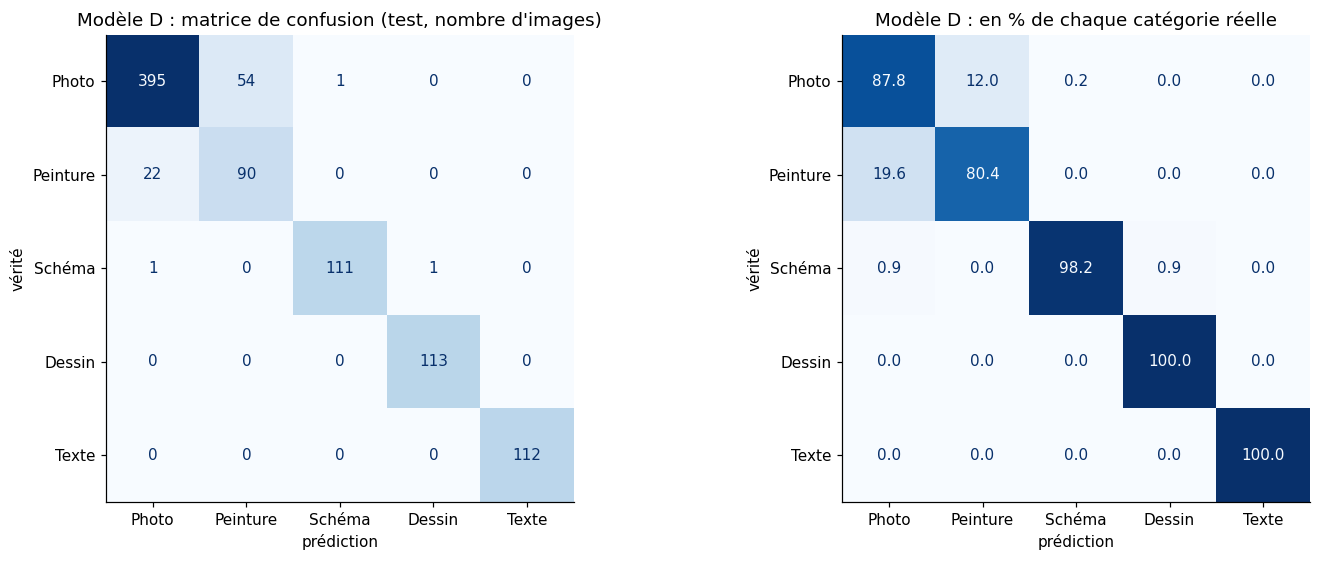

,images,précision (%),rappel (%),F1 (%)
"Modèle D, test",,,,
Photo,450,94.50,87.78,91.01
Peinture,112,62.50,80.36,70.31
Schéma,113,99.11,98.23,98.67
Dessin,113,99.12,100.00,99.56
Texte,112,100.00,100.00,100.00


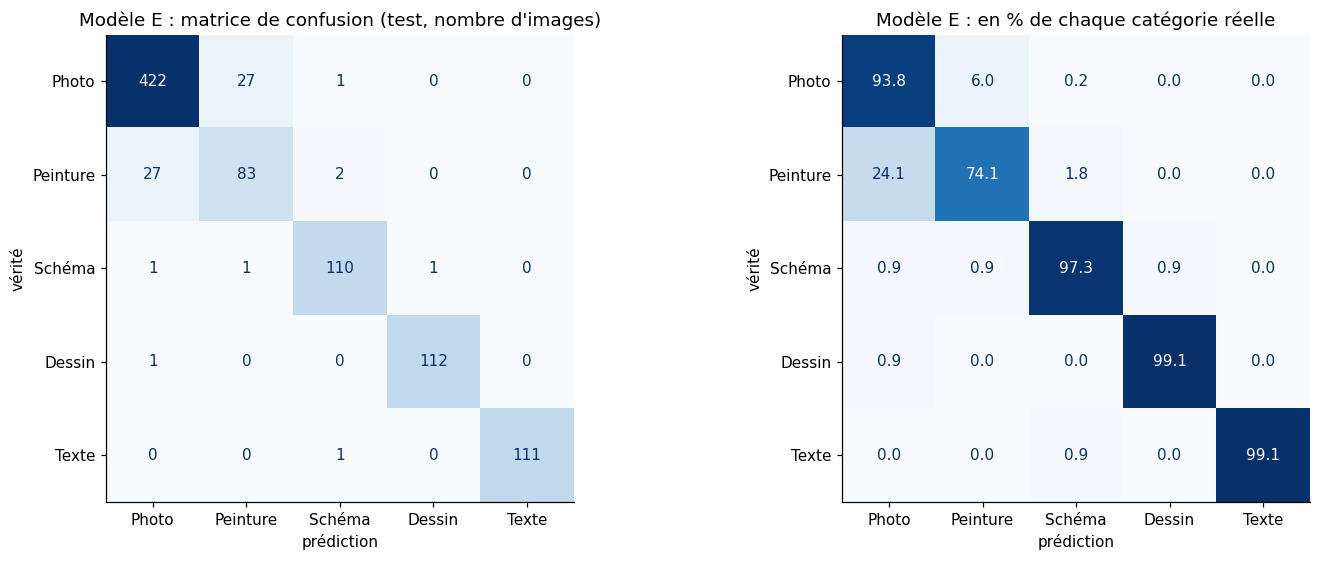

,images,précision (%),rappel (%),F1 (%)
"Modèle E, test",,,,
Photo,450,93.57,93.78,93.67
Peinture,112,74.77,74.11,74.44
Schéma,113,96.49,97.35,96.92
Dessin,113,99.12,99.12,99.12
Texte,112,100.00,99.11,99.55


,accuracy (%),accuracy équilibrée (%),F1 macro (%),perte équilibrée
Modèle D,91.222,93.273,91.910,0.158
Modèle E,93.111,92.690,92.739,0.195


In [ ]:
matricesMulti = {m: metrics.confusion_matrix(yMultiTest, ps["test"].argmax(axis=1), labels=list(range(NCATEGORIES)))
                 for m, ps in probasMulti.items()}
for m, cm in matricesMulti.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    metrics.ConfusionMatrixDisplay(cm, display_labels=CATEGORIESMULTI).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"{m} : matrice de confusion (test, nombre d'images)")
    metrics.ConfusionMatrixDisplay(100 * cm / cm.sum(axis=1, keepdims=True), display_labels=CATEGORIESMULTI).plot(
        ax=axes[1], cmap="Blues", colorbar=False, values_format=".1f")
    axes[1].set_title(f"{m} : en % de chaque catégorie réelle")
    for ax in axes:
        ax.set_xlabel("prédiction")
        ax.set_ylabel("vérité")
        ax.grid(False)
    plt.tight_layout()
    plt.show()
    precisionM, rappelM, f1M_, supportM = metrics.precision_recall_fscore_support(
        yMultiTest, probasMulti[m]["test"].argmax(axis=1), labels=list(range(NCATEGORIES)), zero_division=0)
    display(pd.DataFrame({"images": supportM, "précision (%)": 100 * precisionM, "rappel (%)": 100 * rappelM,
                          "F1 (%)": 100 * f1M_}, index=pd.Index(CATEGORIESMULTI, name=f"{m}, test")).round(2))
display(pd.DataFrame({m: indicateursMulti(yMultiTest, ps["test"]) for m, ps in probasMulti.items()}).T.round(3))

## 21. Le classifieur multiclasse comme filtre photo (section 18.5)

p(photo) du modèle multiclasse retenu, avec un seuil choisi sur la validation (F1 maximal), comparé au filtre binaire retenu sur le test, avec un test de McNemar sur les mêmes 900 images.

### Pourquoi ce choix et pas un autre : utiliser le multiclasse comme filtre photo

Le modèle multiclasse a appris à séparer peinture, dessin et photo séparément, ce qui l'aide sur les peintures réalistes. Le test de McNemar vérifie que la différence n'est pas due au hasard (p = 0,008).

<table>
<tr><th>Filtre (seuil retenu)</th><th>Accuracy test</th><th>Rappel photo</th><th>F1 photo</th><th>Erreurs sur peintures</th></tr>
<tr><td>Modèle C binaire (0,345)</td><td>92,44 %</td><td>96,44 %</td><td>92,74 %</td><td>48</td></tr><tr><td>Modèle D multiclasse (0,218)</td><td>94,44 %</td><td>97,56 %</td><td>94,61 %</td><td>38</td></tr>
</table>

In [ ]:
pPhotoVal, pPhotoTest = pMultiVal[:, 0], pMultiTest[:, 0]   # la photo est la catégorie 0
precisionsM, rappelsM, seuilsM = metrics.precision_recall_curve(yVal, pPhotoVal)
precisionsM, rappelsM = precisionsM[:len(seuilsM)], rappelsM[:len(seuilsM)]
f1M = 2 * precisionsM * rappelsM / np.clip(precisionsM + rappelsM, 1e-9, None)
seuilMulti = float(seuilsM[int(np.argmax(f1M))])
print(f"Seuil retenu sur p(photo), {choisiMulti} : {seuilMulti:.3f} (F1 {f1M.max():.2%} en validation)")

pBinaireTest = predictions[choisi]["test"]
filtres = pd.DataFrame({
    f"{choisi} binaire, seuil 0,5": indicateurs(yTest, pBinaireTest, 0.5),
    f"{choisi} binaire, seuil retenu ({seuil:.2f})": indicateurs(yTest, pBinaireTest, seuil),
    f"{choisiMulti} multiclasse, seuil 0,5": indicateurs(yTest, pPhotoTest, 0.5),
    f"{choisiMulti} multiclasse, seuil retenu ({seuilMulti:.2f})": indicateurs(yTest, pPhotoTest, seuilMulti)}).T
print(f"Tri entre photos et autres images sur le test ({len(yTest)} images) :")
display(filtres.round(3))

erreursFiltres = pd.DataFrame({
    f"{choisi} binaire": pd.Series((pBinaireTest >= seuil) != yTest).groupby(categories[idxTest]).sum(),
    f"{choisiMulti} multiclasse": pd.Series((pPhotoTest >= seuilMulti) != yTest).groupby(categories[idxTest]).sum(),
}).astype(int).reindex(CATEGORIESMULTI).rename_axis("catégorie")
print("Erreurs de tri par catégorie, chaque filtre à son seuil retenu :")
display(erreursFiltres)

erreursBinaire = (pBinaireTest >= seuil) != yTest
erreursMultiFiltre = (pPhotoTest >= seuilMulti) != yTest
seulBinaire = int(np.sum(erreursBinaire & ~erreursMultiFiltre))
seulMulti = int(np.sum(~erreursBinaire & erreursMultiFiltre))
pMcNemar = stats.binomtest(min(seulBinaire, seulMulti), seulBinaire + seulMulti, 0.5).pvalue \
    if seulBinaire + seulMulti else 1.0
print(f"Test de McNemar : {seulBinaire} images ratées par le binaire seul, {seulMulti} par le multiclasse seul, "
      f"p = {pMcNemar:.3f} → " + ("écart significatif au seuil de 5 %" if pMcNemar < 0.05 else "écart non significatif"))


def predireCategories(probas, seuilPhoto=None):
    """Sans seuil : catégorie la plus probable. Avec seuil : photo si p(photo) l'atteint, sinon la plus probable des autres."""
    if seuilPhoto is None:
        return probas.argmax(axis=1)
    return np.where(probas[:, 0] >= seuilPhoto, 0, 1 + probas[:, 1:].argmax(axis=1))


f1Macro = lambda vrai, pred: 100 * metrics.f1_score(vrai, pred, average="macro", labels=list(range(NCATEGORIES)),
                                                    zero_division=0)
regles = {"catégorie la plus probable": None, f"photo si p(photo) ≥ {seuilMulti:.3f}": seuilMulti}
comparaisonRegles = pd.DataFrame({nom: {"F1 macro validation (%)": f1Macro(yMultiVal, predireCategories(pMultiVal, s)),
                                        "F1 macro test (%)": f1Macro(yMultiTest, predireCategories(pMultiTest, s))}
                                  for nom, s in regles.items()}).T
display(comparaisonRegles.round(3))
regleRetenue = max(regles, key=lambda nom: round(comparaisonRegles.loc[nom, "F1 macro validation (%)"], 6))
seuilRegle = regles[regleRetenue]
print(f"Règle de décision retenue sur la validation : {regleRetenue}.")

Seuil retenu sur p(photo), Modèle D : 0.218 (F1 93.42% en validation)
Tri entre photos et autres images sur le test (900 images) :


,accuracy (%),précision photo (%),rappel photo (%),F1 photo (%),spécificité (%),AUC
"Modèle C binaire, seuil 0,5",92.333,90.275,94.889,92.524,89.778,0.981
"Modèle C binaire, seuil retenu (0.34)",92.444,89.300,96.444,92.735,88.444,0.981
"Modèle D multiclasse, seuil 0,5",91.333,94.498,87.778,91.014,94.889,0.981
"Modèle D multiclasse, seuil retenu (0.22)",94.444,91.841,97.556,94.612,91.333,0.981


Erreurs de tri par catégorie, chaque filtre à son seuil retenu :


,Modèle C binaire,Modèle D multiclasse
catégorie,,
Photo,16,11
Peinture,48,38
Schéma,4,1
Dessin,0,0
Texte,0,0


Test de McNemar : 30 images ratées par le binaire seul, 12 par le multiclasse seul, p = 0.008 → écart significatif au seuil de 5 %


,F1 macro validation (%),F1 macro test (%)
catégorie la plus probable,90.416,91.910
photo si p(photo) ≥ 0.218,92.268,93.681


Règle de décision retenue sur la validation : photo si p(photo) ≥ 0.218.


## 22. Sauvegarde du modèle multiclasse (section 18.6)

### Pourquoi ce choix et pas un autre : garder deux modèles sauvegardés

On garde le binaire et le multiclasse : le binaire est plus simple à déployer, le multiclasse est plus précis et donne en plus la catégorie.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Garder les deux</td><td>choix possible selon l'usage</td><td>deux fichiers à maintenir</td><td>oui</td></tr><tr><td>Garder seulement le meilleur</td><td>plus simple</td><td>perd une option de déploiement</td><td>non</td></tr>
</table>

In [ ]:
cheminMulti = DOSSIERTRAVAIL / "classifieurCategories.keras"
modeleMultiFinal.save(cheminMulti)
configurationMulti = {
    "modele": choisiMulti,
    "fichierModele": cheminMulti.name,
    "taille": int(tailleMulti),
    "categories": CATEGORIESMULTI,
    "pretraitement": configuration["pretraitement"],
    "poidsCategories": {CATEGORIESMULTI[k]: round(v, 4) for k, v in poidsCategories.items()},
    "hyperparametres": HPE if choisiMulti == "Modèle E" else HPD,
    "transfertApprentissage": False,
    "fineTuning": False,
    "augmentation": False,
    "seuilPhoto": seuilMulti,
    "regleDecision": regleRetenue,
    "seuilRegle": seuilRegle,
    "performancesTest": {k: round(float(v), 4) for k, v in indicateursMulti(yMultiTest, pMultiTest).items()},
    "versionTensorFlow": tf.__version__,
    "date": datetime.now().strftime("%d/%m/%Y %H:%M"),
}
with open(DOSSIERTRAVAIL / "configurationCategories.json", "w", encoding="utf8") as f:
    json.dump(configurationMulti, f, ensure_ascii=False, indent=2)
print(json.dumps(configurationMulti, ensure_ascii=False, indent=2))

{
  "modele": "Modèle D",
  "fichierModele": "classifieurCategories.keras",
  "taille": 128,
  "categories": [
    "Photo",
    "Peinture",
    "Schéma",
    "Dessin",
    "Texte"
  ],
  "pretraitement": "preparerImage : RGB sur fond blanc, redimensionnement bilinéaire en carré, pixels entre 0 et 255",
  "poidsCategories": {
    "Photo": 0.4,
    "Peinture": 1.6,
    "Schéma": 1.6,
    "Dessin": 1.6,
    "Texte": 1.6
  },
  "hyperparametres": {
    "lr": 0.0002,
    "dropout": 0.45,
    "l2": 0.0003,
    "neurones": 128,
    "filtres": 32,
    "convs": 1,
    "lot": 64,
    "taille": 128
  },
  "transfertApprentissage": false,
  "fineTuning": false,
  "augmentation": false,
  "seuilPhoto": 0.2181827425956726,
  "regleDecision": "photo si p(photo) ≥ 0.218",
  "seuilRegle": 0.2181827425956726,
  "performancesTest": {
    "accuracy (%)": 91.2222,
    "accuracy équilibrée (%)": 93.273,
    "F1 macro (%)": 91.9105,
    "perte équilibrée": 0.1584
  },
  "versionTensorFlow": "2.21.0",
  "date

## 23. Tableau récapitulatif (section 19)

### Pourquoi ce choix et pas un autre : le tableau récapitulatif

Le tableau sépare ce qui a servi à décider (validation) et la mesure finale (test). Ça évite de mélanger les deux dans le rapport.

<table>
<tr><th>Modèle</th><th>Tâche</th><th>Indicateur test</th><th>Retenu ?</th></tr>
<tr><td>A</td><td>photo ou autre</td><td>accuracy 90,67 %</td><td>non</td></tr><tr><td>B</td><td>photo ou autre</td><td>accuracy 92,78 %</td><td>non</td></tr><tr><td>C</td><td>photo ou autre</td><td>accuracy 92,33 %</td><td>oui (binaire)</td></tr><tr><td>D</td><td>5 catégories</td><td>F1 macro 91,91 %</td><td>oui (multiclasse)</td></tr><tr><td>E</td><td>5 catégories</td><td>F1 macro 92,74 %</td><td>non</td></tr>
</table>

In [ ]:
recapitulatifValidation = pd.DataFrame({
    "Modèle A": {"tâche": "photo ou autre", "architecture": "CNN 5 blocs, sans régularisation",
                 "indicateur de validation": f"erreur {erreurs.loc['Modèle A', 'validation']:.2f} %"},
    "Modèle B": {"tâche": "photo ou autre", "architecture": "CNN 5 blocs régularisé, réglage à la main",
                 "indicateur de validation": f"erreur {erreurs.loc['Modèle B', 'validation']:.2f} %"},
    "Modèle C": {"tâche": "photo ou autre", "architecture": "CNN 5 blocs régularisé, hyperparamètres cherchés",
                 "indicateur de validation": f"erreur {erreurs.loc['Modèle C', 'validation']:.2f} %"},
    "Modèle D": {"tâche": "5 catégories", "architecture": "CNN 5 blocs, BatchNormalization",
                 "indicateur de validation": "F1 macro {:.2f} %".format(
                     indicateursMulti(yMultiVal, probasMulti["Modèle D"]["validation"])["F1 macro (%)"])},
    "Modèle E": {"tâche": "5 catégories", "architecture": "CNN 5 blocs, GroupNormalization",
                 "indicateur de validation": "F1 macro {:.2f} %".format(
                     indicateursMulti(yMultiVal, probasMulti["Modèle E"]["validation"])["F1 macro (%)"])},
}).T
recapitulatifValidation["retenu"] = ["oui" if m in (choisi, choisiMulti) else "" for m in recapitulatifValidation.index]
print("Entraînement et validation (décisions) :")
display(recapitulatifValidation)
recapitulatifTest = pd.DataFrame({
    **{m: {"indicateur de test": f"accuracy {100 - erreurs.loc[m, 'test']:.2f} % (seuil 0,5)"} for m in predictions},
    **{m: {"indicateur de test": "F1 macro {:.2f} %".format(indicateursMulti(yMultiTest, ps["test"])["F1 macro (%)"])}
       for m, ps in probasMulti.items()}}).T
print("Test (mesure finale, aucune décision) :")
display(recapitulatifTest)

Entraînement et validation (décisions) :


,tâche,architecture,indicateur de validation,retenu
Modèle A,photo ou autre,"CNN 5 blocs, sans régularisation",erreur 7.67 %,
Modèle B,photo ou autre,"CNN 5 blocs régularisé, réglage à la main",erreur 6.78 %,
Modèle C,photo ou autre,"CNN 5 blocs régularisé, hyperparamètres cherchés",erreur 5.89 %,oui
Modèle D,5 catégories,"CNN 5 blocs, BatchNormalization",F1 macro 90.42 %,oui
Modèle E,5 catégories,"CNN 5 blocs, GroupNormalization",F1 macro 92.14 %,


Test (mesure finale, aucune décision) :


,indicateur de test
Modèle A,"accuracy 90.67 % (seuil 0,5)"
Modèle B,"accuracy 92.78 % (seuil 0,5)"
Modèle C,"accuracy 92.33 % (seuil 0,5)"
Modèle D,F1 macro 91.91 %
Modèle E,F1 macro 92.74 %


## Tableau comparatif général des cinq modèles

<table>
<tr><th>Modèle</th><th>Tâche</th><th>Normalisation</th><th>Paramètres</th><th>Réglage</th><th>Indicateur test</th><th>Retenu ?</th></tr>
<tr><td>A</td><td>photo ou autre</td><td>GroupNormalization</td><td>environ 98 000</td><td>manuel, petit réseau</td><td>accuracy 90,67 %, AUC 0,966</td><td>non</td></tr><tr><td>B</td><td>photo ou autre</td><td>GroupNormalization</td><td>environ 1 million</td><td>manuel, forte régularisation</td><td>accuracy 92,78 %, AUC 0,979</td><td>non</td></tr><tr><td>C</td><td>photo ou autre</td><td>GroupNormalization</td><td>environ 1,1 million</td><td>grille + aléatoire</td><td>accuracy 92,44 % (seuil 0,345), AUC 0,981</td><td>oui</td></tr><tr><td>D</td><td>5 catégories</td><td>BatchNormalization</td><td>proche de E</td><td>manuel + contrôle des zigzags</td><td>F1 macro 91,91 %</td><td>oui</td></tr><tr><td>E</td><td>5 catégories</td><td>GroupNormalization</td><td>proche de B</td><td>manuel</td><td>F1 macro 92,74 %</td><td>non</td></tr>
</table>

Ce qu'on retient : agrandir le réseau (A vers B) a fait gagner environ 2 points, la recherche d'hyperparamètres (B vers C) surtout en perte de validation et en AUC. En multiclasse, D est retenu sur la perte de validation, et utilisé comme filtre photo il fait mieux que le meilleur modèle binaire.

## 24. Export des résultats pour le rapport

Tous les résultats chiffrés de cette exécution (historiques d'entraînement, recherche, tableaux, matrices de confusion) sont réunis dans un fichier `resultats_rapport.zip`, enregistré sur Drive et proposé au téléchargement. C'est ce fichier (ou ce notebook exécuté) qui permet de mettre à jour le rapport consolidé.

### Pourquoi ce choix et pas un autre : un export zip

Un seul fichier zip contient tous les chiffres et tableaux. On peut écrire le rapport sans relancer le notebook.

<table>
<tr><th>Option</th><th>Avantages</th><th>Inconvénients</th><th>Retenue ?</th></tr>
<tr><td>Un zip sur Drive</td><td>tout au même endroit, téléchargeable</td><td>à régénérer si on relance</td><td>oui</td></tr><tr><td>Copier les chiffres à la main</td><td>rien à coder</td><td>erreurs de recopie</td><td>non</td></tr>
</table>

In [ ]:
dossierExport = DOSSIERTRAVAIL / "export_rapport"
if dossierExport.exists():
    shutil.rmtree(dossierExport)
dossierExport.mkdir(parents=True)
for nom, historique in [("A", historiqueA), ("B", historiqueB), ("C", historiqueC), ("D", historiqueD), ("E", historiqueE)]:
    historique.to_csv(dossierExport / f"historique{nom}.csv")
recherche.to_csv(dossierExport / "rechercheHyperparametres.csv", index=False)
if fichierTentatives.exists():
    shutil.copy2(fichierTentatives, dossierExport / "tentativesD.csv")
comparaison.to_csv(dossierExport / "binaire_validation.csv")
tableauTest.to_csv(dossierExport / "binaire_test.csv")
robustesse.to_csv(dossierExport / "binaire_robustesse.csv")
comparaisonMulti.to_csv(dossierExport / "multiclasse_validation.csv", index=False)
filtres.to_csv(dossierExport / "filtres_photo_test.csv")
resume = {
    "date": datetime.now().strftime("%d/%m/%Y %H:%M"),
    "versions": {"tensorflow": tf.__version__, "keras": keras.__version__, "gpu": bool(GPU)},
    "binaire": {
        "epoquesRetenues": {"Modèle A": int(epoqueA), "Modèle B": int(epoqueB), "Modèle C": int(epoqueC)},
        "hpC": hpC, "meilleurEssai": {"methode": str(meilleur["méthode"]), "essai": int(meilleur["essai"])},
        "pertesValidation": pertesValidation, "choisi": choisi, "seuil": seuil,
        "matricesConfusionTest_seuil05": {m: cm.tolist() for m, cm in matricesBinaires.items()},
        "matriceConfusionTest_choisi_seuilRetenu": metrics.confusion_matrix(yTest, predTest).tolist(),
    },
    "multiclasse": {
        "epoquesRetenues": {"Modèle D": int(epoqueD), "Modèle E": int(epoqueE)},
        "pasDepartD": float(historiqueD["pasDepart"].iloc[0]),
        "pertesValidationEquilibrees": pertesValMulti, "choisi": choisiMulti,
        "indicateursTest": {m: {k: float(v) for k, v in indicateursMulti(yMultiTest, ps["test"]).items()}
                            for m, ps in probasMulti.items()},
        "matricesConfusionTest": {m: cm.tolist() for m, cm in matricesMulti.items()},
        "seuilPhotoMulti": seuilMulti, "mcNemar": {"seulBinaire": seulBinaire, "seulMulti": seulMulti, "p": float(pMcNemar)},
    },
}
with open(dossierExport / "resume.json", "w", encoding="utf8") as f:
    json.dump(resume, f, ensure_ascii=False, indent=2, default=str)
archive = shutil.make_archive(str(DOSSIERTRAVAIL / "resultats_rapport"), "zip", dossierExport)
print("Export enregistré :", archive)
try:
    from google.colab import files
    files.download(archive)
except Exception:
    pass

Export enregistré : /content/drive/MyDrive/Project1_Livrable1/resultats_reproduction/resultats_rapport.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>